In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display, HTML

In [ ]:
col_def_path = "/content/drive/MyDrive/columns_description.csv"
col_df = pd.read_csv(col_def_path)
display(HTML(f'<div style="max-height: 300px; overflow-y: auto;">{col_df.to_html()}</div>'))

,Unnamed: 0,Table,Row,Description,Special
0,1,application_data,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_data,TARGET,"Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)",NaN
2,5,application_data,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_data,CODE_GENDER,Gender of the client,NaN
4,7,application_data,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_data,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_data,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_data,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_data,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_data,AMT_ANNUITY,Loan annuity,NaN


In [ ]:
path = "/content/drive/MyDrive/application_data_1.csv"
#path = "application_data_1.csv"
df = pd.read_csv(path)

In [ ]:
df.head(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,AMT_REQ_CREDIT_BUREAU_YEAR,CAR_N_REALTY,AFFORD,PHONE_ALL,DOCUMENT_ALL,REGION_WRONG,CITY_WRONG,EXT_SOURCE_ALL,COM_ANNUITY,PERIOD
0,117337,0,Cash loans,M,0,1,1,760846.5,4050000.0,146002.5,...,0.0,1,614844.0,3,1,0,0,1.691343,146002.5,27.739251
1,120926,0,Cash loans,M,1,0,2,783000.0,4050000.0,258025.5,...,0.0,1,524974.5,2,1,2,3,2.015500,258025.5,15.696123
2,228135,0,Cash loans,M,0,0,2,864900.0,4050000.0,102384.0,...,0.0,0,762516.0,3,1,0,0,1.402491,102384.0,39.556962
3,238782,0,Cash loans,M,1,1,1,931365.0,4050000.0,102514.5,...,0.0,2,828850.5,3,1,0,2,1.818799,102514.5,39.506606
4,240007,0,Cash loans,M,0,0,0,587250.0,4050000.0,106969.5,...,0.0,0,480280.5,3,1,2,2,0.663432,106969.5,37.861260


In [ ]:
df.shape

(307511, 80)

In [ ]:
df_processed = df.copy()

In [ ]:
# Get numerical columns (int, float)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Get categorical columns (object, typically strings)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

In [ ]:
path = "/content/drive/MyDrive/CREDIT_HISTORY.csv"
df_history = pd.read_csv(path)

In [ ]:
df_history.head(5)

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [ ]:
df_history.shape

(1465325, 17)

In [ ]:
df_history = df_history[df_history['SK_ID_CURR'].isin(df_processed['SK_ID_CURR'])]

# **Feature Engineering**

### **缺失值補值**

In [ ]:
# Compute the mean of 'OWN_CAR_AGE' (ignoring NaNs)
mean_value = df_processed['OWN_CAR_AGE'].mean()

df_processed.loc[df_processed['OWN_CAR_AGE']== 0, 'OWN_CAR_AGE'] = 0.1
df_processed.loc[((df_processed['OWN_CAR_AGE'].isna()) & (df_processed['FLAG_OWN_CAR'] == 0)), 'OWN_CAR_AGE'] = 0
df_processed.loc[((df_processed['OWN_CAR_AGE'].isna()) & (df_processed['FLAG_OWN_CAR'] == 1)), 'OWN_CAR_AGE'] = mean_value

In [ ]:
df_processed = df_processed[~(df_processed['CODE_GENDER'].isna())]

In [ ]:
mean_value = df_processed.loc[(df_processed['DAYS_BIRTH']/365 <= -20) & (df_processed['DAYS_BIRTH']/365 >= -30),'DAYS_LAST_PHONE_CHANGE'].mean()
df_processed.loc[df_processed['DAYS_LAST_PHONE_CHANGE'].isna(), 'DAYS_LAST_PHONE_CHANGE'] = mean_value

In [ ]:
def split_level(x):
  if x >= 0 and x < 0.25:
    return 1
  elif x >= 0.25 and x < 0.5:
    return 2
  elif x >= 0.5 and x < 0.75:
    return 3
  elif x >= 0.75 and x < 1:
    return 4
  else:
    return 0

In [ ]:
df_processed['EXT_SOURCE_1_level'] = df_processed['EXT_SOURCE_1'].apply(split_level)
df_processed['EXT_SOURCE_2_level'] = df_processed['EXT_SOURCE_2'].apply(split_level)
df_processed['EXT_SOURCE_3_level'] = df_processed['EXT_SOURCE_3'].apply(split_level)

In [ ]:
all_columns = df_processed.columns.tolist()
to_remove = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
all_columns_adj = [col for col in all_columns if col not in to_remove]
df_processed = df_processed[all_columns_adj]

In [ ]:
df_processed.loc[df_processed['AMT_ANNUITY'].isna(), 'AMT_ANNUITY'] = df_processed.loc[df_processed['AMT_ANNUITY'].isna(), 'AMT_CREDIT']

In [ ]:
df_processed.loc[df_processed['AMT_GOODS_PRICE'].isna(), 'AMT_GOODS_PRICE'] = 0

In [ ]:
mode_value = df_processed['NAME_TYPE_SUITE'].mode()[0]
df_processed.loc[df_processed['NAME_TYPE_SUITE'].isna(), 'NAME_TYPE_SUITE'] = mode_value

In [ ]:
mode_value = df_processed['CNT_FAM_MEMBERS'].mode()[0]
df_processed.loc[df_processed['CNT_FAM_MEMBERS'].isna(), 'CNT_FAM_MEMBERS'] = mode_value

In [ ]:
df_processed = df_processed[~(df_processed['AMT_REQ_CREDIT_BUREAU_QRT'] > 200)]
df_processed[df_processed['AMT_REQ_CREDIT_BUREAU_QRT'] > 200]

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,PHONE_ALL,DOCUMENT_ALL,REGION_WRONG,CITY_WRONG,EXT_SOURCE_ALL,COM_ANNUITY,PERIOD,EXT_SOURCE_1_level,EXT_SOURCE_2_level,EXT_SOURCE_3_level


In [ ]:
req_missing_cols = [
    'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_YEAR'
]

# df_imputed = df_processed.copy()
# Add missing indicator
df_processed['AMT_REQ_CREDIT_BUREAU_is_missing'] = df_processed['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().astype(int)

for col in req_missing_cols:
  # Impute with 0
  df_processed[col] = df_processed[col].fillna(0)

<ipython-input-24-d6aa31d2a6af>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed['AMT_REQ_CREDIT_BUREAU_is_missing'] = df_processed['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().astype(int)
<ipython-input-24-d6aa31d2a6af>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed[col] = df_processed[col].fillna(0)


In [ ]:
df_processed['AFFORD'] = df_processed['AMT_INCOME_TOTAL'] - df_processed['AMT_ANNUITY']

<ipython-input-25-0586776c5645>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_processed['AFFORD'] = df_processed['AMT_INCOME_TOTAL'] - df_processed['AMT_ANNUITY']


In [ ]:
df_processed.loc[df_processed['NAME_TYPE_SUITE'].isna(), 'NAME_TYPE_SUITE'] = 'Unaccompanied'

In [ ]:
non_working_list = ['Pensioner', 'Unemployed', 'Student', 'Maternity leave']
df_processed.loc[(df_processed['OCCUPATION_TYPE'].isna()) & (df_processed['NAME_INCOME_TYPE'].isin(non_working_list)), 'OCCUPATION_TYPE'] = 'No Work'
df_processed.loc[df_processed['OCCUPATION_TYPE'].isna(), 'OCCUPATION_TYPE'] = 'Working'

### **Adjust Features**

In [ ]:
# Flip sign for all columns starting with 'DAYS_'
days_cols = [col for col in df_processed.columns if col.startswith('DAYS_')]
df_processed[days_cols] = df_processed[days_cols] * -1

### **Add New Feature**

**check df_history**

In [ ]:
len(df_history.loc[df_history['SK_ID_CURR'].isin(df_processed['SK_ID_CURR']), 'SK_ID_CURR'].unique()) / df_processed.shape[0]

0.8568501837338623

**Past loan count**

In [ ]:
# Step 1: Get loan counts per SK_ID_CURR
df_cnt = df_history['SK_ID_CURR'].value_counts().reset_index()
df_cnt.columns = ['SK_ID_CURR', 'past_loan_count']

# Step 3: Merge with df_processed
df_processed = pd.merge(df_processed, df_cnt, on='SK_ID_CURR', how='left')

# Step 4: Fill NaNs in 'past_loan_count'
df_processed['past_loan_count'] = df_processed['past_loan_count'].fillna(0)

# Step 5: Double-check if column exists

**Active loan count**

In [ ]:
df_cnt = df_history.groupby('SK_ID_CURR')['CREDIT_ACTIVE'].value_counts().reset_index(name='count')
df_active_cnt = df_cnt[df_cnt['CREDIT_ACTIVE'] == 'Active'][['SK_ID_CURR', 'count']]
merged_df = pd.merge(df_processed, df_active_cnt, on='SK_ID_CURR', how='left')
merged_df['count'] = merged_df['count'].fillna(0)
merged_df.rename(columns={'count': 'active_loan_count'}, inplace=True)
df_processed = merged_df
df_processed.head(3)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,CITY_WRONG,EXT_SOURCE_ALL,COM_ANNUITY,PERIOD,EXT_SOURCE_1_level,EXT_SOURCE_2_level,EXT_SOURCE_3_level,AMT_REQ_CREDIT_BUREAU_is_missing,past_loan_count,active_loan_count
0,117337,0,Cash loans,M,0,1,1,760846.5,4050000.0,146002.5,...,0,1.691343,146002.5,27.739251,1,3,4,0,4.0,1.0
1,120926,0,Cash loans,M,1,0,2,783000.0,4050000.0,258025.5,...,3,2.015500,258025.5,15.696123,4,3,3,0,3.0,1.0
2,228135,0,Cash loans,M,0,0,2,864900.0,4050000.0,102384.0,...,0,1.402491,102384.0,39.556962,2,2,4,0,2.0,0.0


**Active loan ratio**

In [ ]:
df_processed['active_loan_ratio'] = df_processed['active_loan_count'] / df_processed['past_loan_count']
df_processed['active_loan_ratio'] = df_processed['active_loan_ratio'].fillna(0)
df_processed['active_loan_ratio'].describe()

,active_loan_ratio
count,307510.000000
mean,0.353854
std,0.320026
min,0.000000
25%,0.000000
50%,0.333333
75%,0.500000
max,1.000000


**Overdue count**

In [ ]:
df_history['is_overdue'] = df_history['CREDIT_DAY_OVERDUE'] > 0
df_overdue = df_history.groupby('SK_ID_CURR')['is_overdue'].sum().reset_index(name='overdue_count')
df_overdue = df_overdue[['SK_ID_CURR', 'overdue_count']]
merged_df = pd.merge(df_processed, df_overdue, on='SK_ID_CURR', how='left')
merged_df['overdue_count'] = merged_df['overdue_count'].fillna(0)
df_processed = merged_df
df_processed.head(3)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,COM_ANNUITY,PERIOD,EXT_SOURCE_1_level,EXT_SOURCE_2_level,EXT_SOURCE_3_level,AMT_REQ_CREDIT_BUREAU_is_missing,past_loan_count,active_loan_count,active_loan_ratio,overdue_count
0,117337,0,Cash loans,M,0,1,1,760846.5,4050000.0,146002.5,...,146002.5,27.739251,1,3,4,0,4.0,1.0,0.250000,0.0
1,120926,0,Cash loans,M,1,0,2,783000.0,4050000.0,258025.5,...,258025.5,15.696123,4,3,3,0,3.0,1.0,0.333333,0.0
2,228135,0,Cash loans,M,0,0,2,864900.0,4050000.0,102384.0,...,102384.0,39.556962,2,2,4,0,2.0,0.0,0.000000,0.0


**Overdue ratio**

In [ ]:
df_processed['overdue_ratio'] = df_processed['overdue_count'] / df_processed['past_loan_count']
df_processed['overdue_ratio'] = df_processed['overdue_ratio'].fillna(0)
df_processed[df_processed['overdue_ratio'] > 0]['overdue_ratio'].describe()

,overdue_ratio
count,3397.000000
mean,0.230851
std,0.207405
min,0.019608
25%,0.100000
50%,0.166667
75%,0.250000
max,1.000000


**Average Overdue Day**

In [ ]:
df_overdue_day = df_history.groupby('SK_ID_CURR')['CREDIT_DAY_OVERDUE'].mean().reset_index(name='avg_overdue_day')
merged_df = pd.merge(df_processed, df_overdue_day, on='SK_ID_CURR', how='left')
merged_df['avg_overdue_day'] = merged_df['avg_overdue_day'].fillna(0)
df_processed = merged_df
df_processed['avg_overdue_day'].describe()

,avg_overdue_day
count,307510.000000
mean,0.887583
std,23.908395
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2776.000000


**Avg Prolong Count**

In [ ]:
# df_history[(df_history['CREDIT_ACTIVE'] == 'Active') & (df_history['CNT_CREDIT_PROLONG'] > 0) & (df_history['CREDIT_DAY_OVERDUE'] > 0)][['CREDIT_ACTIVE', 'CNT_CREDIT_PROLONG', 'CREDIT_DAY_OVERDUE']]
df_avg_prolong = df_history.groupby('SK_ID_CURR')['CNT_CREDIT_PROLONG'].mean().reset_index(name='avg_prolong_count')
merged_df = pd.merge(df_processed, df_avg_prolong, on='SK_ID_CURR', how='left')
merged_df['avg_prolong_count'] = merged_df['avg_prolong_count'].fillna(0)
df_processed = merged_df
df_processed['avg_prolong_count'].describe()

,avg_prolong_count
count,307510.000000
mean,0.006786
std,0.061600
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,6.000000


In [ ]:
df_processed['SK_ID_CURR'].isna().sum()

np.int64(0)

### **Add New Feature - part 2**

**現有還未還款的 amount 總額**

**Total Active Debt**

In [ ]:
# active credit >> AMT_CREDIT_SUM_DEBT
###### AMT_CREDIT_SUM_DEBT == null >> credit card:0, others: AMT_CREDIT_SUM
########### add is_credit_debt_missing = 1
###### AMT_CREDIT_SUM_DEBT < 0 >> all credit card (額度增加)，不能計算

In [ ]:
df_history['is_credit_debt_missing'] = 0
df_history.loc[(df_history['AMT_CREDIT_SUM_DEBT'].isna()) & (df_history['CREDIT_ACTIVE'] == 'Active'), 'is_credit_debt_missing'] = 1

In [ ]:
df_history.loc[df_history['is_credit_debt_missing'] == 1, 'AMT_CREDIT_SUM_DEBT'] = df_history[df_history['is_credit_debt_missing'] == 1]['AMT_CREDIT_SUM']
df_history.loc[(df_history['is_credit_debt_missing'] == 1) & (df_history['CREDIT_TYPE'] == 'Credit card'), 'AMT_CREDIT_SUM_DEBT'] = 0

In [ ]:
df_sum_debt = df_history[(df_history['CREDIT_ACTIVE'] == 'Active') & (df_history['AMT_CREDIT_SUM_DEBT'] > 0)].groupby('SK_ID_CURR')['AMT_CREDIT_SUM_DEBT'].sum().reset_index(name='total_active_debt_amt')
merged_df = pd.merge(df_processed, df_sum_debt, on='SK_ID_CURR', how='left')
merged_df['total_active_debt_amt'] = merged_df['total_active_debt_amt'].fillna(0)
df_processed = merged_df
df_processed['total_active_debt_amt'].describe().apply(lambda x: f"{x:,.0f}")

,total_active_debt_amt
count,"307,510"
mean,"671,357"
std,"1,737,810"
min,0
25%,0
50%,"135,178"
75%,"698,973"
max,"334,498,331"


**Closed but with Debt Amount**

In [ ]:
# Not Active >>
####### AMT_CREDIT_SUM_DEBT > 0 >> 'is_closed_outstanding_debt' = 1
####### AMT_CREDIT_SUM_DEBT < 0 >> credit card

In [ ]:
df_history['is_closed_outstanding_debt'] = 0
df_history.loc[(df_history['AMT_CREDIT_SUM_DEBT'] > 0) & (df_history['CREDIT_ACTIVE'] == 'Closed'), 'is_closed_outstanding_debt'] = 1

In [ ]:
df_sum_debt = df_history[(df_history['CREDIT_ACTIVE'] != 'Active') & (df_history['AMT_CREDIT_SUM_DEBT'] > 0)].groupby('SK_ID_CURR')['AMT_CREDIT_SUM_DEBT'].sum().reset_index(name='total_closed_debt_amt')
merged_df = pd.merge(df_processed, df_sum_debt, on='SK_ID_CURR', how='left')
merged_df['total_closed_debt_amt'] = merged_df['total_closed_debt_amt'].fillna(0)
df_processed = merged_df
df_processed['total_closed_debt_amt'].describe().apply(lambda x: f"{x:,.0f}")

,total_closed_debt_amt
count,"307,510"
mean,"8,672"
std,"177,651"
min,0
25%,0
50%,0
75%,0
max,"37,610,902"


**Closed Outstanding Debt Count**

In [ ]:
df_cnt_active_debt = df_history.groupby('SK_ID_CURR')['is_closed_outstanding_debt'].sum().reset_index(name='outstanding_closed_debt_cnt')
merged_df = pd.merge(df_processed, df_cnt_active_debt, on='SK_ID_CURR', how='left')
merged_df['outstanding_closed_debt_cnt'] = merged_df['outstanding_closed_debt_cnt'].fillna(0)
df_processed = merged_df
df_processed['outstanding_closed_debt_cnt'].describe().apply(lambda x: f"{x:,.0f}")

,outstanding_closed_debt_cnt
count,"307,510"
mean,0
std,0
min,0
25%,0
50%,0
75%,0
max,6


**此筆借貸比過去金額高 or 低（高多少、低多少）**

**各種 credit_type 的 past_loan_count, avg_loan_count, avg_loan_ratio, avg_credit_amount, overdue_count...**

In [ ]:
credit_type_list = list(df_history['CREDIT_TYPE'].unique())
credit_type_list

['Consumer credit',
 'Credit card',
 'Mortgage',
 'Car loan',
 'Microloan',
 'Loan for working capital replenishment',
 'Loan for business development',
 'Unknown type of loan',
 'Another type of loan',
 'Real estate loan',
 'Loan for the purchase of equipment',
 'Cash loan (non-earmarked)',
 'Mobile operator loan',
 'Interbank credit',
 'Loan for purchase of shares (margin lending)']

In [ ]:
(df_processed.isna().sum() > 0).sum()

np.int64(0)

In [ ]:
added_feature_list = []

for t in credit_type_list:
  # past_loan_count
  df_cnt = (
        df_history[df_history['CREDIT_TYPE'] == t]
        .groupby('SK_ID_CURR')
        .size()
        .reset_index(name='past_loan_count_' + t)
    )
  merged_df = pd.merge(df_processed, df_cnt, on='SK_ID_CURR', how='left')
  # print(merged_df)
  merged_df['past_loan_count' +'_' +  t] = merged_df['past_loan_count' + '_' + t].fillna(0)
  df_processed = merged_df
  added_feature_list.append('past_loan_count' + '_' + t)

  # active loan count
  df_cnt = df_history[df_history['CREDIT_TYPE'] == t].groupby('SK_ID_CURR')['CREDIT_ACTIVE'].value_counts().reset_index(name='count' + '_' + t)
  df_active_cnt = df_cnt[df_cnt['CREDIT_ACTIVE'] == 'Active'][['SK_ID_CURR', 'count' +'_' +  t]]
  merged_df = pd.merge(df_processed, df_active_cnt, on='SK_ID_CURR', how='left')
  merged_df['count' +'_' +  t] = merged_df['count' + '_' + t].fillna(0)
  merged_df.rename(columns={'count_' + t : 'active_loan_count' + '_' + t}, inplace=True)
  df_processed = merged_df
  added_feature_list.append('active_loan_count' +'_' +  t)

  # #active loan ratio
  df_processed['active_loan_ratio' + '_' + t] = 0
  df_processed['active_loan_ratio' + '_' + t] = df_processed['active_loan_count' +'_' +  t] / df_processed['past_loan_count' +'_' +  t]
  df_processed['active_loan_ratio' + '_' + t] = df_processed['active_loan_ratio' +'_' +  t].fillna(0)
  added_feature_list.append('active_loan_ratio' + '_' + t)

  # #overdue_count
  df_history['is_overdue'] = df_history['CREDIT_DAY_OVERDUE'] > 0
  df_overdue = df_history[df_history['CREDIT_TYPE'] == t].groupby('SK_ID_CURR')['is_overdue'].sum().reset_index(name='overdue_count' +'_' +  t)
  df_overdue = df_overdue[['SK_ID_CURR', 'overdue_count' +'_' +  t]]
  merged_df = pd.merge(df_processed, df_overdue, on='SK_ID_CURR', how='left')
  merged_df['overdue_count' +'_' +  t] = merged_df['overdue_count' +'_' +  t].fillna(0)
  df_processed = merged_df
  added_feature_list.append('overdue_count' +'_' +  t)

  # #overdue ratio
  df_processed['overdue_ratio' +'_' +  t] = 0
  df_processed['overdue_ratio' +'_' +  t] = df_processed['overdue_count' +'_' +  t] / df_processed['past_loan_count' +'_' +  t]
  df_processed['overdue_ratio' + '_' + t] = df_processed['overdue_ratio' + '_' + t].fillna(0)
  added_feature_list.append('overdue_ratio' +'_' +  t)

  # #avg_credit_amount
  df_avg_credit_amount = df_history[df_history['CREDIT_TYPE'] == t].groupby('SK_ID_CURR')['AMT_CREDIT_SUM'].mean().reset_index(name='avg_credit_amount' + '_' + t)
  merged_df = pd.merge(df_processed, df_avg_credit_amount, on='SK_ID_CURR', how='left')
  merged_df['avg_credit_amount' +'_' +  t] = merged_df['avg_credit_amount' +'_' +  t].fillna(0)
  df_processed = merged_df
  added_feature_list.append('avg_credit_amount' +'_' +  t)

  # #active_debt_amount
  df_sum_debt = df_history[(df_history['CREDIT_ACTIVE'] == 'Active') & (df_history['AMT_CREDIT_SUM_DEBT'] > 0) & (df_history['CREDIT_TYPE'] == t)].groupby('SK_ID_CURR')['AMT_CREDIT_SUM_DEBT'].sum().reset_index(name='total_active_debt_amt' +'_' +  t)
  merged_df = pd.merge(df_processed, df_sum_debt, on='SK_ID_CURR', how='left')
  merged_df['total_active_debt_amt' +'_' +  t] = merged_df['total_active_debt_amt' +'_' +  t].fillna(0)
  df_processed = merged_df
  added_feature_list.append('total_active_debt_amt' +'_' +  t)

  # #closed_debt_amount
  df_sum_debt = df_history[(df_history['CREDIT_ACTIVE'] != 'Active') & (df_history['AMT_CREDIT_SUM_DEBT'] > 0) & (df_history['CREDIT_TYPE'] == t)].groupby('SK_ID_CURR')['AMT_CREDIT_SUM_DEBT'].sum().reset_index(name='total_closed_debt_amt' +'_' +  t)
  merged_df = pd.merge(df_processed, df_sum_debt, on='SK_ID_CURR', how='left')
  merged_df['total_closed_debt_amt' +'_' +  t] = merged_df['total_closed_debt_amt' +'_' +  t].fillna(0)
  df_processed = merged_df
  added_feature_list.append('total_closed_debt_amt' +'_' +  t)

  # #closed_debt_count
  df_cnt_active_debt = df_history[df_history['CREDIT_TYPE'] == t].groupby('SK_ID_CURR')['is_closed_outstanding_debt'].sum().reset_index(name='outstanding_closed_debt_cnt' +'_' +  t)
  merged_df = pd.merge(df_processed, df_cnt_active_debt, on='SK_ID_CURR', how='left')
  merged_df['outstanding_closed_debt_cnt' +'_' +  t] = merged_df['outstanding_closed_debt_cnt' +'_' +  t].fillna(0)
  df_processed = merged_df
  added_feature_list.append('outstanding_closed_debt_cnt' +'_' +  t)

In [ ]:
# assert df_processed['SK_ID_CURR'].is_unique, "df_processed SK_ID_CURR has duplicates!"
# assert df_cnt['SK_ID_CURR'].is_unique, "df_cnt SK_ID_CURR has duplicates!"

In [ ]:
df_processed.isna().sum()

,0
SK_ID_CURR,0
TARGET,0
NAME_CONTRACT_TYPE,0
CODE_GENDER,0
FLAG_OWN_CAR,0
...,...
overdue_ratio_Loan for purchase of shares (margin lending),0
avg_credit_amount_Loan for purchase of shares (margin lending),0
total_active_debt_amt_Loan for purchase of shares (margin lending),0
total_closed_debt_amt_Loan for purchase of shares (margin lending),0


In [ ]:
added_feature_list

['past_loan_count_Consumer credit',
 'active_loan_count_Consumer credit',
 'active_loan_ratio_Consumer credit',
 'overdue_count_Consumer credit',
 'overdue_ratio_Consumer credit',
 'avg_credit_amount_Consumer credit',
 'total_active_debt_amt_Consumer credit',
 'total_closed_debt_amt_Consumer credit',
 'outstanding_closed_debt_cnt_Consumer credit',
 'past_loan_count_Credit card',
 'active_loan_count_Credit card',
 'active_loan_ratio_Credit card',
 'overdue_count_Credit card',
 'overdue_ratio_Credit card',
 'avg_credit_amount_Credit card',
 'total_active_debt_amt_Credit card',
 'total_closed_debt_amt_Credit card',
 'outstanding_closed_debt_cnt_Credit card',
 'past_loan_count_Mortgage',
 'active_loan_count_Mortgage',
 'active_loan_ratio_Mortgage',
 'overdue_count_Mortgage',
 'overdue_ratio_Mortgage',
 'avg_credit_amount_Mortgage',
 'total_active_debt_amt_Mortgage',
 'total_closed_debt_amt_Mortgage',
 'outstanding_closed_debt_cnt_Mortgage',
 'past_loan_count_Car loan',
 'active_loan_count_

**剩下的 loan 平均剩幾天到期、即將到期有幾個、還有很久的有幾個**

### **Add new features 3**

In [ ]:
bins = [20, 30, 40, 50, 60, 70]
labels = ['20-30', '30-40', '40-50', '50-60', '60-70']
temp_df = df_processed.copy()

temp_df['age_group'] = pd.cut(df_processed['DAYS_BIRTH'] / 365, bins=bins, labels=labels)

temp_df['age_gender_group'] = temp_df['age_group'].astype(str) + '_' + temp_df['CODE_GENDER']
temp_df['age_gender_group']

,age_gender_group
0,30-40_M
1,40-50_M
2,40-50_M
3,30-40_M
4,50-60_M
...,...
307505,50-60_F
307506,30-40_F
307507,60-70_F
307508,30-40_F


In [ ]:
high_risk_combos = ['20-30_F', '20-30_M', '30-40_M']
temp_df['age_Gender_HighRisk'] = temp_df['age_gender_group'].apply(lambda x: 1 if x in high_risk_combos else 0)

In [ ]:
# df_processed['age_group'] = temp_df['age_group']
df_processed['age_Gender_HighRisk'] = temp_df['age_Gender_HighRisk']
df_processed['age_Gender_HighRisk']

,age_Gender_HighRisk
0,1
1,0
2,0
3,1
4,0
...,...
307505,0
307506,0
307507,0
307508,0


**Education x Age**

In [ ]:
df_processed['age_education_HighRisk'] = 0
df_processed.loc[(df_processed['NAME_EDUCATION_TYPE'] == 'Lower Secondary') & (df_processed['DAYS_BIRTH'] / 365 < 50), 'age_education_HighRisk'] = 1
df_processed.loc[(df_processed['NAME_EDUCATION_TYPE'] == 'Secondary / secondary special') & (df_processed['DAYS_BIRTH'] / 365 < 40), 'age_education_HighRisk'] = 1
df_processed.loc[(df_processed['NAME_EDUCATION_TYPE'] == 'Incomplete higher') & (df_processed['DAYS_BIRTH'] / 365 < 30), 'age_education_HighRisk'] = 1

In [ ]:
df_processed['age_education_HighRisk'].value_counts()

,count
age_education_HighRisk,
0,222885
1,84625


**Occupation Type x Education**

**Income x gender**

In [ ]:
df_processed['income_gender_HighRisk'] = 0
df_processed.loc[(df_processed['AMT_INCOME_TOTAL'] < 200000) & (df_processed['CODE_GENDER'] == 'M'), 'income_gender_HighRisk'] = 1
df_processed['income_gender_HighRisk'].value_counts()

,count
income_gender_HighRisk,
0,243127
1,64383


**Gender x car**

In [ ]:
df_processed['gender_car_HighRisk'] = 0
df_processed.loc[(df_processed['CODE_GENDER'] == 'M') & (df_processed['FLAG_OWN_CAR'] == 0), 'gender_car_HighRisk'] = 1
df_processed['gender_car_HighRisk'].value_counts()

,count
gender_car_HighRisk,
0,262077
1,45433


**Income x Age**

In [ ]:
df_processed['income_age_HighRisk'] = 0
df_processed.loc[(df_processed['AMT_INCOME_TOTAL'] < 200000) & (df_processed['DAYS_BIRTH'] / 365 < 40), 'income_age_HighRisk'] = 1
df_processed['income_age_HighRisk'].value_counts()

,count
income_age_HighRisk,
0,217379
1,90131


**AMT_CREDIT / AMT_GOODS_PRICE**

In [ ]:
df_processed['amt_credit_price_ratio'] = 0

In [ ]:
df_processed.loc[df_processed['AMT_GOODS_PRICE']!=0, 'amt_credit_price_ratio'] = df_processed['AMT_CREDIT'] / df_processed['AMT_GOODS_PRICE']

<ipython-input-61-7fda6216eff8>:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[1. 1. 1. ... 1. 1. 1.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_processed.loc[df_processed['AMT_GOODS_PRICE']!=0, 'amt_credit_price_ratio'] = df_processed['AMT_CREDIT'] / df_processed['AMT_GOODS_PRICE']


In [ ]:
df_processed.loc[df_processed['AMT_GOODS_PRICE']==0, 'amt_credit_price_ratio'] = 20 #set to an learge number if AMT_GOOD_PRICE = 0

In [ ]:
df_processed['amt_credit_price_ratio'].describe()

,amt_credit_price_ratio
count,307510.000000
mean,1.140061
std,0.580714
min,0.150000
25%,1.000000
50%,1.118800
75%,1.198000
max,20.000000


**DAYS_BIRTH / DAYS_EMPLOYED**

In [ ]:
df_processed['employed_ratio'] = df_processed['DAYS_EMPLOYED'] / df_processed['DAYS_BIRTH']
df_processed['employed_ratio'].describe()

,employed_ratio
count,307510.000000
mean,0.128615
std,0.135117
min,0.000000
25%,0.021558
50%,0.088644
75%,0.190999
max,0.728811


**Income level**

#### **[DELETED]Occupation type impute with KNN** (After categorical encoding)



##**Check data**

In [ ]:
# Get numerical columns (int, float)
numerical_processed_cols = df_processed.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Get categorical columns (object, typically strings)
categorical_processed_cols = df_processed.select_dtypes(include=['object']).columns.tolist()

#### **encode N/Y to 0/1**

In [ ]:
num_cols_copy = numerical_processed_cols[:].copy()
for col in num_cols_copy:
    if df_processed[col].nunique() == 2:
        if set(df_processed[col].unique()) == {0, 1}:
            numerical_processed_cols.remove(col)
            categorical_processed_cols.append(col)
    elif df_processed[col].nunique() == 3:
        if set(df_processed[col].unique()) == {1, 2, 3}:
            numerical_processed_cols.remove(col)
            categorical_processed_cols.append(col)

In [ ]:
numerical_processed_cols.remove("SK_ID_CURR")
categorical_processed_cols.remove("TARGET")

In [ ]:
numerical_col_cnt = len(numerical_processed_cols)
categorical_col_cnt = len(categorical_processed_cols)
print(f"Number of Numerical Columns: {numerical_col_cnt}")
print(f"Number of Categorical Columns: {categorical_col_cnt}")
print(f"Total Feeatures Count: {categorical_col_cnt+numerical_col_cnt}")

Number of Numerical Columns: 158
Number of Categorical Columns: 73
Total Feeatures Count: 231


##### **CNT_FAM_MEMBERS** data type change to numerical

In [ ]:
# df_processed[df_processed['CNT_FAM_MEMBERS'].isna()]
df_processed[(df_processed['CNT_FAM_MEMBERS'].isna()) & (df_history['SK_ID_CURR'].isin(df_processed['SK_ID_CURR']))]

<ipython-input-69-1da8b0ae0b28>:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_processed[(df_processed['CNT_FAM_MEMBERS'].isna()) & (df_history['SK_ID_CURR'].isin(df_processed['SK_ID_CURR']))]


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,total_active_debt_amt_Loan for purchase of shares (margin lending),total_closed_debt_amt_Loan for purchase of shares (margin lending),outstanding_closed_debt_cnt_Loan for purchase of shares (margin lending),age_Gender_HighRisk,age_education_HighRisk,income_gender_HighRisk,gender_car_HighRisk,income_age_HighRisk,amt_credit_price_ratio,employed_ratio


In [ ]:
df_processed['CNT_FAM_MEMBERS'] = pd.to_numeric(df_processed['CNT_FAM_MEMBERS'], errors='coerce').astype(int)

In [ ]:
df_processed['CNT_FAM_MEMBERS'].isna().sum()

np.int64(0)

### **Encoding**
Maybe can try other encoding

- Frequency if rare cases are riskier
- Target if target ratio differs

In [ ]:
cols_to_encode = df_processed.select_dtypes(include=['object']).columns.tolist()
# cols_to_encode.remove('OCCUPATION_TYPE')
print(len(cols_to_encode))
print(cols_to_encode)

10
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE']


### **Visulaize categorical plot**

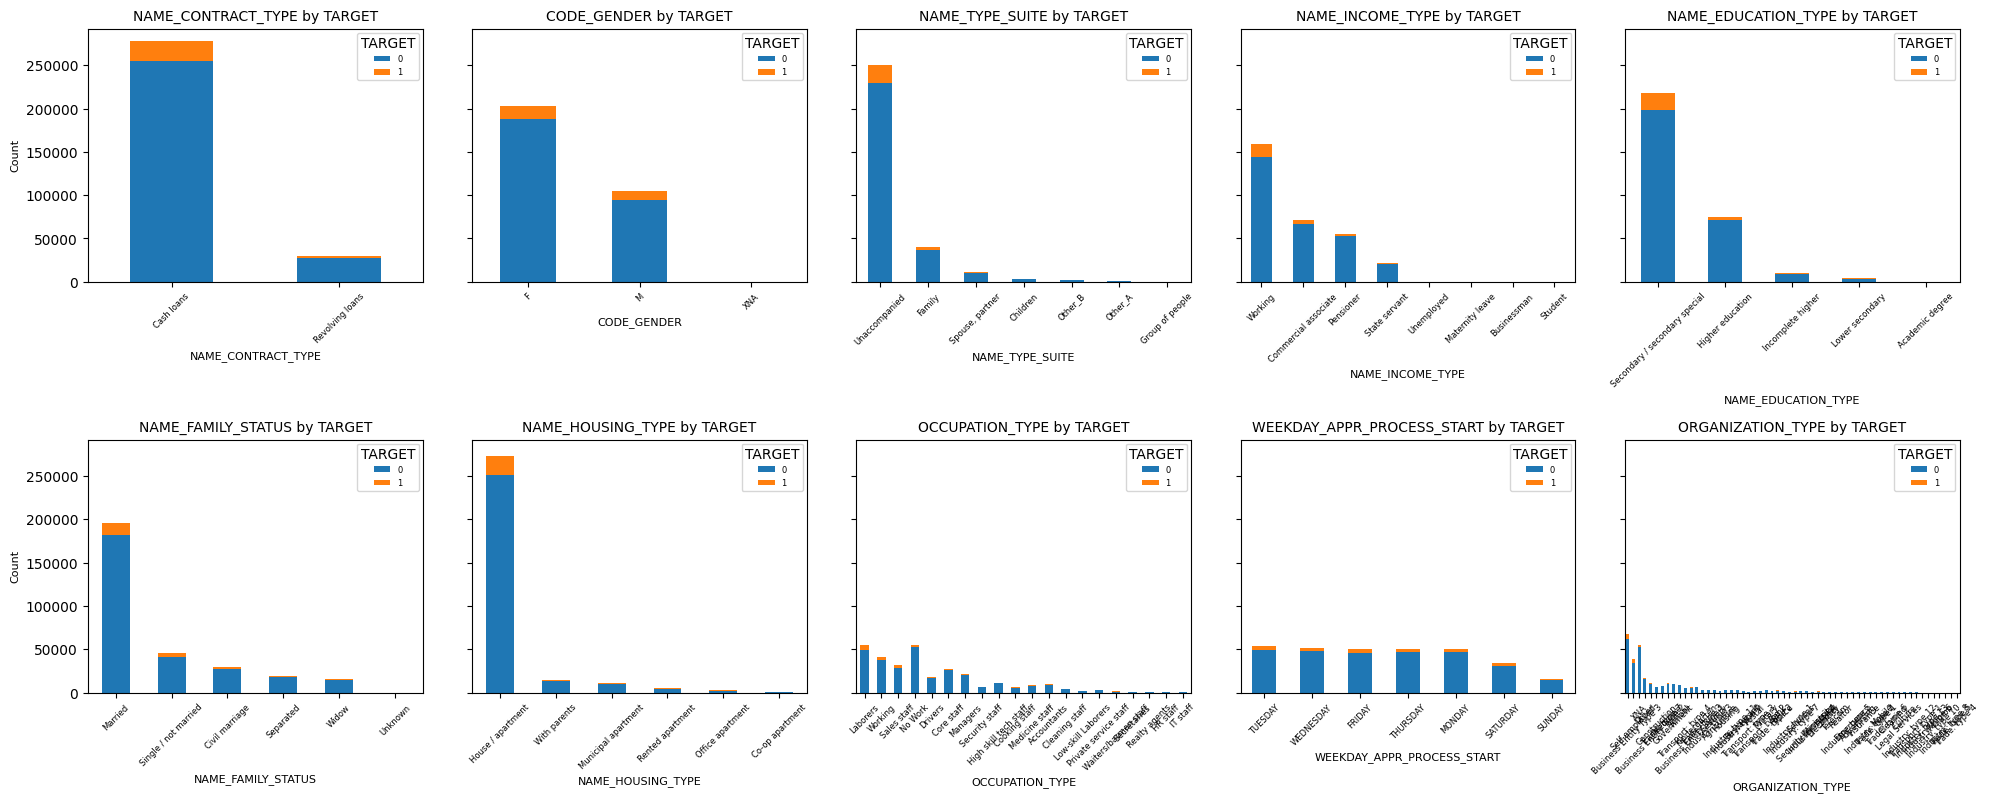

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define layout: 10 rows, 5 columns (adjust as needed)
n_rows = 10
n_cols = 5
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), sharey=True)

# Flatten axes for easier iteration (since it's a 2D array)
axes = axes.flatten()

# Plot each categorical column with stacked TARGET distribution
for i, col in enumerate(cols_to_encode[:n_rows * n_cols]):  # Limit to grid size (50 here)
    # Get top 5 categories to avoid clutter
    # top_n = df_processed[col].value_counts().nlargest(5).index
    # df_subset = df_processed[df_processed[col].isin(top_n)]

    # Create a crosstab of the column vs TARGET
    crosstab = pd.crosstab(df_processed[col], df_processed['TARGET'])
    crosstab = crosstab.sort_values(by=1, ascending=False)

    # Plot stacked bar chart
    crosstab.plot(kind='bar', stacked=True, ax=axes[i], color=['#1f77b4', '#ff7f0e'])  # Colors for TARGET 0 and 1
    axes[i].set_title(f'{col} by TARGET', fontsize=10)
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Count', fontsize=8)
    axes[i].tick_params(axis='x', rotation=45, labelsize=6)
    axes[i].legend(title='TARGET', loc='upper right', fontsize=6)

# Hide any unused subplots (if < 46 columns or grid exceeds columns)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# Adjust layout and save to file
plt.tight_layout()
plt.savefig('categorical_distributions.pdf', bbox_inches='tight', dpi=300)  # Save as PDF
plt.show()  # Optional: Display if your environment supports it

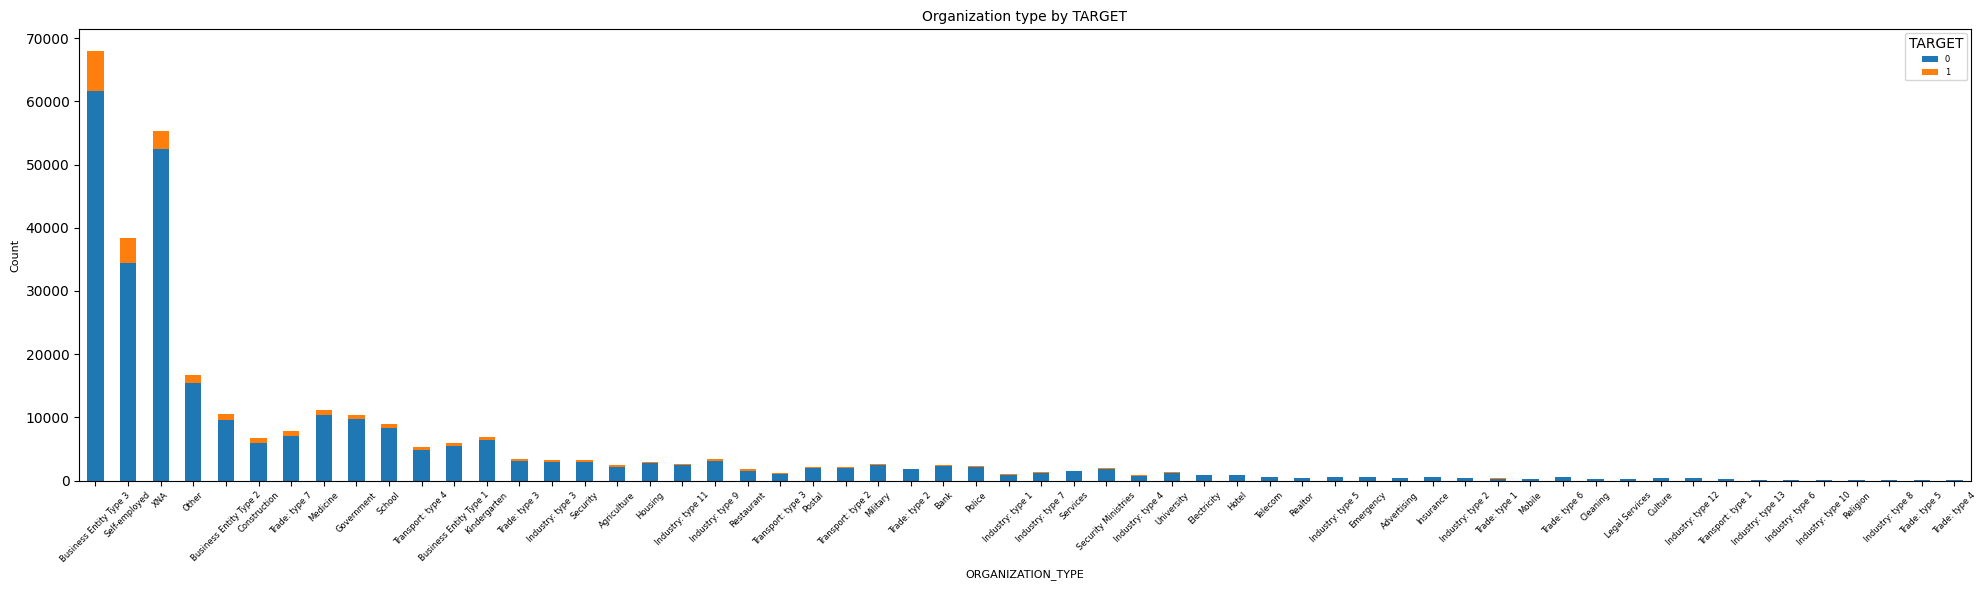

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a crosstab of the column vs TARGET
crosstab = pd.crosstab(df_processed['ORGANIZATION_TYPE'], df_processed['TARGET'])
crosstab = crosstab.sort_values(by=1, ascending=False)

# Set figure size wider here
fig, ax = plt.subplots(figsize=(20, 6))  # Adjust width as needed

# Plot stacked bar chart
crosstab.plot(kind='bar', stacked=True, ax=ax, color=['#1f77b4', '#ff7f0e'])

ax.set_title('Organization type by TARGET', fontsize=10)
ax.set_xlabel('ORGANIZATION_TYPE', fontsize=8)
ax.set_ylabel('Count', fontsize=8)
ax.tick_params(axis='x', rotation=45, labelsize=6)
ax.legend(title='TARGET', loc='upper right', fontsize=6)

plt.tight_layout()
plt.show()

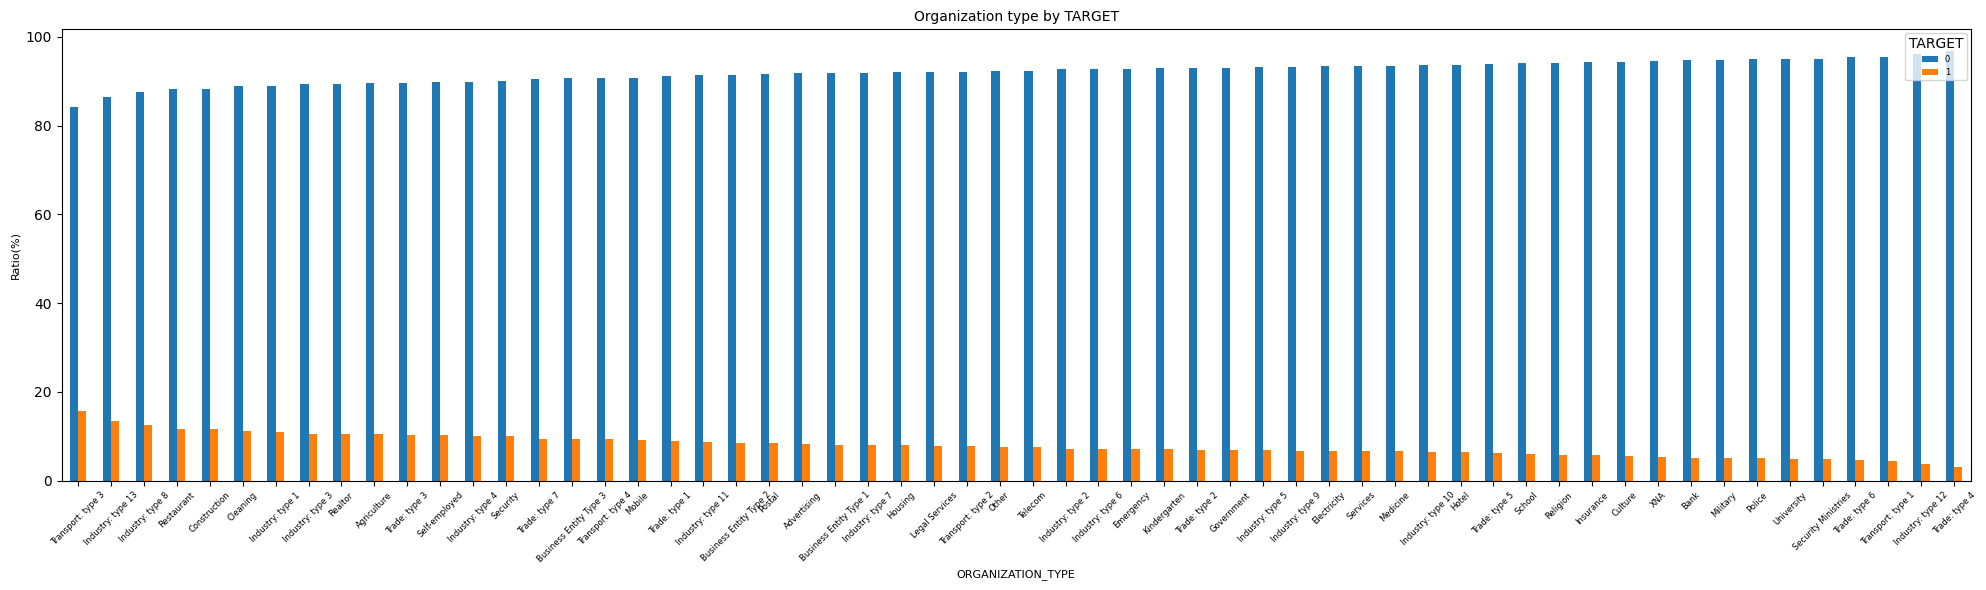

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Create a crosstab of the column vs TARGET
crosstab = pd.crosstab(df_processed['ORGANIZATION_TYPE'], df_processed['TARGET'], normalize='index')* 100
crosstab = crosstab.sort_values(by=1, ascending=False)

# Set figure size wider here
fig, ax = plt.subplots(figsize=(20, 6))  # Adjust width as needed

# Plot stacked bar chart
crosstab.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'])

ax.set_title('Organization type by TARGET', fontsize=10)
ax.set_xlabel('ORGANIZATION_TYPE', fontsize=8)
ax.set_ylabel('Ratio(%)', fontsize=8)
ax.tick_params(axis='x', rotation=45, labelsize=6)
ax.legend(title='TARGET', loc='upper right', fontsize=6)

plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_target_ratios(df, cols_to_encode, n_rows=10, n_cols=5, output_file='target_ratios.pdf'):
    # Create subplot grid
    fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), sharey=True)
    axes = axes.flatten()

    # Plot target ratio for each categorical column
    for i, col in enumerate(cols_to_encode[:n_rows * n_cols]):
        # Get top 5 categories
        # top_n = df[col].value_counts().nlargest(5).index
        # df_subset = df[df[col].isin(top_n)]
        #df_subset = df[col]

        # Calculate target ratio (proportion of TARGET=1)
        crosstab = pd.crosstab(df[col], df['TARGET'], normalize='index')* 100
        crosstab = crosstab.sort_values(by=1, ascending=False)

        # Plot bar chart
        crosstab.plot(kind='bar', ax=axes[i], color=['#1f77b4', '#ff7f0e'])
        axes[i].set_title(f'{col} Target Ratio (%)', fontsize=10)
        axes[i].set_xlabel(col, fontsize=8)
        axes[i].set_ylabel('Percentage (%)', fontsize=8)
        axes[i].tick_params(axis='x', rotation=45, labelsize=6)
        axes[i].legend(title='TARGET', labels=['0 (Non-Default)', '1 (Default)'], loc='upper right', fontsize=6)
        axes[i].set_ylim(0, 100)

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.savefig(output_file, bbox_inches='tight', dpi=300)
    plt.show()

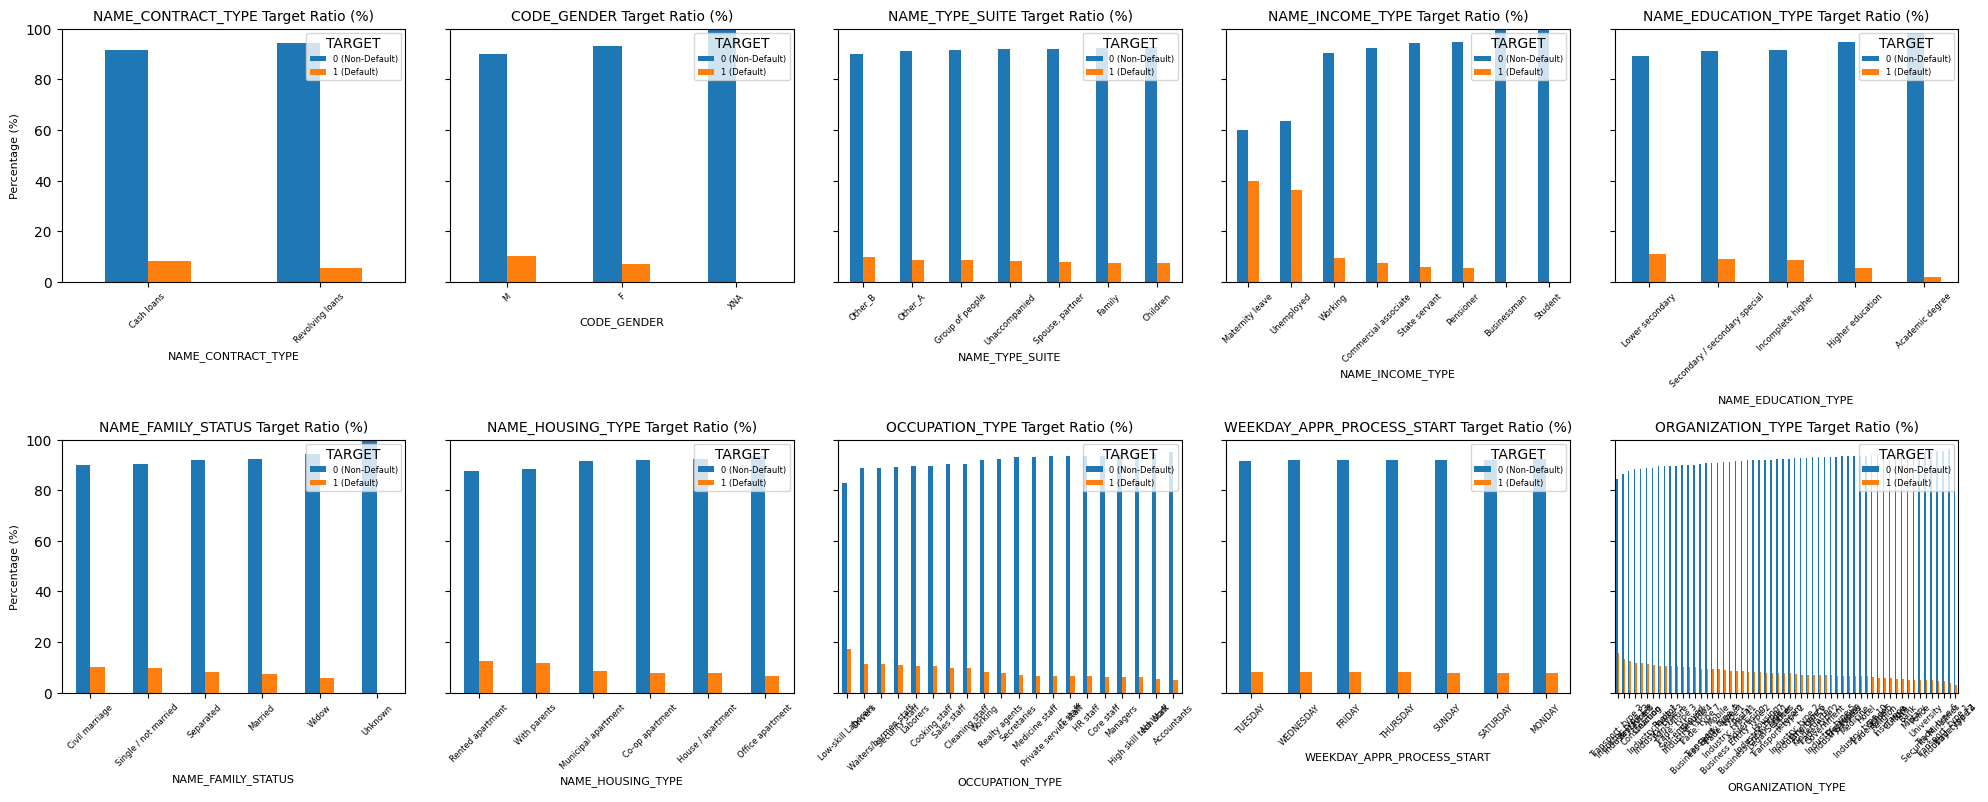

In [ ]:
plot_target_ratios(df_processed, cols_to_encode)

## **Categorical Variables Encoding**

In [ ]:
one_hot_encode_cols = []
for col in cols_to_encode:
    if df_processed[col].nunique() == 2:
        one_hot_encode_cols.append(col)

In [ ]:
print(one_hot_encode_cols)

['NAME_CONTRACT_TYPE']


In [ ]:
one_hot_encode_cols.append('NAME_FAMILY_STATUS')

In [ ]:
target_encode_cols = ['CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE', 'NAME_HOUSING_TYPE', 'ORGANIZATION_TYPE'] #name-housing-tyep, organization TBD

In [ ]:
frequency_encode_cols = ['NAME_TYPE_SUITE'] #name-family-status TBD

In [ ]:
drop_cols = ['WEEKDAY_APPR_PROCESS_START']

In [ ]:
# one-hot encoding
df_one_hot_encoded = pd.get_dummies(df_processed, columns=one_hot_encode_cols)

# Target encoding
df_one_hot_target_encoded = df_one_hot_encoded.copy()
target_encoded_cols = []
for col in target_encode_cols:
    global_mean = df_processed['TARGET'].mean()
    encoding = df.groupby(col)['TARGET'].agg(['mean', 'count'])
    smoothing = 10
    encoding['smoothed'] = (encoding['mean'] * encoding['count'] + global_mean * smoothing) / (encoding['count'] + smoothing)
    df_one_hot_target_encoded[col + '_target_encoded'] = df_one_hot_encoded[col].map(encoding['smoothed']).fillna(global_mean)
    df_one_hot_target_encoded = df_one_hot_target_encoded.drop(col, axis=1)
    target_encoded_cols.append(col + '_target_encoded')

# Frequency Encoding
df_one_hot_target_frequency_encoded = df_one_hot_target_encoded.copy()
frequency_encoded_cols = []
for col in frequency_encode_cols:
    encoding = df_one_hot_target_frequency_encoded[col].value_counts(normalize=True)
    df_one_hot_target_frequency_encoded[col + '_frequency_encoded'] = df_one_hot_target_frequency_encoded[col].map(encoding).fillna(0)
    df_one_hot_target_frequency_encoded = df_one_hot_target_frequency_encoded.drop(col, axis=1)
    frequency_encoded_cols.append(col + '_frequency_encoded')

# Drop columns
df_one_hot_target_frequency_encoded = df_one_hot_target_frequency_encoded.drop(drop_cols, axis=1)

In [ ]:
df_one_hot_target_frequency_encoded.shape

(307510, 238)

In [ ]:
df_processed_1 = df_one_hot_target_frequency_encoded

In [ ]:
df_processed_1.columns

Index(['SK_ID_CURR', 'TARGET', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
       'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE',
       ...
       'NAME_FAMILY_STATUS_Single / not married', 'NAME_FAMILY_STATUS_Unknown',
       'NAME_FAMILY_STATUS_Widow', 'CODE_GENDER_target_encoded',
       'NAME_INCOME_TYPE_target_encoded', 'NAME_EDUCATION_TYPE_target_encoded',
       'OCCUPATION_TYPE_target_encoded', 'NAME_HOUSING_TYPE_target_encoded',
       'ORGANIZATION_TYPE_target_encoded',
       'NAME_TYPE_SUITE_frequency_encoded'],
      dtype='object', length=238)

In [ ]:
len(df_processed_1.columns)

238

In [ ]:
df_processed_1.shape

(307510, 238)

In [ ]:
df_processed_1['TARGET'].value_counts()

,count
TARGET,
0,282685
1,24825


#### **[DELETED]One-hot**

###**[DELETED]KNN impute Occupation type**

###**[DELETED]Target encode occupation type**

### **Feature Importance with Lasso**
Lasso keeps only few features:
- either feature are correlated
- features are weak
- alpha is too high

In [ ]:
y = df_processed_1.iloc[:,1]
X = df_processed_1.iloc[:,2:]

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
import pandas as pd

# X = your feature matrix (DataFrame), y = target variable
# Optional: Standardize features (Lasso is sensitive to scale)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit Lasso
lasso = Lasso(alpha=0.01, random_state = 42)  # Try different alphas
lasso.fit(X_scaled, y)

# Get feature importance
feature_importance = pd.Series(lasso.coef_, index=X.columns)

# Keep only non-zero coefficients
important_features = feature_importance[feature_importance != 0]

print(important_features.sort_values(ascending=False))

ORGANIZATION_TYPE_target_encoded    0.005335
active_loan_count                   0.004010
OCCUPATION_TYPE_target_encoded      0.003610
active_loan_ratio                   0.002036
DAYS_BIRTH                         -0.004052
EXT_SOURCE_3_level                 -0.007491
EXT_SOURCE_2_level                 -0.016486
EXT_SOURCE_ALL                     -0.023783
dtype: float64


In [ ]:
# Correlation matrix
corr_matrix = X.corr().abs()
high_corr = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = high_corr.stack().sort_values(ascending=False)
print("Top correlated pairs:")
print(high_corr_pairs[high_corr_pairs > 0.3].head())

Top correlated pairs:
AMT_ANNUITY                    COM_ANNUITY                           1.000000
NAME_CONTRACT_TYPE_Cash loans  NAME_CONTRACT_TYPE_Revolving loans    1.000000
AMT_INCOME_TOTAL               AFFORD                                0.998017
AMT_CREDIT                     AMT_GOODS_PRICE                       0.986687
REG_REGION_NOT_WORK_REGION     REGION_WRONG                          0.981451
dtype: float64


#**Model**

In [ ]:
from sklearn.model_selection import train_test_split

# Assume X is your feature set and y is your target variable
y = df_processed_1.iloc[:,1]
X = df_processed_1.iloc[:,2:]


# Split the data into 70% training and 30% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
print(X_train.shape)
print(X_train[y_train == 0].shape)
print(X_train[y_train == 1].shape)

(215257, 236)
(197879, 236)
(17378, 236)


In [ ]:
print(X_val.shape)
print(X_val[y_val == 0].shape)
print(X_val[y_val == 1].shape)

(46126, 236)
(42403, 236)
(3723, 236)


In [ ]:
df_na = X_train.isna().sum()
df_na[df_na > 0]

,0


## **Base Model - Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)

print(confusion_matrix(y_val, y_pred))
print(classification_report(y_val, y_pred))

[[42393    10]
 [ 3716     7]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     42403
           1       0.41      0.00      0.00      3723

    accuracy                           0.92     46126
   macro avg       0.67      0.50      0.48     46126
weighted avg       0.88      0.92      0.88     46126



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## **Decision Tree**

### **Decision Tree - Class weight**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score, roc_curve
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def get_model_performance(X_train, y_train, X_val, y_val):
    class_weights = [{0:1, 1:10}]
    max_depths = [5, 10, 15]
    results = []
    roc_data = []

    for w in class_weights:
        for d in max_depths:
            # Train model
            model = DecisionTreeClassifier(class_weight=w, max_depth=d, random_state=42)
            model.fit(X_train, y_train)

            # Predictions
            train_pred = model.predict(X_train)
            val_pred = model.predict(X_val)
            train_pred_proba = model.predict_proba(X_train)[:, 1]
            val_pred_proba = model.predict_proba(X_val)[:, 1]

            # Metrics
            train_acc = accuracy_score(y_train, train_pred)
            val_acc = accuracy_score(y_val, val_pred)
            train_recall = recall_score(y_train, train_pred, zero_division=0)
            val_recall = recall_score(y_val, val_pred, zero_division=0)
            train_roc_auc = roc_auc_score(y_train, train_pred_proba)
            val_roc_auc = roc_auc_score(y_val, val_pred_proba)
            train_f1 = f1_score(y_train, train_pred, zero_division=0)
            val_f1 = f1_score(y_val, val_pred, zero_division=0)

            # ROC Curve data
            fpr, tpr, _ = roc_curve(y_val, val_pred_proba)
            roc_data.append({
                'class_weight': f"1:{w[1]}",
                'max_depth': d,
                'fpr': fpr,
                'tpr': tpr,
                'val_roc_auc': val_roc_auc
            })

            # Store results
            results.append({
                'class_weight': f"1:{w[1]}",
                'max_depth': d,
                'train_acc': train_acc,
                'val_acc': val_acc,
                'train_recall': train_recall,
                'val_recall': val_recall,
                'train_roc_auc': train_roc_auc,
                'val_roc_auc': val_roc_auc,
                'train_f1': train_f1,
                'val_f1': val_f1
            })

    # Convert results to DataFrame
    results_df = pd.DataFrame(results)

    # Visualize
    # Bar Plot - Recall
    plt.figure(figsize=(12, 6))
    results_df['combo'] = results_df['class_weight'] + '_depth' + results_df['max_depth'].astype(str)
    sns.barplot(x='combo', y='val_recall', data=results_df, color='salmon', label='Recall')
    plt.title("Validation Recall by Class Weight and Max Depth")
    plt.xlabel("Class Weight & Max Depth")
    plt.ylabel("Validation Recall")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.savefig('recall_barplot.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # Bar Plot - ROC AUC
    plt.figure(figsize=(12, 6))
    sns.barplot(x='combo', y='val_roc_auc', data=results_df, color='skyblue', label='ROC AUC')
    plt.title("Validation ROC AUC by Class Weight and Max Depth")
    plt.xlabel("Class Weight & Max Depth")
    plt.ylabel("Validation ROC AUC")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.savefig('roc_auc_barplot.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # ROC Curve Plot
    plt.figure(figsize=(10, 8))
    colors = sns.color_palette("husl", len(roc_data))
    for i, roc in enumerate(roc_data):
        plt.plot(roc['fpr'], roc['tpr'], color=colors[i],
                 label=f"Weight={roc['class_weight']}, Depth={roc['max_depth']} (AUC={roc['val_roc_auc']:.4f})")
    plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.5)')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves by Class Weight and Max Depth')
    plt.legend(loc='lower right', fontsize=8)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('roc_curves.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # Heatmap - Recall
    pivot_recall = results_df.pivot(index='max_depth', columns='class_weight', values='val_recall')
    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot_recall, annot=True, fmt='.4f', cmap='Reds')
    plt.title("Validation Recall Heatmap")
    plt.xlabel("Class Weight")
    plt.ylabel("Max Depth")
    plt.savefig('recall_heatmap.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # Heatmap - F1
    pivot_f1 = results_df.pivot(index='max_depth', columns='class_weight', values='val_f1')
    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot_f1, annot=True, fmt='.4f', cmap='Blues')
    plt.title("Validation F1 Heatmap")
    plt.xlabel("Class Weight")
    plt.ylabel("Max Depth")
    plt.savefig('f1_heatmap.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # Heatmap - ROC AUC
    pivot_roc_auc = results_df.pivot(index='max_depth', columns='class_weight', values='val_roc_auc')
    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot_roc_auc, annot=True, fmt='.4f', cmap='Blues')
    plt.title("Validation ROC AUC Heatmap")
    plt.xlabel("Class Weight")
    plt.ylabel("Max Depth")
    plt.savefig('roc_auc_heatmap.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    return results_df

#### **Best performance Parameters**
Best **Recall**: class_weight = {0:1, 1:20} , max_depth = 5

Best **ROC AUC**: class_weight = {0:1, 1:10} , max_depth = 5

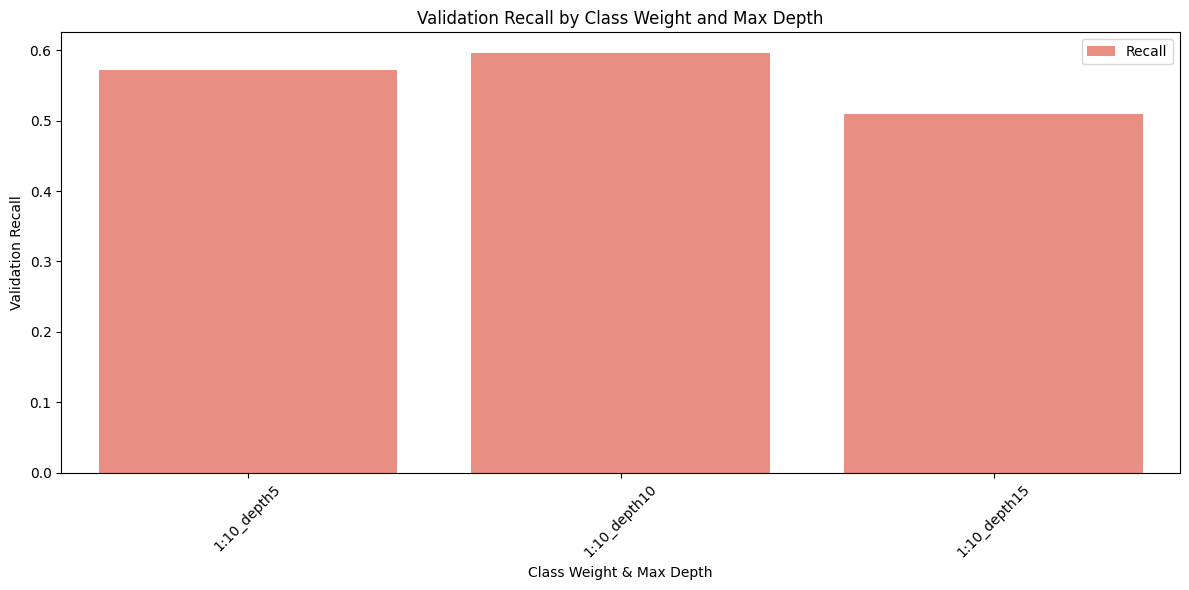

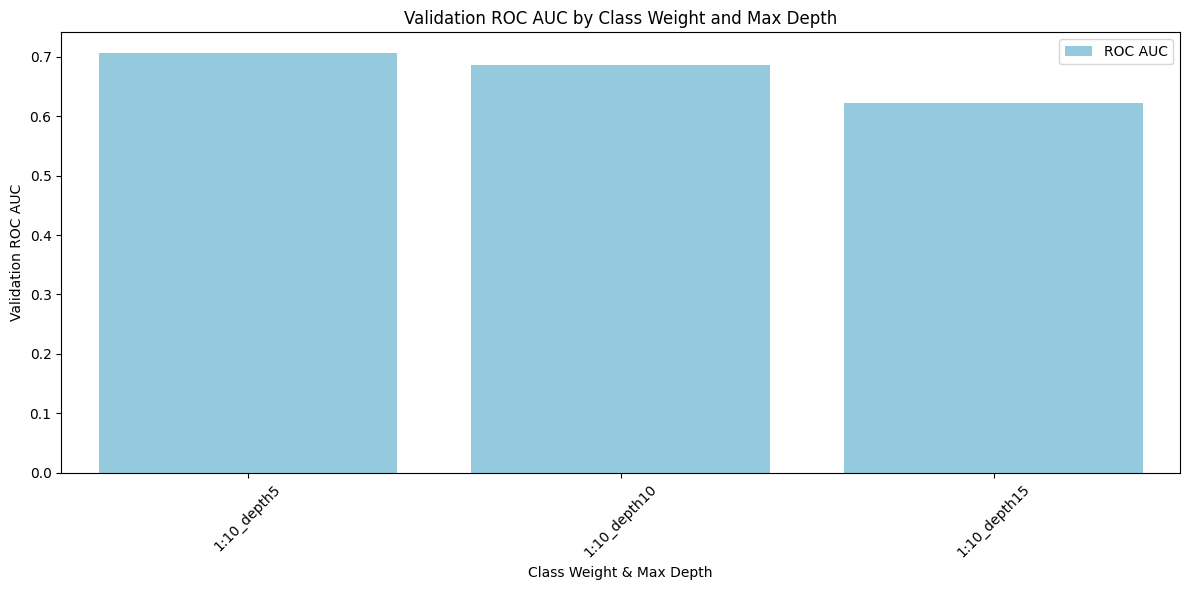

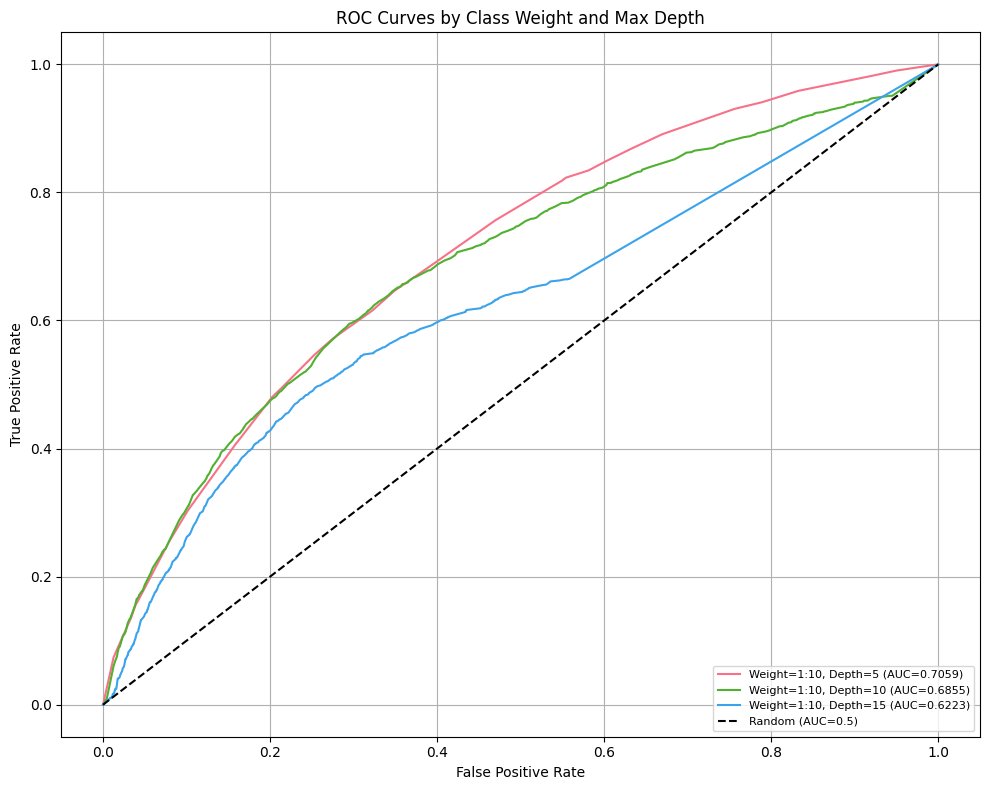

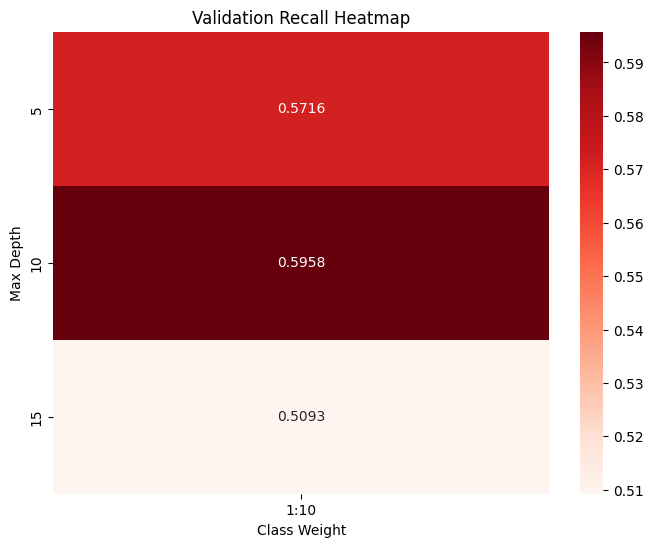

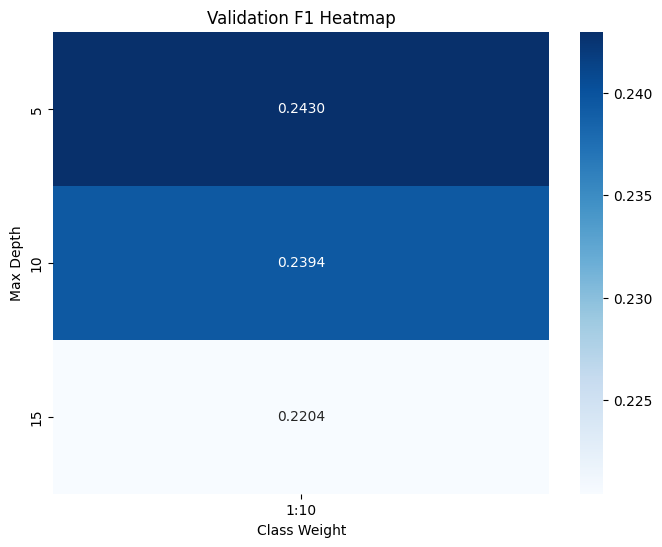

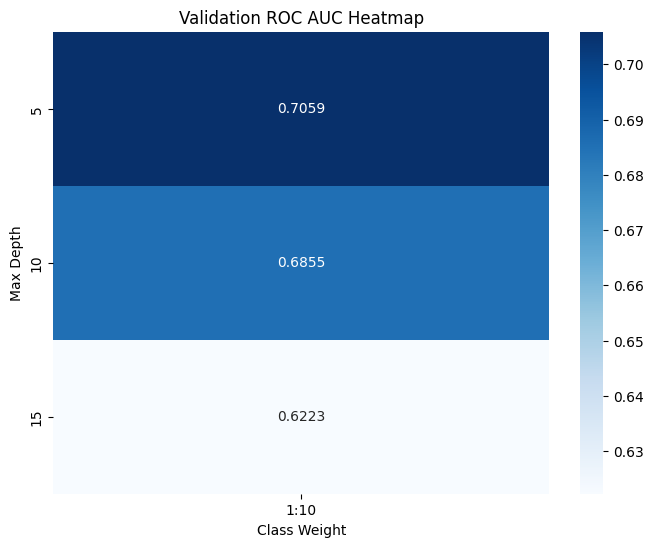

,class_weight,max_depth,train_acc,val_acc,train_recall,val_recall,train_roc_auc,val_roc_auc,train_f1,val_f1,combo
0,1:10,5,0.714058,0.712527,0.585856,0.571582,0.712803,0.705915,0.248581,0.242978,1:10_depth5
1,1:10,10,0.711619,0.694402,0.712970,0.595756,0.786131,0.685478,0.285300,0.239370,1:10_depth10
2,1:10,15,0.772063,0.709275,0.902808,0.509267,0.906174,0.622259,0.390065,0.220439,1:10_depth15


In [ ]:
get_model_performance(X_train, y_train, X_val, y_val)

### **Decision Tree - Tune Tree**
modify min_sample_split, min_samples_leaf, threshold

turn on feature selection (top_n_feature)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score, precision_score, roc_curve
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
def get_model_performance(X_train, y_train, X_val, y_val, top_n_features=None):
    # Feature selection (if specified)
    if top_n_features:
        model_temp = DecisionTreeClassifier(class_weight={0:1, 1:10}, random_state=42)
        model_temp.fit(X_train, y_train)
        importance = pd.Series(model_temp.feature_importances_, index=X_train.columns)
        top_features = importance.sort_values(ascending=False).head(top_n_features).index
        X_train = X_train[top_features]
        X_val = X_val[top_features]
        print(f"Selected top {top_n_features} features:", top_features.tolist())

    # Define parameter grid
    param_grid = [
        {
            'model_type': 'DecisionTree',
            'class_weight': [{0:1, 1:10}],
            'max_depth': [7, 10],
            'min_samples_split': [20, 50],
            'min_samples_leaf': [10, 20],
            'threshold': [0.3, 0.5, 0.7]
        }
    ]

    results = []
    roc_data = []

    # Test Decision Tree parameters
    for params in param_grid:
        if params['model_type'] == 'DecisionTree':
            for w in params['class_weight']:
                for d in params['max_depth']:
                    for split in params['min_samples_split']:
                        for leaf in params['min_samples_leaf']:
                            for t in params['threshold']:
                                # Train model
                                model = DecisionTreeClassifier(
                                    class_weight=w,
                                    max_depth=d,
                                    min_samples_split=split,
                                    min_samples_leaf=leaf,
                                    random_state=42
                                )
                                model.fit(X_train, y_train)

                                # Predictions
                                train_pred_proba = model.predict_proba(X_train)[:, 1]
                                val_pred_proba = model.predict_proba(X_val)[:, 1]
                                train_pred = (train_pred_proba >= t).astype(int)
                                val_pred = (val_pred_proba >= t).astype(int)

                                # Metrics
                                train_acc = accuracy_score(y_train, train_pred)
                                val_acc = accuracy_score(y_val, val_pred)
                                train_recall = recall_score(y_train, train_pred, zero_division=0)
                                val_recall = recall_score(y_val, val_pred, zero_division=0)
                                train_precision = precision_score(y_train, train_pred, zero_division=0)
                                val_precision = precision_score(y_val, val_pred, zero_division=0)
                                train_roc_auc = roc_auc_score(y_train, train_pred_proba)
                                val_roc_auc = roc_auc_score(y_val, val_pred_proba)
                                train_f1 = f1_score(y_train, train_pred, zero_division=0)
                                val_f1 = f1_score(y_val, val_pred, zero_division=0)

                                # ROC Curve data
                                fpr, tpr, _ = roc_curve(y_val, val_pred_proba)
                                roc_data.append({
                                    'class_weight': f"1:{w[1]}",
                                    'max_depth': d,
                                    'min_samples_split': split,
                                    'min_samples_leaf': leaf,
                                    'threshold': t,
                                    'fpr': fpr,
                                    'tpr': tpr,
                                    'val_roc_auc': val_roc_auc
                                })

                                # Store results
                                results.append({
                                    'model_type': 'DecisionTree',
                                    'class_weight': f"1:{w[1]}",
                                    'max_depth': d,
                                    'min_samples_split': split,
                                    'min_samples_leaf': leaf,
                                    'threshold': t,
                                    'train_acc': train_acc,
                                    'val_acc': val_acc,
                                    'train_recall': train_recall,
                                    'val_recall': val_recall,
                                    'train_precision': train_precision,
                                    'val_precision': val_precision,
                                    'train_roc_auc': train_roc_auc,
                                    'val_roc_auc': val_roc_auc,
                                    'train_f1': train_f1,
                                    'val_f1': val_f1
                                })

    # Convert results to DataFrame
    results_df = pd.DataFrame(results)

    # Visualize Decision Tree results
    results_df['combo'] = (results_df['class_weight'] + '_depth' + results_df['max_depth'].astype(str) +
                           '_split' + results_df['min_samples_split'].astype(str) +
                           '_leaf' + results_df['min_samples_leaf'].astype(str) +
                           '_thr' + results_df['threshold'].astype(str))

    # Bar Plot - F1 Score
    plt.figure(figsize=(14, 6))
    sns.barplot(x='combo', y='val_f1', data=results_df, color='purple', label='F1 Score')
    plt.title("Validation F1 Score (Decision Tree)")
    plt.xlabel("Parameters (Weight_Depth_Split_Leaf_Threshold)")
    plt.ylabel("Validation F1 Score")
    plt.xticks(rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.savefig('f1_barplot_decision_tree.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # Bar Plot - Recall
    plt.figure(figsize=(14, 6))
    sns.barplot(x='combo', y='val_recall', data=results_df, color='salmon', label='Recall')
    plt.title("Validation Recall (Decision Tree)")
    plt.xlabel("Parameters (Weight_Depth_Split_Leaf_Threshold)")
    plt.ylabel("Validation Recall")
    plt.xticks(rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.savefig('recall_barplot_decision_tree.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # Bar Plot - Precision
    plt.figure(figsize=(14, 6))
    sns.barplot(x='combo', y='val_precision', data=results_df, color='skyblue', label='Precision')
    plt.title("Validation Precision (Decision Tree)")
    plt.xlabel("Parameters (Weight_Depth_Split_Leaf_Threshold)")
    plt.ylabel("Validation Precision")
    plt.xticks(rotation=90)
    plt.legend()
    plt.tight_layout()
    plt.savefig('precision_barplot_decision_tree.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # ROC Curve Plot
    plt.figure(figsize=(12, 8))
    colors = sns.color_palette("husl", len(roc_data))
    for i, roc in enumerate(roc_data):
        label = (f"Weight={roc['class_weight']}, Depth={roc['max_depth']}, "
                 f"Split={roc['min_samples_split']}, Leaf={roc['min_samples_leaf']}, "
                 f"Thr={roc['threshold']} (AUC={roc['val_roc_auc']:.4f})")
        plt.plot(roc['fpr'], roc['tpr'], color=colors[i], label=label)
    plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC=0.5)')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves for Decision Tree (Validation Set)')
    plt.legend(loc='lower right', fontsize=8, bbox_to_anchor=(1.05, 0), borderaxespad=0.)
    plt.grid(True)
    plt.tight_layout()
    plt.savefig('roc_curves_decision_tree.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    return results_df

In [ ]:
# get_model_performance(X_train, y_train, X_val, y_val, top_n_features=40)

### **Decision Tree- Visualize feature importance**

In [ ]:
def visualize_feature_importance(X_train, y_train, top_n_features=20):
    # Train temporary model for feature importance
    model_temp = DecisionTreeClassifier(class_weight={0:1, 1:10}, random_state=42)
    model_temp.fit(X_train, y_train)

    # Get feature importance
    importance = pd.Series(model_temp.feature_importances_, index=X_train.columns)
    importance_sorted = importance.sort_values(ascending=False)

    # Select top features
    top_features = importance_sorted.head(top_n_features).index
    print(f"Top {top_n_features} features:", top_features.tolist())

    # Bar plot
    plt.figure(figsize=(12, 6))
    sns.barplot(x=importance_sorted.head(top_n_features),
                y=importance_sorted.head(top_n_features).index)
    plt.title(f"Top {top_n_features} Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    # Cumulative importance plot
    cumulative_importance = importance_sorted.cumsum()
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(cumulative_importance) + 1),
             cumulative_importance,
             marker='o')
    plt.axhline(y=0.9, color='r', linestyle='--', label='90% Importance')
    plt.axhline(y=0.95, color='g', linestyle='--', label='95% Importance')
    plt.title("Cumulative Feature Importance")
    plt.xlabel("Number of Features")
    plt.ylabel("Cumulative Importance")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

   # Suggest number of features
    n_features_90 = np.where(cumulative_importance >= 0.9)[0][0] + 1 if (cumulative_importance >= 0.9).any() else len(cumulative_importance)
    n_features_95 = np.where(cumulative_importance >= 0.95)[0][0] + 1 if (cumulative_importance >= 0.95).any() else len(cumulative_importance)
    print(f"Features covering 90% importance: {n_features_90}")
    print(f"Features covering 95% importance: {n_features_95}")

    return top_features

In [ ]:
# visualize_feature_importance(X_train, y_train, top_n_features=20)

#### **Decision Tree - Visulize Tree**

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import export_text

def visualize_decision_tree(X_train, y_train, feature_names):
    # Train model with best parameters
    model = DecisionTreeClassifier(class_weight={0:1, 1:10}, max_depth=7, min_samples_split=20, min_samples_leaf=10, threshold=0.3, random_state=42)
    model.fit(X_train, y_train)

    # Plot tree
    plt.figure(figsize=(20, 10))
    plot_tree(
        model,
        feature_names=feature_names,
        class_names=['Non-Default (0)', 'Default (1)'],
        filled=True,
        rounded=True,
        proportion=True,
        fontsize=10
    )
    plt.title("Decision Tree (class_weight={0:1, 1:10}, max_depth=7)")
    plt.show()

    # Export text representation
    tree_text = export_text(model, feature_names=feature_names, decimals=4)
    print("\nText Representation of Decision Tree:")
    print(tree_text)

    return model

In [ ]:
visualize_decision_tree(X_train, y_train, X_train.columns)

TypeError: DecisionTreeClassifier.__init__() got an unexpected keyword argument 'threshold'

## **Seperate Negative & Positive before resmapling**

In [ ]:
# Separate positive and negative samples
X_pos = X_train[y_train == 1]
X_neg = X_train[y_train == 0]

In [ ]:
from sklearn.preprocessing import StandardScaler

X_neg_np = X_neg.values  # if X_neg is a DataFrame
scaler = StandardScaler()
X_neg_scaled = scaler.fit_transform(X_neg_np)

In [ ]:
print(X_neg.shape)
print(X_pos.shape)

(197879, 236)
(17378, 236)


## **Down Sampling - with PCA clustering**
PCA is sensitive to scale, need standardization.

##### **check number of components to explain variance for PCA**

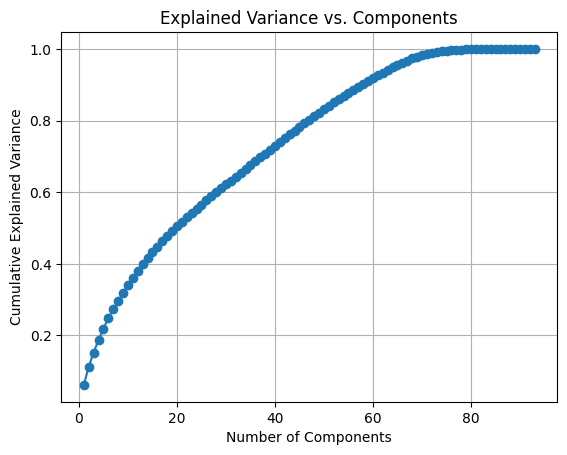

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA().fit(X_neg_scaled)  # Use full PCA
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs. Components')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.decomposition import PCA

# For visualization
pca_vis = PCA(n_components=3)  #for visualizing 3d
X_neg_pca_3d = pca_vis.fit_transform(X_neg_scaled)

# For clustering
pca_cluster = PCA(n_components=0.90) #retain 90% variance of the data
X_neg_pca_cluster = pca_cluster.fit_transform(X_neg_scaled)

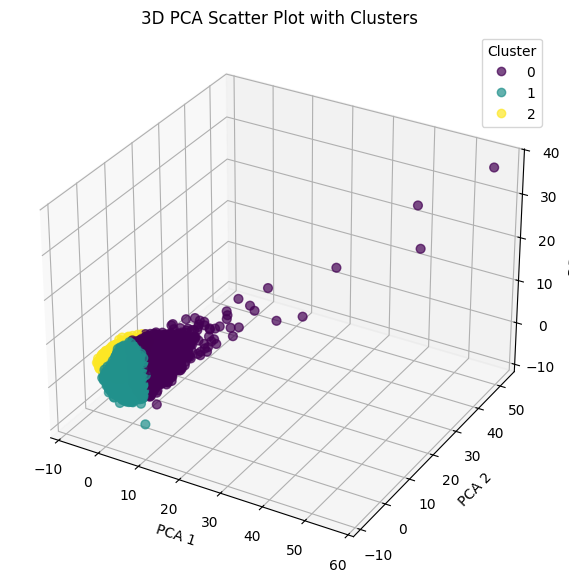

In [ ]:
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X_neg_pca_3d)

# Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(X_neg_pca_3d[:, 0], X_neg_pca_3d[:, 1], X_neg_pca_3d[:, 2],
                     c=labels, cmap='viridis', s=40, alpha=0.7)

ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')
ax.set_zlabel('PCA 3')
ax.set_title('3D PCA Scatter Plot with Clusters')

plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()

In [ ]:
components_df = pd.DataFrame(
    np.round(pca_vis.components_, 4),  # shape (n_components, n_features)
    columns=df_processed_1.iloc[:,2:].columns,
    index=[f'PC{i+1}' for i in range(pca_vis.n_components_)]
)

# View top contributors to each PC
for i in range(3):  # for PC1, PC2, PC3
    print(f"\nTop features contributing to PC{i+1}:")
    print(components_df.iloc[i].sort_values(ascending=False).head(10))


Top features contributing to PC1:
FLAG_EMP_PHONE                      0.3070
NAME_INCOME_TYPE_target_encoded     0.2288
PHONE_ALL                           0.2243
ORGANIZATION_TYPE_target_encoded    0.2212
AMT_ANNUITY                         0.1953
COM_ANNUITY                         0.1953
AMT_GOODS_PRICE                     0.1843
CITY_WRONG                          0.1834
AMT_CREDIT                          0.1831
REG_CITY_NOT_WORK_CITY              0.1814
Name: PC1, dtype: float64

Top features contributing to PC2:
AMT_CREDIT                       0.3185
AMT_GOODS_PRICE                  0.3159
AMT_ANNUITY                      0.2816
COM_ANNUITY                      0.2816
DAYS_BIRTH                       0.1934
PERIOD                           0.1822
NAME_CONTRACT_TYPE_Cash loans    0.1745
AMT_INCOME_TOTAL                 0.1737
EXT_SOURCE_ALL                   0.1690
DOCUMENT_ALL                     0.1630
Name: PC2, dtype: float64

Top features contributing to PC3:
REGION_WRONG 

##### **get optimal k for kmeans**
elbow mehod unclear

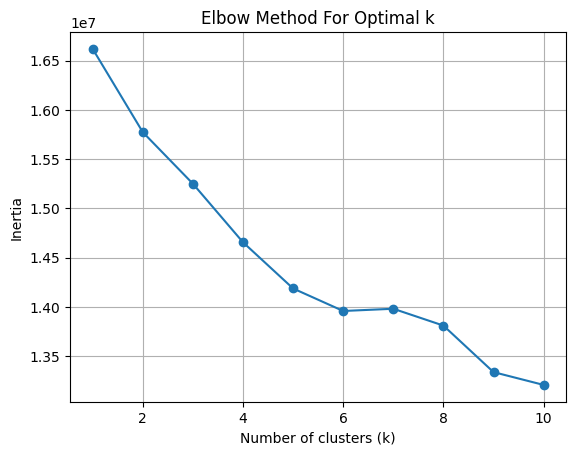

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_neg_pca_cluster)  # or your PCA-reduced data
    inertia.append(kmeans.inertia_)

plt.plot(K, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=6, random_state=42)
kmeans.fit(X_neg_pca_cluster)
cluster_labels_neg = kmeans.predict(X_neg_pca_cluster)

#####**re-sampling**

In [ ]:
unique, counts = np.unique(cluster_labels_neg, return_counts=True)
cluster_distribution = dict(zip(unique, counts))
cluster_distribution

{np.int32(0): np.int64(42626),
 np.int32(1): np.int64(17771),
 np.int32(2): np.int64(10213),
 np.int32(3): np.int64(33730),
 np.int32(4): np.int64(74658),
 np.int32(5): np.int64(18881)}

In [ ]:
N_pos = len(X_pos)

# Total negative samples to keep, matching 5:1 ratio
target_neg_samples = N_pos * 5

# Calculate the total number of samples in each cluster
total_neg_samples = len(X_neg)

# Calculate the proportional down-sampling for each cluster
resampled_neg_indices = []
for cluster_id in unique:
    cluster_size = cluster_distribution[cluster_id]
    # Proportional sampling ratio for this cluster
    cluster_ratio = cluster_size / total_neg_samples
    cluster_target_size = int(cluster_ratio * target_neg_samples)
    # Get the indices of the samples belonging to this cluster
    cluster_indices = np.where(cluster_labels_neg == cluster_id)[0]
    # Randomly sample from the cluster
    resampled_neg_indices += list(np.random.choice(cluster_indices, cluster_target_size, replace=False))

# Resample the `X_neg` data
X_neg_resampled = X_neg.iloc[resampled_neg_indices]

In [ ]:
X_train_balanced = pd.concat([X_pos, X_neg_resampled])
y_train_balanced = np.hstack([
    np.ones(len(X_pos)),
    np.zeros(len(X_neg_resampled))
])

##### **Random Clusering**

In [ ]:
# from sklearn.utils import resample

# # Downsample negatives
# X_neg_downsampled = resample(
#     X_neg,
#     replace=False,  # without replacement
#     n_samples=len(X_pos) * 5,
#     random_state=42
# )

# # Create new training set
# X_train_balanced = pd.concat([X_pos, X_neg_downsampled])
# y_train_balanced = np.hstack([
#     np.ones(len(X_pos)),
#     np.zeros(len(X_neg_downsampled))
# ])

# # Shuffle
# from sklearn.utils import shuffle
# X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=42)

## **Down Sampling - Random Resample**

In [ ]:
from sklearn.utils import resample

# Downsample negatives
X_neg_downsampled = resample(
    X_neg,
    replace=False,  # without replacement
    n_samples=len(X_pos) * 4,
    random_state=42
)

# Create new training set
X_train_balanced = pd.concat([X_pos, X_neg_downsampled])
y_train_balanced = np.hstack([
    np.ones(len(X_pos)),
    np.zeros(len(X_neg_downsampled))
])

# Shuffle
from sklearn.utils import shuffle
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=42)

## **XGBoost Model**

###**XGBoost- Feature importance**

In [ ]:
from sklearn.model_selection import train_test_split

# Assume X is your feature set and y is your target variable
y = df_processed_1.iloc[:,1]
X = df_processed_1.iloc[:,2:]


# Split the data into 70% training and 30% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
X_train_dropped = X_train.copy()
X_val_dropped = X_val.copy()
X_test_dropped = X_test.copy()
X_train_dropped.drop(columns=['COM_ANNUITY', 'NAME_CONTRACT_TYPE_Revolving loans', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'REG_REGION_NOT_WORK_REGION'], inplace=True)
X_val_dropped.drop(columns=['COM_ANNUITY', 'NAME_CONTRACT_TYPE_Revolving loans', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'REG_REGION_NOT_WORK_REGION'], inplace=True)
X_test_dropped.drop(columns=['COM_ANNUITY', 'NAME_CONTRACT_TYPE_Revolving loans', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'REG_REGION_NOT_WORK_REGION'], inplace=True)

In [ ]:
import xgboost as xgb

In [ ]:
def visualize_feature_importance(X_train, y_train, top_n_features=20):
    # Train temporary XGBoost model for feature importance
    model_temp = xgb.XGBClassifier(
        scale_pos_weight=10,   # Or adjust as you want
        random_state=42,
        n_estimators=100,
        max_depth=3,
        use_label_encoder=False,
        eval_metric='logloss'
    )
    model_temp.fit(X_train, y_train)

    # Get feature importance
    importance_dict = model_temp.get_booster().get_score(importance_type='gain')
    importance = pd.Series(importance_dict).reindex(X_train.columns, fill_value=0)
    importance_sorted = importance.sort_values(ascending=False)

    # Select top features
    top_features = importance_sorted.head(top_n_features).index
    print(f"Top {top_n_features} features:", top_features.tolist())

    # Bar plot
    plt.figure(figsize=(12, 6))
    sns.barplot(x=importance_sorted.head(top_n_features),
                y=importance_sorted.head(top_n_features).index,
                palette="viridis")
    plt.title(f"Top {top_n_features} Feature Importances (XGBoost)")
    plt.xlabel("Importance (Gain)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    # Cumulative importance plot
    cumulative_importance = importance_sorted.cumsum()
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(cumulative_importance) + 1),
             cumulative_importance,
             marker='o')
    plt.axhline(y=0.9, color='r', linestyle='--', label='90% Importance')
    plt.axhline(y=0.95, color='g', linestyle='--', label='95% Importance')
    plt.title("Cumulative Feature Importance (XGBoost)")
    plt.xlabel("Number of Features")
    plt.ylabel("Cumulative Importance")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Suggest number of features
    n_features_90 = np.where(cumulative_importance >= 0.9)[0][0] + 1 if (cumulative_importance >= 0.9).any() else len(cumulative_importance)
    n_features_95 = np.where(cumulative_importance >= 0.95)[0][0] + 1 if (cumulative_importance >= 0.95).any() else len(cumulative_importance)
    print(f"Features covering 90% importance: {n_features_90}")
    print(f"Features covering 95% importance: {n_features_95}")

    return top_features

In [ ]:
visualize_feature_importance(X_train_balanced, y_train_balanced, top_n_features=20)

###**XGBoost - Train model [UPDATED]**

In [ ]:
from xgboost import XGBClassifier, plot_tree
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score, precision_score, roc_curve
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import graphviz
from sklearn.metrics import precision_recall_curve, average_precision_score

In [ ]:
#model = XGBClassifier(scale_pos_weight=w, max_depth=d, n_estimators=n, learning_rate=lr,random_state=42,eval_metric='logloss')
model = XGBClassifier(random_state=42, eval_metric='logloss')
model.fit(X_train, y_train)
y_pred = model.predict(X_val)
print(confusion_matrix(y_val, y_pred))
print(classification_report(y_val, y_pred))

In [ ]:
model = XGBClassifier(random_state=42, eval_metric='logloss')
model.fit(X_train, y_train)

# Predictions
t=0.5
train_pred_proba = model.predict_proba(X_train)[:, 1]
val_pred_proba = model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

#### **down sample for efficiency**

In [ ]:
from sklearn.utils import resample

# Separate positive and negative samples
X_pos = X_train[y_train == 1]
X_neg = X_train[y_train == 0]

# Downsample negatives
X_neg_downsampled = resample(
    X_neg,
    replace=False,  # without replacement
    n_samples=len(X_pos) * 3,
    random_state=42
)

# Create new training set
X_train_balanced = pd.concat([X_pos, X_neg_downsampled])
y_train_balanced = np.hstack([
    np.ones(len(X_pos)),
    np.zeros(len(X_neg_downsampled))
])

# Shuffle
from sklearn.utils import shuffle
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=42)

In [ ]:
model = XGBClassifier(random_state=42, eval_metric='logloss')
model.fit(X_train_balanced, y_train_balanced)

# Predictions
t=0.5
train_pred_proba = model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

**grid search**

In [ ]:
from sklearn.model_selection import GridSearchCV
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 7, 10, 15],
    'learning_rate': [0.01, 0.05, 0.1, 0.3],
    # 'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    n_jobs=-1
)

grid_search.fit(X_train_balanced, y_train_balanced)

best_xgb = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)

In [ ]:
def get_model_performance(X_train, y_train, X_val, y_val, top_n_features=None):
    # Feature selection (if specified)
    if top_n_features:
        model_temp = XGBClassifier(scale_pos_weight=10, random_state=42, eval_metric='logloss')
        model_temp.fit(X_train, y_train)
        importance = pd.Series(model_temp.feature_importances_, index=X_train.columns)
        top_features = importance.sort_values(ascending=False).head(top_n_features).index
        X_train = X_train[top_features]
        X_val = X_val[top_features]
        print(f"Selected top {top_n_features} features:", top_features.tolist())

    # Define parameter grid for XGBoost
    param_grid = [
        {
            'model_type': 'XGBoost',
            'scale_pos_weight': [7, 10, 15],
            'max_depth': [3, 5],
            'n_estimators': [10, 50, 100],
            'learning_rate': [0.01, 0.1, 0.3, 0.5], #test more learning rate
            'threshold': [0.3]
        }
    ]

    results = []
    # roc_data = []
    recall_data = []

    # Test XGBoost parameters
    for params in param_grid:
        for w in params['scale_pos_weight']:
            for d in params['max_depth']:
                for n in params['n_estimators']:
                    for lr in params['learning_rate']:
                        for t in params['threshold']:
                            # Train model
                            model = XGBClassifier(
                                scale_pos_weight=w,
                                max_depth=d,
                                n_estimators=n,
                                learning_rate=lr,
                                random_state=42,
                                eval_metric='logloss'
                            )
                            model.fit(X_train, y_train)

                            # Predictions
                            train_pred_proba = model.predict_proba(X_train)[:, 1]
                            val_pred_proba = model.predict_proba(X_val)[:, 1]
                            train_pred = (train_pred_proba >= t).astype(int)
                            val_pred = (val_pred_proba >= t).astype(int)

                            # Metrics
                            train_acc = accuracy_score(y_train, train_pred)
                            val_acc = accuracy_score(y_val, val_pred)
                            train_recall = recall_score(y_train, train_pred, zero_division=0)
                            val_recall = recall_score(y_val, val_pred, zero_division=0)
                            train_precision = precision_score(y_train, train_pred, zero_division=0)
                            val_precision = precision_score(y_val, val_pred, zero_division=0)
                            train_roc_auc = roc_auc_score(y_train, train_pred_proba)
                            val_roc_auc = roc_auc_score(y_val, val_pred_proba)
                            train_f1 = f1_score(y_train, train_pred, zero_division=0)
                            val_f1 = f1_score(y_val, val_pred, zero_division=0)

                            # ROC Curve data
                            fpr, tpr, _ = roc_curve(y_val, val_pred_proba)
                            recall_data.append({
                                'scale_pos_weight': w,
                                'max_depth': d,
                                'n_estimators': n,
                                'learning_rate': lr,
                                'threshold': t,
                                'fpr': fpr,
                                'tpr': tpr,
                                'val_recall': val_recall,
                                'model': model  # Store model for best model visualizations
                            })

                            # Store results
                            results.append({
                                'model_type': 'XGBoost',
                                'scale_pos_weight': w,
                                'max_depth': d,
                                'n_estimators': n,
                                'learning_rate': lr,
                                'threshold': t,
                                'train_acc': train_acc,
                                'val_acc': val_acc,
                                'train_recall': train_recall,
                                'val_recall': val_recall,
                                'train_precision': train_precision,
                                'val_precision': val_precision,
                                'train_roc_auc': train_roc_auc,
                                'val_roc_auc': val_roc_auc,
                                'train_f1': train_f1,
                                'val_f1': val_f1
                            })



    # Convert results to DataFrame
    results_df = pd.DataFrame(results)

    #Find best models based on different metrics
    best_auc_idx = results_df['val_roc_auc'].idxmax()
    best_f1_idx = results_df['val_f1'].idxmax()
    best_recall_idx = results_df['val_recall'].idxmax()

    best_auc_info = results_df.loc[best_auc_idx]
    best_f1_info = results_df.loc[best_f1_idx]
    best_recall_info = results_df.loc[best_recall_idx]

    print("\nBest Model Based on Validation ROC AUC:")
    print(f"Parameters: {best_auc_info[['scale_pos_weight', 'max_depth', 'n_estimators', 'learning_rate', 'threshold']].to_dict()}")
    print(f"Validation ROC AUC: {best_auc_info['val_roc_auc']:.4f}")
    print(f"Validation F1 Score: {best_auc_info['val_f1']:.4f}")
    print(f"Validation Recall: {best_auc_info['val_recall']:.4f}")
    print(f"Validation Precision: {best_auc_info['val_precision']:.4f}")

    print("\nBest Model Based on Validation F1 Score:")
    print(f"Parameters: {best_f1_info[['scale_pos_weight', 'max_depth', 'n_estimators', 'learning_rate', 'threshold']].to_dict()}")
    print(f"Validation F1 Score: {best_f1_info['val_f1']:.4f}")
    print(f"Validation ROC AUC: {best_f1_info['val_roc_auc']:.4f}")
    print(f"Validation Recall: {best_f1_info['val_recall']:.4f}")
    print(f"Validation Precision: {best_f1_info['val_precision']:.4f}")

    print("\nBest Model Based on Validation Recall:")
    print(f"Parameters: {best_recall_info[['scale_pos_weight', 'max_depth', 'n_estimators', 'learning_rate', 'threshold']].to_dict()}")
    print(f"Validation Recall: {best_recall_info['val_recall']:.4f}")
    print(f"Validation F1 Score: {best_recall_info['val_f1']:.4f}")
    print(f"Validation ROC AUC: {best_recall_info['val_roc_auc']:.4f}")
    print(f"Validation Precision: {best_recall_info['val_precision']:.4f}")

    #Select one best model for visualization
    best_idx = best_auc_idx

    # Visualize results
    results_df['combo'] = (results_df['scale_pos_weight'].astype(str) + '_depth' +
                           results_df['max_depth'].astype(str) + '_est' +
                           results_df['n_estimators'].astype(str) + '_lr' +
                           results_df['learning_rate'].astype(str) + '_thr' +
                           results_df['threshold'].astype(str))
    # Identify best model (highest val_roc_auc)
    best_idx = results_df['val_recall'].idxmax()
    best_model_info = results_df.loc[best_idx]
    best_recall = recall_data[best_idx]
    best_model = best_recall['model']

    # Feature Importance Plot
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=importance.head(10).values, y=importance.head(10).index, color='green')
    plt.title('Top 10 Feature Importance (Best XGBoost Model)')
    plt.xlabel('Importance (Gain)')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.savefig('feature_importance_best_xgboost.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    # SHAP Summary Plot
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_val)
    shap.summary_plot(shap_values, X_val)


    # Precision-Recall Curve Plot - Best Model
    plt.figure(figsize=(8, 6))
    val_pred_proba = best_recall['model'].predict_proba(X_val)[:, 1]
    precision, recall, _ = precision_recall_curve(y_val, val_pred_proba)
    avg_precision = average_precision_score(y_val, val_pred_proba)

    label = (f"SPW={best_recall['scale_pos_weight']}, Depth={best_recall['max_depth']}, "
              f"Est={best_recall['n_estimators']}, LR={best_recall['learning_rate']}, "
              f"Thr={best_recall['threshold']} (AP={avg_precision:.4f})")

    plt.plot(recall, precision, color='blue', label=label)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve for Best XGBoost Model on Recall score (Validation Set)')
    plt.legend(loc='lower left', fontsize=8)
    plt.grid(True)
    plt.tight_layout()
    # plt.savefig('pr_curve_best_xgboost.pdf', bbox_inches='tight', dpi=300)
    plt.show()

    return results_df

In [ ]:
get_model_performance(X_train, y_train, X_val, y_val, top_n_features=60)

In [ ]:
y_val.value_counts()

### **XGBoost - Try Down-sampling**

In [ ]:
from sklearn.utils import resample
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
from sklearn.utils import resample

# Separate positive and negative samples
X_pos = X_train_dropped[y_train == 1]
X_neg = X_train_dropped[y_train == 0]

# Downsample negatives
X_neg_downsampled = resample(
    X_neg,
    replace=False,  # without replacement
    n_samples=len(X_pos) * 5,
    random_state=42
)

# Create new training set
X_train_balanced = pd.concat([X_pos, X_neg_downsampled])
y_train_balanced = np.hstack([
    np.ones(len(X_pos)),
    np.zeros(len(X_neg_downsampled))
])

# Shuffle
from sklearn.utils import shuffle
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=42)

In [ ]:
def get_model_performance(X_train, y_train, X_val, y_val, top_n_features=None):
    from xgboost import XGBClassifier
    import shap
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    from sklearn.metrics import (
        accuracy_score, recall_score, precision_score, roc_auc_score,
        f1_score, roc_curve, confusion_matrix, precision_recall_curve,
        average_precision_score, ConfusionMatrixDisplay
    )

    # Feature selection (if specified)
    if top_n_features:
        model_temp = XGBClassifier(
            scale_pos_weight=10,
            random_state=42,
            eval_metric='logloss',
            # tree_method='gpu_hist',  # GPU usage
            n_jobs=-1  # Use all CPU cores
        )
        model_temp.fit(X_train, y_train)
        importance = pd.Series(model_temp.feature_importances_, index=X_train.columns)
        top_features = importance.sort_values(ascending=False).head(top_n_features).index
        X_train = X_train[top_features]
        X_val = X_val[top_features]
        print(f"Selected top {top_n_features} features:", top_features.tolist())

    param_grid = [
        {
            'model_type': 'XGBoost',
            'scale_pos_weight': [5],
            'max_depth': [8], #4
            'n_estimators': [200], #100, 150,
            'learning_rate': [0.05], #0.1, 0.01
            'threshold': [0.3ㄌ], #, 0.35, 0.4, 0.5
            'min_child_weight': [7], #3, 5, 10
            'gamma': [0.3], #0.1, 0.5
        }
    ]

    results = []
    f1_data = []
    recall_data = []
    auc_data = []


    for params in param_grid:
        for w in params['scale_pos_weight']:
            for d in params['max_depth']:
                for n in params['n_estimators']:
                    for lr in params['learning_rate']:
                        for t in params['threshold']:
                            for mcw in params['min_child_weight']:
                                for g in params['gamma']:
                                    # Train model with GPU and n_jobs
                                    model = XGBClassifier(
                                        scale_pos_weight=w,
                                        max_depth=d,
                                        n_estimators=n,
                                        learning_rate=lr,
                                        random_state=42,
                                        min_child_weight=mcw,
                                        gamma=g,
                                        eval_metric='logloss',
                                        early_stopping_rounds=20,  # Early stopping
                                        # tree_method='gpu_hist',  # use GPU
                                        n_jobs=-1  # use all CPU cores
                                    )
                                    model.fit(
                                        X_train, y_train,
                                        eval_set=[(X_val, y_val)],
                                        verbose=False
                                    )

                                    # Predictions
                                    train_pred_proba = model.predict_proba(X_train)[:, 1]
                                    val_pred_proba = model.predict_proba(X_val)[:, 1]
                                    train_pred = (train_pred_proba >= t).astype(int)
                                    val_pred = (val_pred_proba >= t).astype(int)

                                    # Metrics
                                    train_acc = accuracy_score(y_train, train_pred)
                                    val_acc = accuracy_score(y_val, val_pred)
                                    train_recall = recall_score(y_train, train_pred, zero_division=0)
                                    val_recall = recall_score(y_val, val_pred, zero_division=0)
                                    train_precision = precision_score(y_train, train_pred, zero_division=0)
                                    val_precision = precision_score(y_val, val_pred, zero_division=0)
                                    train_roc_auc = roc_auc_score(y_train, train_pred_proba)
                                    val_roc_auc = roc_auc_score(y_val, val_pred_proba)
                                    train_f1 = f1_score(y_train, train_pred, zero_division=0)
                                    val_f1 = f1_score(y_val, val_pred, zero_division=0)

                                    fpr, tpr, _ = roc_curve(y_val, val_pred_proba)
                                    f1_data.append({
                                        'scale_pos_weight': w,
                                        'max_depth': d,
                                        'n_estimators': n,
                                        'learning_rate': lr,
                                        'threshold': t,
                                        'min_child_weight': mcw,
                                        'gamma': g,
                                        'fpr': fpr,
                                        'tpr': tpr,
                                        'val_f1': val_f1,
                                        'val_roc_auc': val_roc_auc,
                                        'model': model
                                    })

                                    recall_data.append({
                                        'scale_pos_weight': w,
                                        'max_depth': d,
                                        'n_estimators': n,
                                        'learning_rate': lr,
                                        'threshold': t,
                                        'min_child_weight': mcw,
                                        'gamma': g,
                                        'fpr': fpr,
                                        'tpr': tpr,
                                        'val_recall': val_recall,
                                        'model': model
                                    })

                                    auc_data.append({
                                        'scale_pos_weight': w,
                                        'max_depth': d,
                                        'n_estimators': n,
                                        'learning_rate': lr,
                                        'threshold': t,
                                        'min_child_weight': mcw,
                                        'gamma': g,
                                        'fpr': fpr,
                                        'tpr': tpr,
                                        'val_roc_auc': val_roc_auc,
                                        'model': model
                                    })


                                    results.append({
                                        'model_type': 'XGBoost',
                                        'scale_pos_weight': w,
                                        'max_depth': d,
                                        'n_estimators': n,
                                        'learning_rate': lr,
                                        'threshold': t,
                                        'min_child_weight': mcw,
                                        'gamma': g,
                                        'train_acc': train_acc,
                                        'val_acc': val_acc,
                                        'train_recall': train_recall,
                                        'val_recall': val_recall,
                                        'train_precision': train_precision,
                                        'val_precision': val_precision,
                                        'train_roc_auc': train_roc_auc,
                                        'val_roc_auc': val_roc_auc,
                                        'train_f1': train_f1,
                                        'val_f1': val_f1
                                    })

    results_df = pd.DataFrame(results)

    # Find best models
    best_auc_idx = results_df['val_roc_auc'].idxmax()
    best_f1_idx = results_df['val_f1'].idxmax()
    best_recall_idx = results_df['val_recall'].idxmax()

    best_idx = best_f1_idx
    best_model_info = results_df.loc[best_idx]
    best_f1 = f1_data[best_idx]
    best_model = best_f1['model']

    print("\nBest Model Based on Validation F1 Score:")
    print(best_model_info[['scale_pos_weight', 'max_depth', 'n_estimators', 'learning_rate', 'threshold', 'gamma', 'min_child_weight']])
    print(f"Validation F1 Score: {best_model_info['val_f1']:.4f}")
    print(f"Validation ROC AUC: {best_model_info['val_roc_auc']:.4f}")
    print(f"Validation Recall Score: {best_model_info['val_recall']:.4f}")
    print(f"Validation Precision Score: {best_model_info['val_precision']:.4f}")


    best_idx = best_recall_idx
    best_model_info = results_df.loc[best_idx]
    best_recall = recall_data[best_idx]
    best_model = best_recall['model']

    print("\nBest Model Based on Validation Recall Score:")
    print(best_model_info[['scale_pos_weight', 'max_depth', 'n_estimators', 'learning_rate', 'threshold', 'gamma', 'min_child_weight']])
    print(f"Validation Recall Score: {best_model_info['val_recall']:.4f}")
    print(f"Validation ROC AUC: {best_model_info['val_roc_auc']:.4f}")
    print(f"Validation F1 Score: {best_model_info['val_f1']:.4f}")
    print(f"Validation Precision Score: {best_model_info['val_precision']:.4f}")

    best_idx = best_auc_idx
    best_model_info = results_df.loc[best_idx]
    best_auc = auc_data[best_idx]
    best_model = best_auc['model']

    print("\nBest Model Based on Validation ROC AUC:")
    print(best_model_info[['scale_pos_weight', 'max_depth', 'n_estimators', 'learning_rate', 'threshold', 'gamma', 'min_child_weight']])
    print(f"Validation ROC AUC: {best_model_info['val_roc_auc']:.4f}")
    print(f"Validation F1 Score: {best_model_info['val_f1']:.4f}")
    print(f"Validation Recall Score: {best_model_info['val_recall']:.4f}")
    print(f"Validation Precision Score: {best_model_info['val_precision']:.4f}")


    # Feature Importance
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=importance.head(10).values, y=importance.head(10).index, color='green')
    plt.title('Top 10 Feature Importance')
    plt.tight_layout()
    plt.show()

    # # SHAP Plot
    # explainer = shap.TreeExplainer(best_model)
    # shap_values = explainer.shap_values(X_val)
    # shap.summary_plot(shap_values, X_val)
    # Get predicted probabilities and predicted labels
    best_threshold = best_model_info['threshold']
    val_pred_proba = best_model.predict_proba(X_val)[:, 1]
    val_pred_label = (val_pred_proba >= best_threshold).astype(int)

    # Find false positives (predicted 1, actual 0)
    false_negative_idx = (val_pred_label == 0) & (y_val == 1)
    X_val_fn = X_val[false_negative_idx]

    # Only explain false negatives
    explainer = shap.TreeExplainer(best_model)
    shap_values_fn = explainer.shap_values(X_val_fn)

    # SHAP summary plot for false negatives
    shap.summary_plot(shap_values_fn, X_val_fn)

    # ROC Curve
    plt.figure(figsize=(8, 6))
    plt.plot(best_auc['fpr'], best_auc['tpr'], color='blue')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title('ROC Curve - Best Model (Validation Set)')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # PR Curve
    plt.figure(figsize=(8, 6))
    val_pred_proba = best_model.predict_proba(X_val)[:, 1]
    precision, recall, _ = precision_recall_curve(y_val, val_pred_proba)
    avg_precision = average_precision_score(y_val, val_pred_proba)
    plt.plot(recall, precision, color='blue', label=f"AP={avg_precision:.4f}")
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Confusion Matrix
    best_threshold = best_model_info['threshold']
    val_pred = (val_pred_proba >= best_threshold).astype(int)
    cm = confusion_matrix(y_val, val_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title('Confusion Matrix - Best Model')
    plt.tight_layout()
    plt.show()

In [ ]:
get_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, top_n_features=50)

## **LightGBM**

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score, precision_score, roc_curve
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import graphviz
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMClassifier

#### **visualize feature importance**

In [ ]:
def visualize_lgbm_feature_importance(X_train, y_train, model, top_n_features=20):
    # Train temporary LightGBM model for feature importance
    if model is None:
      model_temp = LGBMClassifier(
          scale_pos_weight=5,   # Or adjust as you want
          random_state=42,
          n_estimators=200,
          max_depth=5,
          objective='binary',  # Or other objective as needed
          verbose=-1
      )
    else:
      model_temp = model

    model_temp.fit(X_train, y_train)

    # Access feature importance (gain)
    importance = model_temp.booster_.feature_importance(importance_type='gain')
    importance_sorted = pd.Series(importance, index=X_train.columns).sort_values(ascending=False)

    # Select top features
    top_features = importance_sorted.head(top_n_features).index
    print(f"Top {top_n_features} features:", top_features.tolist())

    # Bar plot
    plt.figure(figsize=(12, 6))
    sns.barplot(x=importance_sorted.head(top_n_features),
                y=importance_sorted.head(top_n_features).index,
                palette="viridis")
    plt.title(f"Top {top_n_features} Feature Importances (LightGBM)")
    plt.xlabel("Importance (Gain)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    # Cumulative importance plot
    cumulative_importance = importance_sorted.cumsum()
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(cumulative_importance) + 1),
             cumulative_importance,
             marker='o')
    plt.axhline(y=0.9, color='r', linestyle='--', label='90% Importance')
    plt.axhline(y=0.95, color='g', linestyle='--', label='95% Importance')
    plt.title("Cumulative Feature Importance (LightGBM)")
    plt.xlabel("Number of Features")
    plt.ylabel("Cumulative Importance")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Suggest number of features
    n_features_90 = np.where(cumulative_importance >= 0.9)[0][0] + 1 if (cumulative_importance >= 0.9).any() else len(cumulative_importance)
    n_features_95 = np.where(cumulative_importance >= 0.95)[0][0] + 1 if (cumulative_importance >= 0.95).any() else len(cumulative_importance)
    print(f"Features covering 90% importance: {n_features_90}")
    print(f"Features covering 95% importance: {n_features_95}")

    return top_features

Top 30 features: ['EXT_SOURCE_ALL', 'PERIOD', 'EXT_SOURCE_2_level', 'DAYS_BIRTH', 'amt_credit_price_ratio', 'EXT_SOURCE_3_level', 'AMT_ANNUITY', 'ORGANIZATION_TYPE_target_encoded', 'total_active_debt_amt_Credit card', 'total_active_debt_amt_Consumer credit', 'DAYS_EMPLOYED', 'OCCUPATION_TYPE_target_encoded', 'age_education_HighRisk', 'AMT_GOODS_PRICE', 'active_loan_ratio', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'DAYS_REGISTRATION', 'gender_car_HighRisk', 'total_active_debt_amt', 'employed_ratio', 'AMT_CREDIT', 'REGION_RATING_CLIENT_W_CITY', 'EXT_SOURCE_1_level', 'NAME_EDUCATION_TYPE_target_encoded', 'avg_credit_amount_Credit card', 'AFFORD', 'REGION_POPULATION_RELATIVE', 'DOCUMENT_ALL', 'avg_credit_amount_Consumer credit']


<ipython-input-157-3a468253d670>:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance_sorted.head(top_n_features),


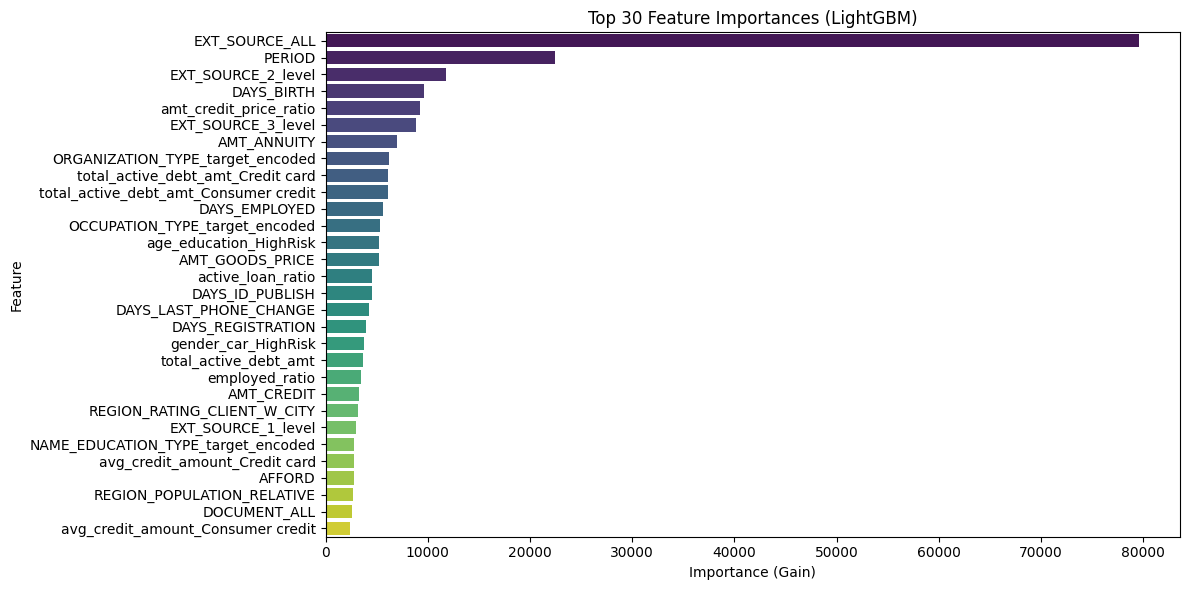

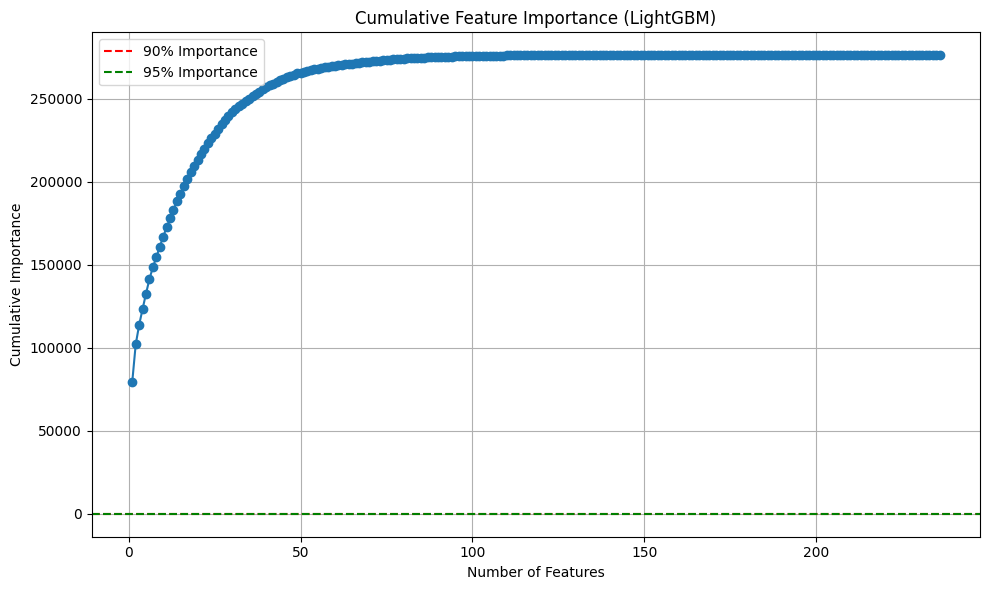

Features covering 90% importance: 1
Features covering 95% importance: 1


Index(['EXT_SOURCE_ALL', 'PERIOD', 'EXT_SOURCE_2_level', 'DAYS_BIRTH',
       'amt_credit_price_ratio', 'EXT_SOURCE_3_level', 'AMT_ANNUITY',
       'ORGANIZATION_TYPE_target_encoded', 'total_active_debt_amt_Credit card',
       'total_active_debt_amt_Consumer credit', 'DAYS_EMPLOYED',
       'OCCUPATION_TYPE_target_encoded', 'age_education_HighRisk',
       'AMT_GOODS_PRICE', 'active_loan_ratio', 'DAYS_ID_PUBLISH',
       'DAYS_LAST_PHONE_CHANGE', 'DAYS_REGISTRATION', 'gender_car_HighRisk',
       'total_active_debt_amt', 'employed_ratio', 'AMT_CREDIT',
       'REGION_RATING_CLIENT_W_CITY', 'EXT_SOURCE_1_level',
       'NAME_EDUCATION_TYPE_target_encoded', 'avg_credit_amount_Credit card',
       'AFFORD', 'REGION_POPULATION_RELATIVE', 'DOCUMENT_ALL',
       'avg_credit_amount_Consumer credit'],
      dtype='object')

In [ ]:
visualize_lgbm_feature_importance(X_train_balanced, y_train_balanced, top_n_features=30)

#### **Training & validation**

In [ ]:
from lightgbm import LGBMClassifier

# Train LightGBM base model
model = LGBMClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_val)

# Predictions
t=0.5
train_pred_proba = model.predict_proba(X_train)[:, 1]
val_pred_proba = model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[42359  3670]
 [   44    53]]
Train/Validation ROC AUC: 0.8041463655778822 0.7499349845691325
Train/Validation F1 Score 0.04061765693185633 0.02774869109947644
Train/Validation Recall: 0.020888479686960525 0.014235831318828902
Train/Validation Precision: 0.7318548387096774 0.5463917525773195


#### **Down sample**

In [ ]:
from lightgbm import LGBMClassifier

In [ ]:
# Train LightGBM base model
model = LGBMClassifier(random_state=42)
model.fit(X_train_balanced, y_train_balanced)

# Predict and evaluate
y_pred = model.predict(X_val)

# Predictions
t=0.5
train_pred_proba = model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

####**Grid search**

In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

In [ ]:
def get_best_model_performance(X_train, y_train, X_val, y_val, grid):
  best_model = grid.best_estimator_
  y_pred = best_model.predict(X_val)

  # Predictions
  t=0.5
  train_pred_proba = best_model.predict_proba(X_train_balanced)[:, 1]
  val_pred_proba = best_model.predict_proba(X_val)[:, 1]
  train_pred = (train_pred_proba >= t).astype(int)
  val_pred = (val_pred_proba >= t).astype(int)

  # Metrics
  train_acc = accuracy_score(y_train_balanced, train_pred)
  val_acc = accuracy_score(y_val, val_pred)
  train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
  val_recall = recall_score(y_val, val_pred, zero_division=0)
  train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
  val_precision = precision_score(y_val, val_pred, zero_division=0)
  train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
  val_roc_auc = roc_auc_score(y_val, val_pred_proba)
  train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
  val_f1 = f1_score(y_val, val_pred, zero_division=0)

  cm = confusion_matrix(y_val, val_pred)
  cm_df = pd.DataFrame(cm, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])

  print(cm_df)
  print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
  print("Train/Validation F1 Score", train_f1, val_f1)
  print("Train/Validation Recall:", train_recall, val_recall)
  print("Train/Validation Precision:", train_precision, val_precision)

##### **Grid search version 1**

In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [300, 500, 700],
    'clf__max_depth': [4, 6, 8],
    'clf__learning_rate': [0.01, 0.05, 0.1],
    'clf__scale_pos_weight' : [4]
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best params: {'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 700, 'clf__scale_pos_weight': 4}
Best ROC AUC score: 0.763393487030092


In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        33182         9221
Actual 1         1507         2216
Train/Validation ROC AUC: 0.8166331917066515 0.7571971963198825
Train/Validation F1 Score 0.5325373134328358 0.29234828496042214
Train/Validation Recall: 0.6672804695592128 0.5952189094816008
Train/Validation Precision: 0.44306892862601255 0.1937571041356999


In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [600, 700, 800],
    'clf__max_depth': [3, 4, 6],
    'clf__learning_rate': [0.03, 0.05, 0.07],
    'clf__scale_pos_weight' : [4]
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best params: {'clf__learning_rate': 0.07, 'clf__max_depth': 3, 'clf__n_estimators': 800, 'clf__scale_pos_weight': 4}
Best ROC AUC score: 0.7644506862475112


In [ ]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_val)

# Predictions
t=0.5
train_pred_proba = best_model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = best_model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[33046  1504]
 [ 9357  2219]]
Train/Validation ROC AUC: 0.8035854665339297 0.7568050165263508
Train/Validation F1 Score 0.5199378796875713 0.2900843192365514
Train/Validation Recall: 0.6550235930486823 0.5960247112543647
Train/Validation Precision: 0.4310436231445017 0.19168970283344852


In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [750, 800],
    'clf__max_depth': [3, 4, 5],
    'clf__learning_rate': [0.06, 0.07, 0.08],
    'clf__scale_pos_weight' : [4]
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'clf__learning_rate': 0.07, 'clf__max_depth': 3, 'clf__n_estimators': 800, 'clf__scale_pos_weight': 4}
Best ROC AUC score: 0.7644506862475112


In [ ]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_val)

# Predictions
t=0.5
train_pred_proba = best_model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = best_model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[33046  1504]
 [ 9357  2219]]
Train/Validation ROC AUC: 0.8035854665339297 0.7568050165263508
Train/Validation F1 Score 0.5199378796875713 0.2900843192365514
Train/Validation Recall: 0.6550235930486823 0.5960247112543647
Train/Validation Precision: 0.4310436231445017 0.19168970283344852


In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [500, 800, 1000],
    'clf__max_depth': [3, 5, 7],
    'clf__learning_rate': [0.05, 0.07, 0.1],
    'clf__scale_pos_weight' : [4],

    'clf__reg_alpha': [0.1],       # L1
    'clf__reg_lambda': [0.1],      # L2
    'clf__min_child_samples': [50],
    'clf__subsample': [0.8],       # Row subsample
    'clf__colsample_bytree': [0.8] # Feature subsample

}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best params: {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 4, 'clf__subsample': 0.8}
Best ROC AUC score: 0.7648561665711622


In [ ]:
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [600, 800, 1000],
    'clf__max_depth': [3, 5],
    'clf__learning_rate': [0.03, 0.05, 0.07],
    'clf__scale_pos_weight' : [2],

    'clf__reg_alpha': [0.1],       # L1
    'clf__reg_lambda': [0.1],      # L2
    'clf__min_child_samples': [50],
    'clf__subsample': [0.8],       # Row subsample
    'clf__colsample_bytree': [0.8] # Feature subsample

}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
Best ROC AUC score: 0.7653350182247634


#### **Evaluate Threshold**

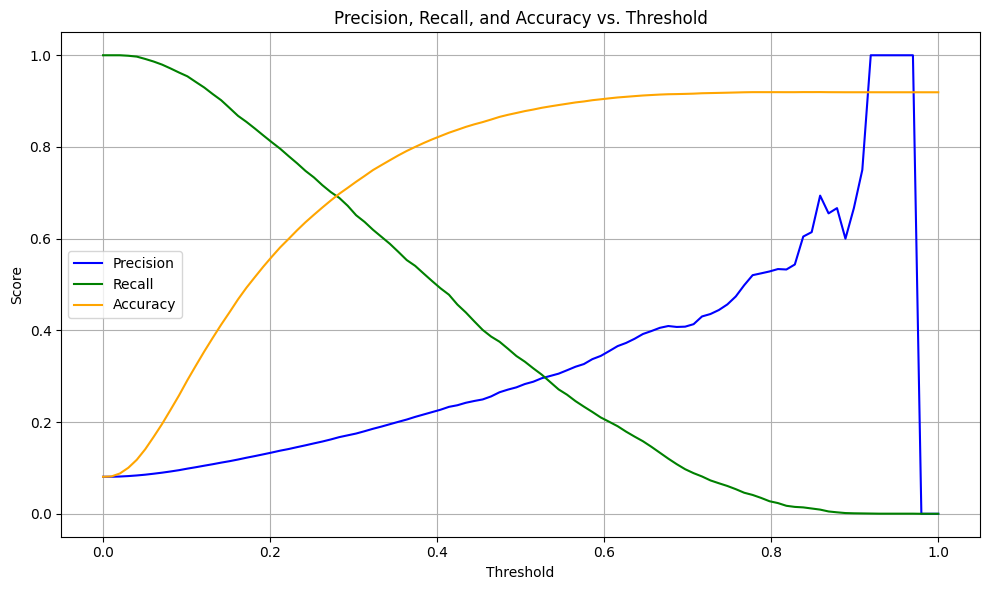

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, accuracy_score
from lightgbm import LGBMClassifier

# Step 1: Fit the model
model = grid.best_estimator_
# model.fit(X_train_balanced, y_train_balanced)

# best_model = LGBMClassifier(random_state=42, verbose=-1, learning_rate=0.7, max_depth=3, n_estimators=800, scale_pos_weight=4, reg_alpha=0.1, reg_lambda=0.1)
#{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
best_model = LGBMClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=2, subsample=0.8)
# # best_model = grid.best_estimator_
best_model.fit(X_train_balanced, y_train_balanced)
# y_pred = best_model.predict(X_val)

# Step 2: Predict probabilities
y_probs = model.predict_proba(X_val)[:, 1]  # Probabilities for class 1

# Step 3: Evaluate at different thresholds
thresholds = np.linspace(0, 1, 100)
precisions = []
recalls = []
accuracies = []

for thresh in thresholds:
    y_pred = (y_probs >= thresh).astype(int)
    precisions.append(precision_score(y_val, y_pred, zero_division=0))
    recalls.append(recall_score(y_val, y_pred))
    accuracies.append(accuracy_score(y_val, y_pred))

# Step 4: Plot
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='blue')
plt.plot(thresholds, recalls, label='Recall', color='green')
plt.plot(thresholds, accuracies, label='Accuracy', color='orange')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision, Recall, and Accuracy vs. Threshold')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Best params: {'clf__learning_rate': 0.07, 'clf__max_depth': 3, 'clf__n_estimators': 800, 'clf__scale_pos_weight': 4}
best_model = LGBMClassifier(random_state=42, verbose=-1, learning_rate=0.7, max_depth=3, n_estimators=800, scale_pos_weight=4, reg_alpha=0.1, reg_lambda=0.1)
#{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
# best_model = LGBClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=2, subsample=0.8)
# best_model = grid.best_estimator_
best_model.fit(X_train_balanced, y_train_balanced)
y_pred = best_model.predict(X_val)

# Predictions
t=0.28
train_pred_proba = best_model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = best_model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[22406   844]
 [19997  2879]]
Train/Validation ROC AUC: 0.9120103314399195 0.71865991292927
Train/Validation F1 Score 0.536871014584254 0.21647430354524605
Train/Validation Recall: 0.9786511681436298 0.7733011012624228
Train/Validation Precision: 0.36989429727260864 0.12585242175205455


In [ ]:
# {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 4, 'clf__subsample': 0.8}
best_model = LGBMClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=4, subsample=0.8)
#{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
# best_model = LGBClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=2, subsample=0.8)
# best_model = grid.best_estimator_
best_model.fit(X_train_balanced, y_train_balanced)
y_pred = best_model.predict(X_val)

# Predictions
t=0.42
train_pred_proba = best_model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = best_model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[25324   871]
 [17079  2852]]
Train/Validation ROC AUC: 0.7997965687392241 0.7586058560705858
Train/Validation F1 Score 0.48724109922837416 0.24114314703644205
Train/Validation Recall: 0.8284612728737484 0.7660488853075477
Train/Validation Precision: 0.34510283330936287 0.14309367317244492


In [ ]:
# {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 4, 'clf__subsample': 0.8}
# best_model = LGBClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=4, subsample=0.8)
#{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
best_model = LGBMClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=2, subsample=0.8)
# best_model = grid.best_estimator_
best_model.fit(X_train_balanced, y_train_balanced)
y_pred = best_model.predict(X_val)

# Predictions
t=0.28
train_pred_proba = best_model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = best_model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[26222   925]
 [16181  2798]]
Train/Validation ROC AUC: 0.8001579457220208 0.758442547063333
Train/Validation F1 Score 0.4929695404905621 0.24649810589375384
Train/Validation Recall: 0.8130394751985268 0.7515444533977975
Train/Validation Precision: 0.3537202082916083 0.1474261025343801


### **Risk Classification**

In [ ]:
# {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 4, 'clf__subsample': 0.8}
# best_model = LGBClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=4, subsample=0.8)
#{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
best_model = LGBMClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=2, subsample=0.8)
# best_model = grid.best_estimator_
best_model.fit(X_train_balanced, y_train_balanced)
y_pred = best_model.predict(X_test)

# Predictions
t=0.28
pred_proba = best_model.predict_proba(X_test)[:, 1]
pred = (pred_proba >= t).astype(int)

# Metrics
acc = accuracy_score(y_test, pred)
recall = recall_score(y_test, pred, zero_division=0)
precision = precision_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, pred_proba)
f1 = f1_score(y_test, pred, zero_division=0)

print(confusion_matrix(pred, y_test))
print("Test ROC AUC:", roc_auc)
print("Test F1 Score", f1)
print("Test Recall:", recall)
print("Test Precision:", precision)

[[26240   827]
 [16163  2897]]
Test ROC AUC: 0.770503351137453
Test F1 Score 0.2543012640449438
Test Recall: 0.7779269602577873
Test Precision: 0.15199370409233998


In [ ]:
# {'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 4, 'clf__subsample': 0.8}
# best_model = LGBClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=4, subsample=0.8)
#{'clf__colsample_bytree': 0.8, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__min_child_samples': 50, 'clf__n_estimators': 1000, 'clf__reg_alpha': 0.1, 'clf__reg_lambda': 0.1, 'clf__scale_pos_weight': 2, 'clf__subsample': 0.8}
best_model = LGBMClassifier(random_state=42, verbose=-1, colsample_bytree=0.8, learning_rate=0.05, max_depth=3, min_child_samples=50, n_estimators=1000, reg_alpha=0.1, reg_lambda=0.1, scale_pos_weight=2, subsample=0.8)
# best_model = grid.best_estimator_
best_model.fit(X_train_balanced, y_train_balanced)
y_pred = best_model.predict(X)

# Predictions
t=0.28
pred_proba = best_model.predict_proba(X)[:, 1]
pred = (pred_proba >= t).astype(int)

# Metrics
acc = accuracy_score(y, pred)
recall = recall_score(y, pred, zero_division=0)
precision = precision_score(y, pred, zero_division=0)
roc_auc = roc_auc_score(y, pred_proba)
f1 = f1_score(y, pred, zero_division=0)

print(confusion_matrix(pred, y))
print("ROC AUC:", roc_auc)
print("F1 Score", f1)
print("Recall:", recall)
print("Precision:", precision)

[[175604   5010]
 [107081  19815]]
ROC AUC: 0.7862867413280016
F1 Score 0.2612031294283586
Recall: 0.7981873111782477
Precision: 0.15615149413693102


In [ ]:
pd.DataFrame(pred_proba).describe()

,0
count,307510.000000
mean,0.279718
std,0.185705
min,0.002069
25%,0.133250
50%,0.234289
75%,0.390674
max,0.987713


In [ ]:
probs = pd.Series(pred_proba)
q1 = probs.quantile(0.25)
q3 = probs.quantile(0.75)
print(q1, ' ', q3)

0.13339446996058185   0.3912141622780006


In [ ]:
df_predicted = df_processed_1.copy()
df_predicted['risk'] = pred_proba
df_predicted.head()

,SK_ID_CURR,TARGET,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,...,NAME_FAMILY_STATUS_Unknown,NAME_FAMILY_STATUS_Widow,CODE_GENDER_target_encoded,NAME_INCOME_TYPE_target_encoded,NAME_EDUCATION_TYPE_target_encoded,OCCUPATION_TYPE_target_encoded,NAME_HOUSING_TYPE_target_encoded,ORGANIZATION_TYPE_target_encoded,NAME_TYPE_SUITE_frequency_encoded,risk
0,117337,0,0,1,1,760846.5,4050000.0,146002.5,4050000.0,0.072508,...,False,False,0.101417,0.074843,0.053555,0.062149,0.065781,0.094479,0.812387,0.030198
1,120926,0,1,0,2,783000.0,4050000.0,258025.5,4050000.0,0.009549,...,False,False,0.101417,0.074843,0.053555,0.062149,0.077957,0.101248,0.812387,0.013535
2,228135,0,0,0,2,864900.0,4050000.0,102384.0,4050000.0,0.025164,...,False,False,0.101417,0.074843,0.053555,0.062149,0.077957,0.092994,0.812387,0.039138
3,238782,0,1,1,1,931365.0,4050000.0,102514.5,4050000.0,0.030755,...,False,False,0.101417,0.074843,0.053555,0.062149,0.077957,0.092790,0.812387,0.081854
4,240007,0,0,0,0,587250.0,4050000.0,106969.5,4050000.0,0.046220,...,False,False,0.101417,0.074843,0.053555,0.080729,0.077957,0.110398,0.812387,0.261086


In [ ]:
import pandas as pd

df_predicted['risk_group'] = pd.cut(df_predicted['risk'], bins=[0, q1, q3, 1.0], labels=['Low Risk', 'Medium Risk', 'High Risk'], include_lowest=True)
df_predicted.head()

,SK_ID_CURR,TARGET,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,...,NAME_FAMILY_STATUS_Widow,CODE_GENDER_target_encoded,NAME_INCOME_TYPE_target_encoded,NAME_EDUCATION_TYPE_target_encoded,OCCUPATION_TYPE_target_encoded,NAME_HOUSING_TYPE_target_encoded,ORGANIZATION_TYPE_target_encoded,NAME_TYPE_SUITE_frequency_encoded,risk,risk_group
0,117337,0,0,1,1,760846.5,4050000.0,146002.5,4050000.0,0.072508,...,False,0.101417,0.074843,0.053555,0.062149,0.065781,0.094479,0.812387,0.030198,Low Risk
1,120926,0,1,0,2,783000.0,4050000.0,258025.5,4050000.0,0.009549,...,False,0.101417,0.074843,0.053555,0.062149,0.077957,0.101248,0.812387,0.013535,Low Risk
2,228135,0,0,0,2,864900.0,4050000.0,102384.0,4050000.0,0.025164,...,False,0.101417,0.074843,0.053555,0.062149,0.077957,0.092994,0.812387,0.039138,Low Risk
3,238782,0,1,1,1,931365.0,4050000.0,102514.5,4050000.0,0.030755,...,False,0.101417,0.074843,0.053555,0.062149,0.077957,0.092790,0.812387,0.081854,Low Risk
4,240007,0,0,0,0,587250.0,4050000.0,106969.5,4050000.0,0.046220,...,False,0.101417,0.074843,0.053555,0.080729,0.077957,0.110398,0.812387,0.261086,Medium Risk


In [ ]:
df_predicted.to_csv('/content/drive/MyDrive/EY_predicted.csv', index=False)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

In [ ]:
df_predicted = pd.read_csv('/content/drive/MyDrive/EY_predicted.csv')
# X = df_predicted.iloc[:,2:-2]
# X.head(3)
# y = df_predicted['risk_group']

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,...,total_active_debt_amt_Loan for purchase of shares (margin lending),total_closed_debt_amt_Loan for purchase of shares (margin lending),outstanding_closed_debt_cnt_Loan for purchase of shares (margin lending),age_Gender_HighRisk,age_education_HighRisk,gender_car_HighRisk,income_gender_HighRisk,income_age_HighRisk,amt_credit_price_ratio,employed_ratio
0,Cash loans,M,0,1,1,760846.5,4050000.0,146002.5,4050000.0,Unaccompanied,...,0.0,0.0,0.0,0,0,1,0,0,1.0,0.107221
1,Cash loans,M,1,0,2,783000.0,4050000.0,258025.5,4050000.0,Unaccompanied,...,0.0,0.0,0.0,0,0,0,0,0,1.0,0.013245
2,Cash loans,M,0,0,2,864900.0,4050000.0,102384.0,4050000.0,Unaccompanied,...,0.0,0.0,0.0,0,0,1,0,0,1.0,0.042303


#### **SHAP Values**

In [ ]:
# Background (baseline)
from sklearn.model_selection import train_test_split
booster = best_model.booster_
# stratified sampling
# _, X_background, _, _ = train_test_split(
#     X, y, stratify=y, test_size=100, random_state=42)

# SHAP sample - oversample positive class
defaults = X[y == 1].sample(20000, random_state=42)
non_defaults = X[y == 0].sample(80000, random_state=42)
X_sample = pd.concat([defaults, non_defaults])

# Explain
explainer = shap.TreeExplainer(booster)
shap_values = explainer.shap_values(X_sample)

/usr/local/lib/python3.11/dist-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


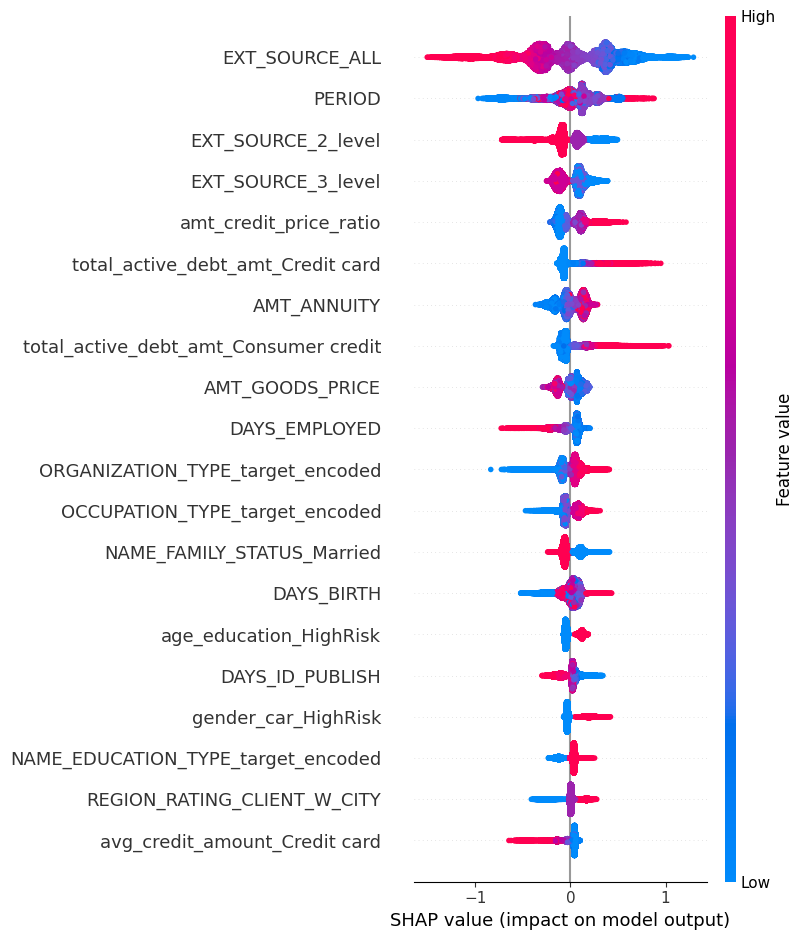

In [ ]:
# Plot (positive class = index 1)
shap.summary_plot(shap_values, X_sample)

In [ ]:
shap_values.shape

In [ ]:
X.shape

(307510, 236)

In [ ]:
import pandas as pd

# Assume X_with_group already has 'risk_group' column
X_with_group = X.copy()
X_with_group['risk_group'] = df_predicted['risk_group'].values
X_with_group['target'] = y.values  # add target for sampling

sampled_dfs = []

# Set your positive:negative ratio and total samples per group
pos_neg_ratio = 1 / 4
total_samples_per_group = 40000  # adjust to your scale

for group in ['Low Risk', 'Medium Risk', 'High Risk']:
    group_df = X_with_group[X_with_group['risk_group'] == group]

    # Calculate how many positives and negatives based on ratio and total samples
    n_pos = int(total_samples_per_group / (1 + 4))  # positive samples
    n_neg = total_samples_per_group - n_pos         # negative samples

    # Sample positives and negatives separately with replacement if needed
    pos_samples = group_df[group_df['target'] == 1].sample(n=n_pos, replace=True, random_state=42)
    neg_samples = group_df[group_df['target'] == 0].sample(n=n_neg, replace=True, random_state=42)

    sampled_group = pd.concat([pos_samples, neg_samples])
    sampled_dfs.append(sampled_group)

# Combine all groups
X_sampled = pd.concat(sampled_dfs).reset_index(drop=True)

# Separate features and target/group columns
X_sampled_features = X_sampled.drop(columns=['target', 'risk_group'])
sampled_groups = X_sampled['risk_group'].values
sampled_targets = X_sampled['target'].values

In [ ]:
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_sampled_features)

/usr/local/lib/python3.11/dist-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


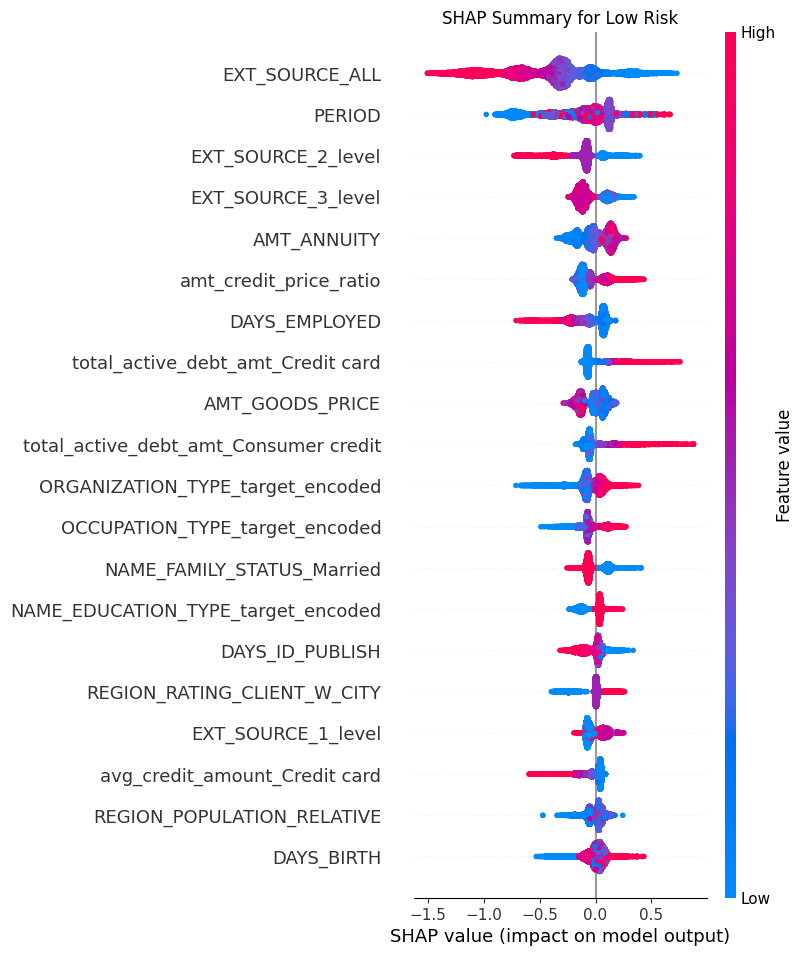

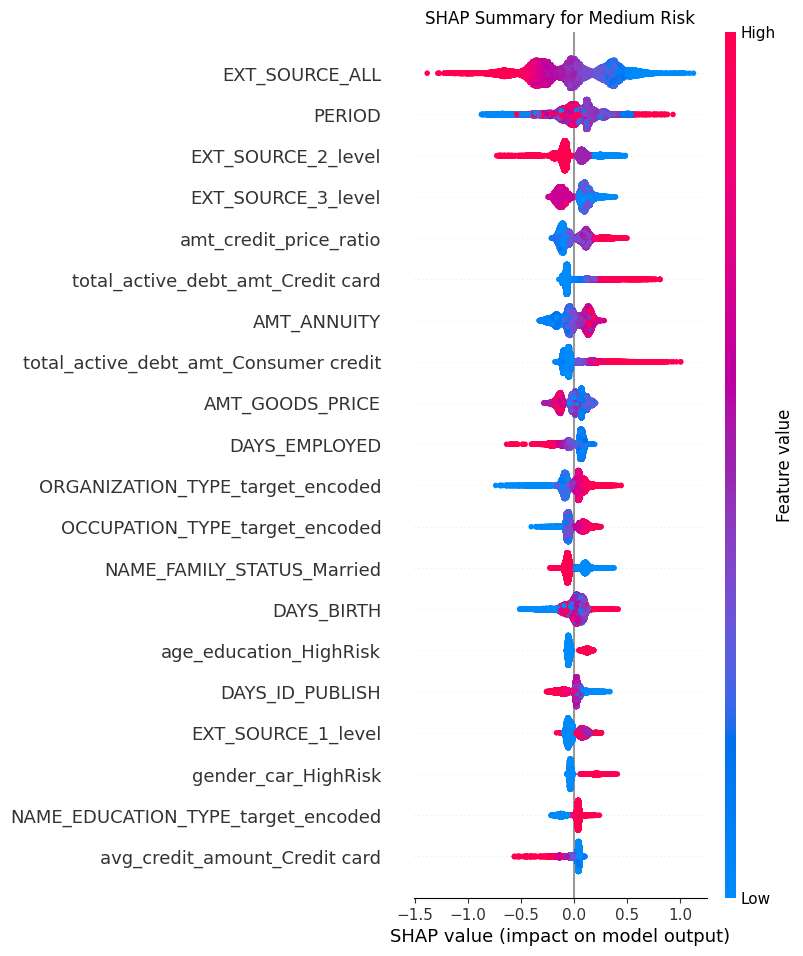

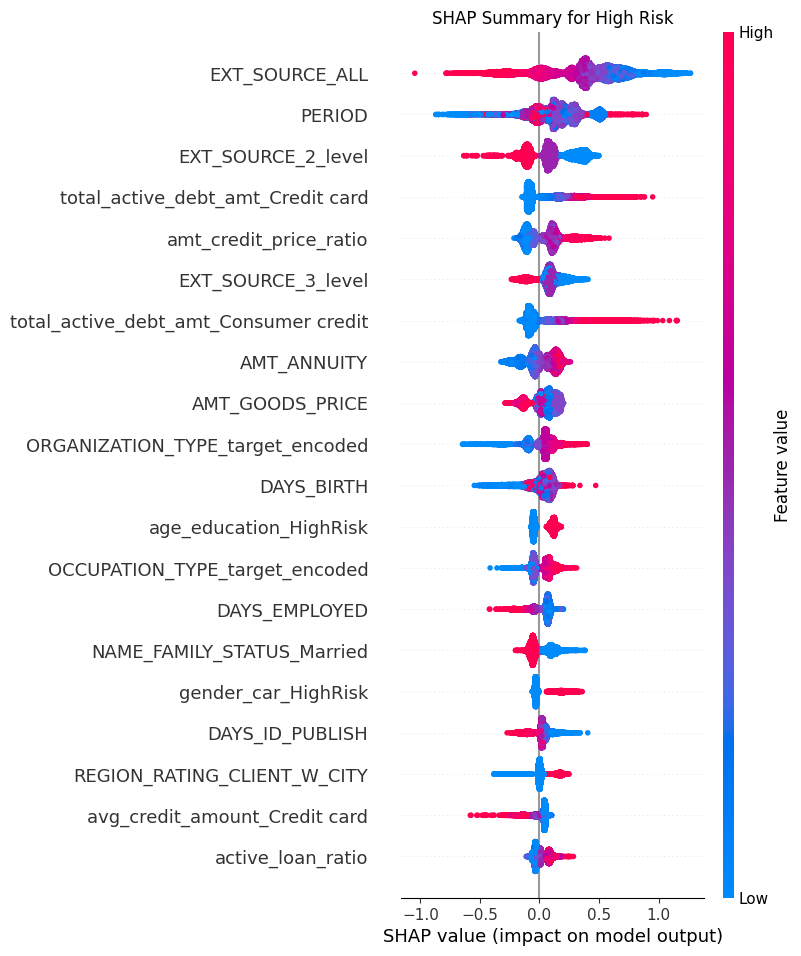

In [ ]:
import matplotlib.pyplot as plt

for group in ['Low Risk', 'Medium Risk', 'High Risk']:
    idx = [i for i, g in enumerate(sampled_groups) if g == group]

    # For binary classification, shap_values is a list (classes)
    shap.summary_plot(shap_values[idx], X_sampled_features.iloc[idx], show=False)
    plt.title(f"SHAP Summary for {group}")
    plt.show()

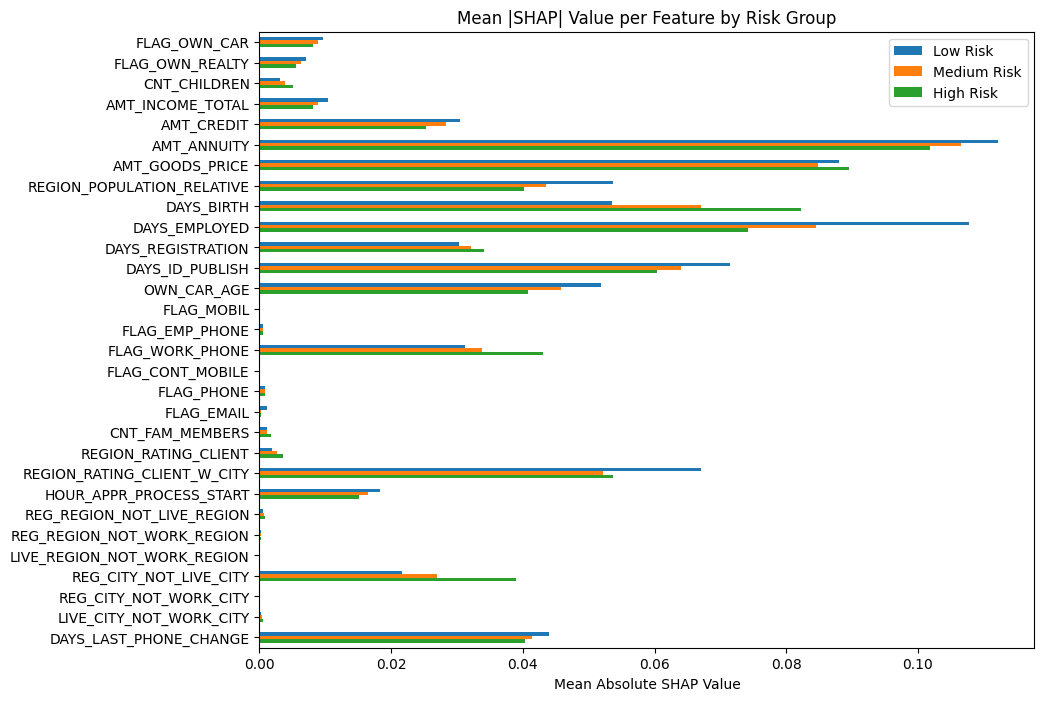

In [ ]:
group_shap_means = {}
for group in ['Low Risk', 'Medium Risk', 'High Risk']:
    group_indices = X_sampled[X_sampled['risk_group'] == group].index
    group_shap = pd.DataFrame(shap_values, columns= X_sampled_features.columns).iloc[group_indices]
    group_shap_means[group] = group_shap.abs().mean()

# Step 6: Combine and plot
df_group_means = pd.DataFrame(group_shap_means)
df_group_means.head(30).plot.barh(figsize=(10, 8))
plt.title("Mean |SHAP| Value per Feature by Risk Group")
plt.xlabel("Mean Absolute SHAP Value")
plt.gca().invert_yaxis()
plt.show()

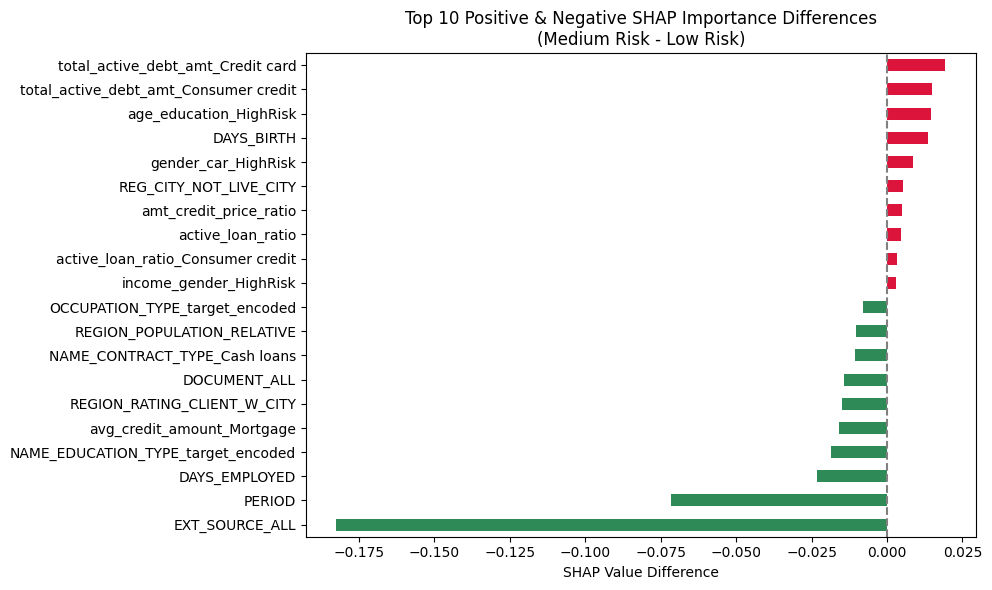

In [ ]:
diff = df_group_means['Medium Risk'] - df_group_means['Low Risk']

top_positive = diff.sort_values(ascending=False).head(10)
top_negative = diff.sort_values(ascending=True).head(10)
combined = pd.concat([top_positive, top_negative])

plt.figure(figsize=(10, 6))
combined.sort_values().plot(kind='barh', color=['crimson' if v < 0 else 'seagreen' for v in combined])
plt.axvline(0, color='gray', linestyle='--')
plt.title("Top 10 Positive & Negative SHAP Importance Differences\n(Medium Risk - Low Risk)")
plt.xlabel("SHAP Value Difference")
plt.tight_layout()
plt.show()

####**Feature Importance**

Top 20 features: ['EXT_SOURCE_ALL', 'PERIOD', 'EXT_SOURCE_2_level', 'EXT_SOURCE_3_level', 'amt_credit_price_ratio', 'DAYS_BIRTH', 'total_active_debt_amt_Consumer credit', 'total_active_debt_amt_Credit card', 'age_education_HighRisk', 'ORGANIZATION_TYPE_target_encoded', 'OCCUPATION_TYPE_target_encoded', 'AMT_ANNUITY', 'gender_car_HighRisk', 'AMT_GOODS_PRICE', 'DAYS_EMPLOYED', 'active_loan_ratio', 'REGION_RATING_CLIENT_W_CITY', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'total_active_debt_amt']


<ipython-input-116-5e8f0fb19d6f>:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance_sorted.head(top_n_features),


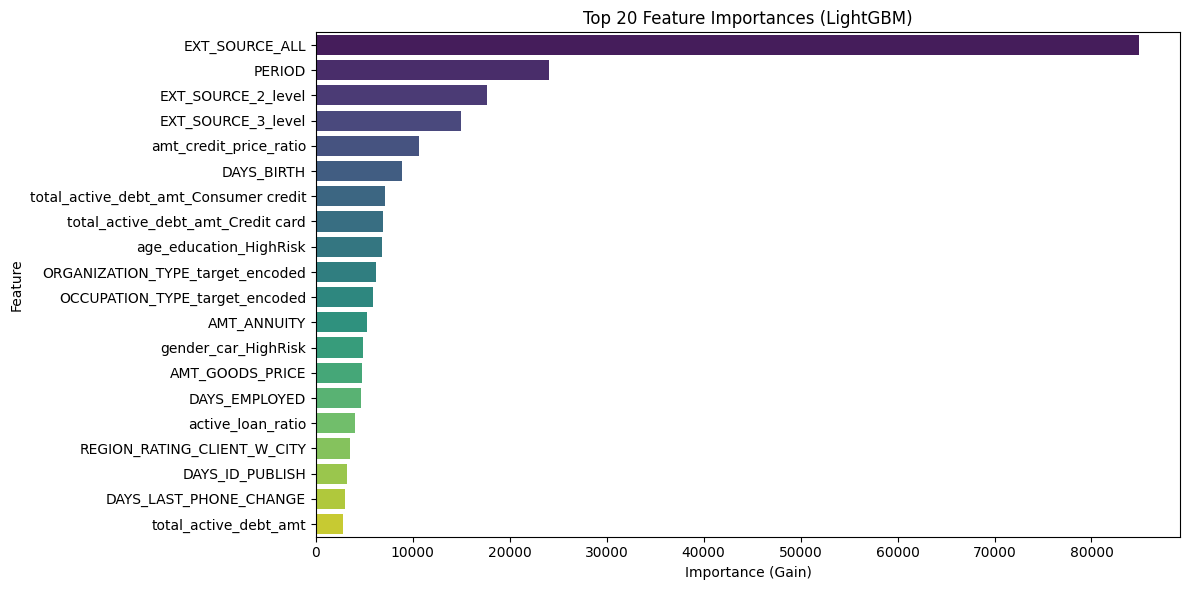

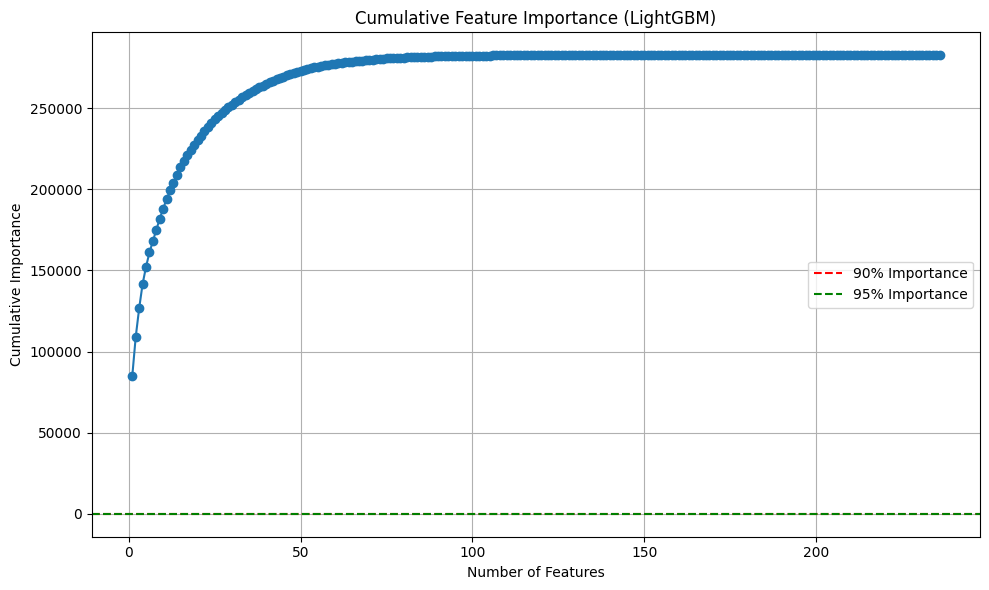

Features covering 90% importance: 1
Features covering 95% importance: 1


Index(['EXT_SOURCE_ALL', 'PERIOD', 'EXT_SOURCE_2_level', 'EXT_SOURCE_3_level',
       'amt_credit_price_ratio', 'DAYS_BIRTH',
       'total_active_debt_amt_Consumer credit',
       'total_active_debt_amt_Credit card', 'age_education_HighRisk',
       'ORGANIZATION_TYPE_target_encoded', 'OCCUPATION_TYPE_target_encoded',
       'AMT_ANNUITY', 'gender_car_HighRisk', 'AMT_GOODS_PRICE',
       'DAYS_EMPLOYED', 'active_loan_ratio', 'REGION_RATING_CLIENT_W_CITY',
       'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'total_active_debt_amt'],
      dtype='object')

In [ ]:
visualize_lgbm_feature_importance(X_train_balanced, y_train_balanced, model=best_model, top_n_features=20)

### **Find Most representative**

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

risk_group = X_with_group['risk_group']

X_with_group_feature = X_with_group.drop(columns=['target', 'risk_group'])

# 1. Standardize features (important for fair distance calculation)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_with_group_feature)  # use your X dataframe (no target column)

# 2. Add risk group back
X_scaled_df = pd.DataFrame(X_scaled, columns=X_with_group_feature.columns)
X_scaled_df['risk_group'] = risk_group.values  # or however you defined it

# 3. Find the most representative data point in each group
representative_indices = {}

for group in ['Low Risk', 'Medium Risk', 'High Risk']:
    group_df = X_scaled_df[X_scaled_df['risk_group'] == group].drop('risk_group', axis=1)
    group_mean = group_df.mean().values
    distances = np.linalg.norm(group_df.values - group_mean, axis=1)
    min_idx = distances.argmin()
    representative_index = group_df.index[min_idx]
    representative_indices[group] = representative_index

NameError: name 'X_with_group' is not defined

####**Archive**

In [ ]:
model = LGBMClassifier(scale_pos_weight=4, learning_rate=0.1, max_depth=3, n_estimator=600, random_state=42, verbose=-1)

model.fit(X_train_balanced, y_train_balanced)

# Predict and evaluate
y_pred = model.predict(X_val)

# Predictions
t=0.5
train_pred_proba = model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[29408  1208]
 [12995  2515]]
Train/Validation ROC AUC: 0.7677267079961526 0.7477546848499441
Train/Validation F1 Score 0.4809027777777778 0.2615296625591431
Train/Validation Recall: 0.7013465300955231 0.6755304861670696
Train/Validation Precision: 0.36589612728910237 0.16215344938749193


In [ ]:
# 'clf__learning_rate': 0.075, 'clf__max_depth': 4, 'clf__n_estimators': 500, 'clf__scale_pos_weight': 4

from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [600, 700],
    'clf__max_depth': [3, 4, 5],
    'clf__learning_rate': [0.05, 0.075, 0.1],
    'clf__scale_pos_weight' : [4]
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

串流輸出內容已截斷至最後 5000 行。
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

In [ ]:
param_grid = {
    'n_estimators': [150, 300, 500],
    'max_depth': [5, 7, 10, 15],
    'learning_rate': [0.01, 0.05, 0.1, 0.3]
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}
Best ROC AUC score: 0.7551440074216642


In [ ]:
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, f1_score, precision_score, roc_curve
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    # 'num_leaves': [31, 50],
    'n_estimators': [100, 150, 200],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'scale_pos_weight': [3, 5],
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 72 candidates, totalling 216 fits
Best params: {'learning_rate': 0.05, 'max_depth': 10, 'n_estimators': 200, 'scale_pos_weight': 3}
Best ROC AUC score: 0.7541290280086148


In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        29476        12927
Actual 1         1232         2491
Train/Validation ROC AUC: 0.8040767140942693 0.7483940357176393
Train/Validation F1 Score 0.5701315381549227 0.26027898228932655
Train/Validation Recall: 0.74076418460122 0.6690840719849583
Train/Validation Precision: 0.4633909287257019 0.16156440524062785


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    # 'num_leaves': [31, 50],
    'n_estimators': [200, 300, 500],
    'max_depth': [8, 10, 12],
    'learning_rate': [0.03, 0.05, 0.07],
    'scale_pos_weight': [3],
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best params: {'learning_rate': 0.05, 'max_depth': 12, 'n_estimators': 200, 'scale_pos_weight': 3}
Best ROC AUC score: 0.7544575611681229


In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        29485        12918
Actual 1         1230         2493
Train/Validation ROC AUC: 0.8046021954023125 0.7480222085807269
Train/Validation F1 Score 0.5710808717778515 0.2605832549388523
Train/Validation Recall: 0.7426055932788583 0.669621273166801
Train/Validation Precision: 0.46392493798756157 0.161767568619817


#####**Grid search version 2: after PCA kmenas clustering re-sample**
on previous optimal parameters

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define pipeline
pipeline = Pipeline([
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('clf', LGBMClassifier(random_state=42))
])

param_grid = {
    # 'num_leaves': [31, 50],
    'clf__n_estimators': [350, 500, 700],
    'clf__max_depth': [3, 6, 9],
    'clf__learning_rate': [0.05, 0.1],
    'clf__scale_pos_weight': [5],
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 500, 'clf__scale_pos_weight': 5}
Best ROC AUC score: 0.7599103636209054


In [ ]:
# Get all grid search results
results = pd.DataFrame(grid.cv_results_)

# Keep only relevant columns for readability
columns_to_show = ['params', 'mean_test_roc_auc', 'mean_test_recall', 'mean_test_f1', 'rank_test_roc_auc']
results = results[columns_to_show]

# Sort by best ROC AUC
results = results.sort_values(by='mean_test_roc_auc', ascending=False)

# Print
pd.set_option('display.max_colwidth', None)  # So 'params' isn't truncated
print(results)

                                                                                                     params  \
10   {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 500, 'clf__scale_pos_weight': 5}   
11   {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 700, 'clf__scale_pos_weight': 5}   
2   {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 700, 'clf__scale_pos_weight': 5}   
9    {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 350, 'clf__scale_pos_weight': 5}   
1   {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 500, 'clf__scale_pos_weight': 5}   
6   {'clf__learning_rate': 0.05, 'clf__max_depth': 9, 'clf__n_estimators': 350, 'clf__scale_pos_weight': 5}   
3   {'clf__learning_rate': 0.05, 'clf__max_depth': 6, 'clf__n_estimators': 350, 'clf__scale_pos_weight': 5}   
7   {'clf__learning_rate': 0.05, 'clf__max_depth': 9, 'clf__n_estimators': 500, 'clf__scale_pos_weight': 5}   
4

In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        29896        12507
Actual 1         1206         2517
Train/Validation ROC AUC: 0.792641373067329 0.7533436396449962
Train/Validation F1 Score 0.45694066412629286 0.2685229636741879
Train/Validation Recall: 0.7245367706295316 0.6760676873489122
Train/Validation Precision: 0.3336955369447684 0.16753194888178913


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    # 'num_leaves': [31, 50],
    'n_estimators': [400, 500, 600],
    'max_depth': [4, 5, 6],
    'learning_rate': [0.05, 0.1],
    'scale_pos_weight': [5],
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 600, 'scale_pos_weight': 5}
Best ROC AUC score: 0.4217211684050626


In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        30191        12212
Actual 1         1287         2436
Train/Validation ROC AUC: 0.8296292528528185 0.750002643058193
Train/Validation F1 Score 0.49386099742587825 0.2652005878830766
Train/Validation Recall: 0.7672919783634481 0.6543110394842868
Train/Validation Precision: 0.36410802544987847 0.1663025669033315


#### **[Archive]Grid Search Prevent overfitting/ with Regularization**

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'num_leaves': [31, 63, 127],
    'n_estimators': [300, 500, 700],
    'min_child_samples' : [100, 300, 500],
    # 'max_depth': [4, 5, 6],
    'learning_rate': [0.05, 0.1],
    'scale_pos_weight': [5],
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=1)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best params: {'learning_rate': 0.1, 'min_child_samples': 500, 'n_estimators': 600, 'num_leaves': 31, 'scale_pos_weight': 5}
Best ROC AUC score: 0.41612279211866277


In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        31494        10909
Actual 1         1417         2306
Train/Validation ROC AUC: 0.8907205473222612 0.744701970056713
Train/Validation F1 Score 0.5713729611896142 0.2722871649545401
Train/Validation Recall: 0.8446311428242606 0.6193929626645178
Train/Validation Precision: 0.43170588235294116 0.17449867574725691


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'num_leaves': [31],
    'n_estimators': [600],
    'min_child_samples' : [1500],
    # 'max_depth': [4, 5, 6],
    'bagging_fraction': [0.8],
    'learning_rate': [0.1],
    'scale_pos_weight': [5],
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=2)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
[CV] END bagging_fraction=0.8, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  22.5s
[CV] END bagging_fraction=0.8, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  21.9s
[CV] END bagging_fraction=0.8, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  16.7s
[CV] END bagging_fraction=0.9, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  17.9s
[CV] END bagging_fraction=0.9, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  17.3s
[CV] END bagging_fraction=0.9, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  14.0s
[CV] END bagging_fraction=1.0, learning_rate=0.1, min_child_sampl

In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        31161        11242
Actual 1         1372         2351
Train/Validation ROC AUC: 0.86807889727379 0.7456789609191555
Train/Validation F1 Score 0.5415578429866339 0.27154077154077155
Train/Validation Recall: 0.8113706985844171 0.6314799892559764
Train/Validation Precision: 0.4064103303164812 0.172956668873685


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'num_leaves': [31],
    'n_estimators': [600],
    'min_child_samples' : [1500],
    # 'max_depth': [4, 5, 6],
    'bagging_fraction': [0.8],
    'feature_fraction': [1.0],
    'learning_rate': [0.1],
    'scale_pos_weight': [5],
    'lambda_l1': [0, 0.1, 1],
    'lambda_l2': [0, 0.1, 1]
}

model = LGBMClassifier(random_state=42, verbose=-1)

grid = GridSearchCV(model, param_grid, cv=3, scoring=['roc_auc', 'recall', 'f1'], refit='roc_auc', verbose=2)
grid.fit(X_train_balanced, y_train_balanced)

print("Best params:", grid.best_params_)
print("Best ROC AUC score:", grid.best_score_)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
[CV] END bagging_fraction=0.8, feature_fraction=1.0, lambda_l1=0, lambda_l2=0, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  19.5s
[CV] END bagging_fraction=0.8, feature_fraction=1.0, lambda_l1=0, lambda_l2=0, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  13.7s
[CV] END bagging_fraction=0.8, feature_fraction=1.0, lambda_l1=0, lambda_l2=0, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  13.6s
[CV] END bagging_fraction=0.8, feature_fraction=1.0, lambda_l1=0, lambda_l2=0.1, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale_pos_weight=5; total time=  13.4s
[CV] END bagging_fraction=0.8, feature_fraction=1.0, lambda_l1=0, lambda_l2=0.1, learning_rate=0.1, min_child_samples=1500, n_estimators=600, num_leaves=31, scale

In [ ]:
get_best_model_performance(X_train_balanced, y_train_balanced, X_val, y_val, grid)

          Predicted 0  Predicted 1
Actual 0        31161        11242
Actual 1         1372         2351
Train/Validation ROC AUC: 0.86807889727379 0.7456789609191555
Train/Validation F1 Score 0.5415578429866339 0.27154077154077155
Train/Validation Recall: 0.8113706985844171 0.6314799892559764
Train/Validation Precision: 0.4064103303164812 0.172956668873685


In [ ]:
model = LGBMClassifier(scale_pos_weight=5, learning_rate=0.05, max_depth=12, n_estimator=200, bagging_fraction=0.8, lambda_l1=0.1, lambda_l2=0.1, random_state=42, verbose=-1)

model.fit(X_train_balanced, y_train_balanced)

# Predict and evaluate
y_pred = model.predict(X_val)

# Predictions
t=0.5
train_pred_proba = model.predict_proba(X_train_balanced)[:, 1]
val_pred_proba = model.predict_proba(X_val)[:, 1]
train_pred = (train_pred_proba >= t).astype(int)
val_pred = (val_pred_proba >= t).astype(int)

# Metrics
train_acc = accuracy_score(y_train_balanced, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_recall = recall_score(y_train_balanced, train_pred, zero_division=0)
val_recall = recall_score(y_val, val_pred, zero_division=0)
train_precision = precision_score(y_train_balanced, train_pred, zero_division=0)
val_precision = precision_score(y_val, val_pred, zero_division=0)
train_roc_auc = roc_auc_score(y_train_balanced, train_pred_proba)
val_roc_auc = roc_auc_score(y_val, val_pred_proba)
train_f1 = f1_score(y_train_balanced, train_pred, zero_division=0)
val_f1 = f1_score(y_val, val_pred, zero_division=0)

print(confusion_matrix(val_pred, y_val))
print("Train/Validation ROC AUC:", train_roc_auc, val_roc_auc)
print("Train/Validation F1 Score", train_f1, val_f1)
print("Train/Validation Recall:", train_recall, val_recall)
print("Train/Validation Precision:", train_precision, val_precision)

[[26021   921]
 [16382  2802]]
Train/Validation ROC AUC: 0.7883741509011789 0.7508959618878672
Train/Validation F1 Score 0.4837759140759856 0.24464137599860306
Train/Validation Recall: 0.7983082057774197 0.7526188557614827
Train/Validation Precision: 0.34704190118824263 0.14605921601334446


####**列出模型真的抓出來的案例，是因為哪些原因所以模型有效**
####**尤其是如果有奇怪（人類判斷不出來）的案例被模型抓到 可以秀出來**

#### **Grid Search, Random Search, Baysian Search**

#**----------------------------------------- 以下忽略 -------------------------------------------**

### **Only 8% Target = 1**

In [ ]:
df_processed['TARGET'].value_counts()/ df.shape[0] * 100.00

,count
TARGET,
0,91.927118
1,8.072882


### **List the Columns with NaN values & its description**

In [ ]:
df_null_info = df.isna().sum().reset_index()
has_null_info = df_null_info[df_null_info[0] > 0].sort_values(by=0, ascending=False)
has_null_info.columns = ['Row', 'NaN_count']
has_null_info['NaN_percentage'] = has_null_info['NaN_count']/df.shape[0]
has_null_info = has_null_info.merge(col_df, on='Row', how='inner')[['Row', 'NaN_count', 'NaN_percentage', 'Description', 'Special']]
display(HTML(f'<div style="max-height: 300px; overflow-y: auto;">{has_null_info.to_html()}</div>'))

NameError: name 'col_df' is not defined

#### **get columns that has over 20% NaN**

In [ ]:
cols_to_drop = has_null_info[has_null_info['NaN_percentage'] > 0.2]['Row']
display(HTML(f'<div style="max-height: 300px; overflow-y: auto;">{cols_to_drop.to_frame().to_html()}</div>'))

,Row
0,COMMONAREA_MEDI
1,COMMONAREA_MODE
2,COMMONAREA_AVG
3,NONLIVINGAPARTMENTS_MODE
4,NONLIVINGAPARTMENTS_MEDI
5,NONLIVINGAPARTMENTS_AVG
6,FONDKAPREMONT_MODE
7,LIVINGAPARTMENTS_AVG
8,LIVINGAPARTMENTS_MEDI
9,LIVINGAPARTMENTS_MODE


#### **check the correlation with target**
to identify whether this column is okay to drop
- check only the numerical + NaN>20% columns
- but can drop all NaN > 20% just to test

In [ ]:
num_drop_columns = list(set(numerical_cols) & set(cols_to_drop))
print(num_drop_columns)
print(df[num_drop_columns].corrwith(df['TARGET']))

['COMMONAREA_MODE', 'BASEMENTAREA_AVG', 'FLOORSMAX_MODE', 'FLOORSMIN_MEDI', 'ENTRANCES_MODE', 'YEARS_BEGINEXPLUATATION_AVG', 'COMMONAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'ENTRANCES_AVG', 'BASEMENTAREA_MEDI', 'NONLIVINGAREA_MEDI', 'EXT_SOURCE_1', 'FLOORSMIN_MODE', 'YEARS_BUILD_MODE', 'BASEMENTAREA_MODE', 'NONLIVINGAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'ENTRANCES_MEDI', 'ELEVATORS_MEDI', 'LIVINGAPARTMENTS_AVG', 'FLOORSMIN_AVG', 'NONLIVINGAPARTMENTS_AVG', 'YEARS_BUILD_MEDI', 'FLOORSMAX_AVG', 'OWN_CAR_AGE', 'ELEVATORS_MODE', 'TOTALAREA_MODE', 'APARTMENTS_AVG', 'APARTMENTS_MEDI', 'APARTMENTS_MODE', 'FLOORSMAX_MEDI', 'LIVINGAREA_AVG', 'LANDAREA_MEDI', 'LIVINGAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'ELEVATORS_AVG', 'COMMONAREA_AVG', 'NONLIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_MODE', 'YEARS_BUILD_AVG', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'LANDAREA_MODE', 'LANDAREA_AVG', 'YEARS_BEGINEXPLUATATION_MEDI']
COMMONAREA_MODE                -0.016340
BASEMENTAREA_AVG               -0.022746


In [ ]:
df_processed = df_processed.drop(columns=cols_to_drop)
print(df_processed.columns)

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE',
       'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
       'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'FLAG_MOBIL',
       'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE',
       'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT',
       'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START',
       'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION',
       'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
       'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY',
       'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_2',
       'EXT_SOURCE_3', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
       

#### **check that it is really dropped**

In [ ]:
print(set(df.columns) - (set(df.columns) & set(df_processed.columns)))

{'COMMONAREA_MODE', 'BASEMENTAREA_AVG', 'FLOORSMAX_MODE', 'FLOORSMIN_MEDI', 'ENTRANCES_MODE', 'YEARS_BEGINEXPLUATATION_AVG', 'COMMONAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'OCCUPATION_TYPE', 'ENTRANCES_AVG', 'BASEMENTAREA_MEDI', 'NONLIVINGAREA_MEDI', 'EXT_SOURCE_1', 'YEARS_BUILD_MODE', 'FLOORSMIN_MODE', 'BASEMENTAREA_MODE', 'NONLIVINGAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'ENTRANCES_MEDI', 'ELEVATORS_MEDI', 'FLOORSMIN_AVG', 'LIVINGAPARTMENTS_AVG', 'NONLIVINGAPARTMENTS_AVG', 'YEARS_BUILD_MEDI', 'FLOORSMAX_AVG', 'ELEVATORS_MODE', 'OWN_CAR_AGE', 'TOTALAREA_MODE', 'APARTMENTS_AVG', 'APARTMENTS_MEDI', 'APARTMENTS_MODE', 'FLOORSMAX_MEDI', 'LIVINGAREA_AVG', 'LANDAREA_MEDI', 'LIVINGAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'ELEVATORS_AVG', 'WALLSMATERIAL_MODE', 'COMMONAREA_AVG', 'NONLIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_MODE', 'YEARS_BUILD_AVG', 'LIVINGAPARTMENTS_MEDI', 'EMERGENCYSTATE_MODE', 'LIVINGAREA_MEDI', 'FONDKAPREMONT_MODE', 'LANDAREA_AVG', 'HOUSETYPE_MODE', 'YEARS_BEGINEXPLUATATION_ME

In [ ]:
# Get numerical columns (int, float)
numerical_processed_cols = df_processed.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Get categorical columns (object, typically strings)
categorical_processed_cols = df_processed.select_dtypes(include=['object']).columns.tolist()

## **Check Data Distribution**
Check distribution for data pre-processing

In [ ]:
numerical_col_cnt = len(numerical_processed_cols)
categorical_col_cnt = len(categorical_processed_cols)
print(f"Number of Numerical Columns: {numerical_col_cnt}")
print(f"Number of Categorical Columns: {categorical_col_cnt}")

Number of Numerical Columns: 61
Number of Categorical Columns: 11


##### **adjust numerical cols to categorical (if only 0, 1 value)**

In [ ]:
num_cols_copy = numerical_processed_cols[:].copy()

In [ ]:
for col in num_cols_copy:
    if df_processed[col].nunique() == 2:
        if set(df_processed[col].unique()) == {0, 1}:
            numerical_processed_cols.remove(col)
            categorical_processed_cols.append(col)
    elif df_processed[col].nunique() == 3:
        if set(df_processed[col].unique()) == {1, 2, 3}:
            numerical_processed_cols.remove(col)
            categorical_processed_cols.append(col)

In [ ]:
numerical_processed_cols.remove("SK_ID_CURR")

In [ ]:
print("numercial columns:", numerical_processed_cols)
print("categorical columns:", categorical_processed_cols)

numercial columns: ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'CNT_FAM_MEMBERS', 'HOUR_APPR_PROCESS_START', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']
categorical columns: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'TARGET', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIE

In [ ]:
numerical_col_cnt = len(numerical_processed_cols)
categorical_col_cnt = len(categorical_processed_cols)
print(f"Number of Numerical Columns: {numerical_col_cnt}")
print(f"Number of Categorical Columns: {categorical_col_cnt}")

Number of Numerical Columns: 25
Number of Categorical Columns: 46


In [ ]:
categorical_processed_cols.remove("TARGET")

ValueError: list.remove(x): x not in list

## **Feature Enginnering - Handling Missing Values & Check Numerical Columns Distribution & Outliers**

#### **Check Base Model - with only numercial columns first**
- Try decision tree as base model with **only numerical features** & features that has **< 20% NaN values** >> **SUPER OVERFITTING**
- 看 **recall rate**, since we want as much 1 (risk) to be predicted accurately

In [ ]:
from sklearn.model_selection import train_test_split

df_numerical = df_processed[numerical_processed_cols]
# Assume X is your feature set and y is your target variable
X = df_numerical  # Features (excluding the target column)
y = df_processed['TARGET']  # Target variable


# Split the data into 80% training and 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score

def cal_accuracy(y_true, y_pred):
    return (y_pred == y_true).sum() / y_true.shape[0]

def cal_recall(y_true, y_pred):
    return ((y_true == 1) & (y_pred == 1)).sum() / (y_true == 1).sum()

def get_model_performance(X_train, y_train, X_val, y_val):
    # 建立模型
    model = DecisionTreeClassifier(class_weight='balanced')
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # 評估模型
    train_acc = cal_accuracy(y_train, train_pred)
    val_acc = cal_accuracy(y_val, val_pred)
    train_recall = cal_recall(y_train, train_pred)
    val_recall = cal_recall(y_val, val_pred)

    print(f"訓練集準確率: {train_acc}")
    print(f"驗證集準確率: {val_acc}")
    print(f"訓練集召回率: {train_recall}")
    print(f"驗證集召回率: {val_recall}")

#### **Before handling NaN values**
(模型存在 NaN 照理來說會不能跑 decision tree<=, 但居然可以）

但是顯而易見的 recall 很低，也太低了吧！

recell = 被預測為 1 且 實際為 1 / 實際為 1 >> 所以越高越好

In [ ]:
get_model_performance(X_train, y_train, X_val, y_val)

訓練集準確率: 0.9994796917173425
驗證集準確率: 0.8589546252737009
訓練集召回率: 0.9972952753639869
驗證集召回率: 0.13506981740064447


### **Add Categorical Variables**

#### **Plot Categorical Variable**

In [ ]:
# Mapping dictionary
mapping = {'N': 0, 'Y': 1}
cols_to_map = ['FLAG_OWN_CAR', 'FLAG_OWN_REALTY']

# Apply mapping
df_processed[cols_to_map] = df_processed[cols_to_map].replace(mapping)

<ipython-input-29-caeabac71f6c>:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_processed[cols_to_map] = df_processed[cols_to_map].replace(mapping)


In [ ]:
cols_to_plot = []
for col in categorical_processed_cols:
  if set(df_processed[col].unique()) != {0, 1}:
        cols_to_plot.append(col)

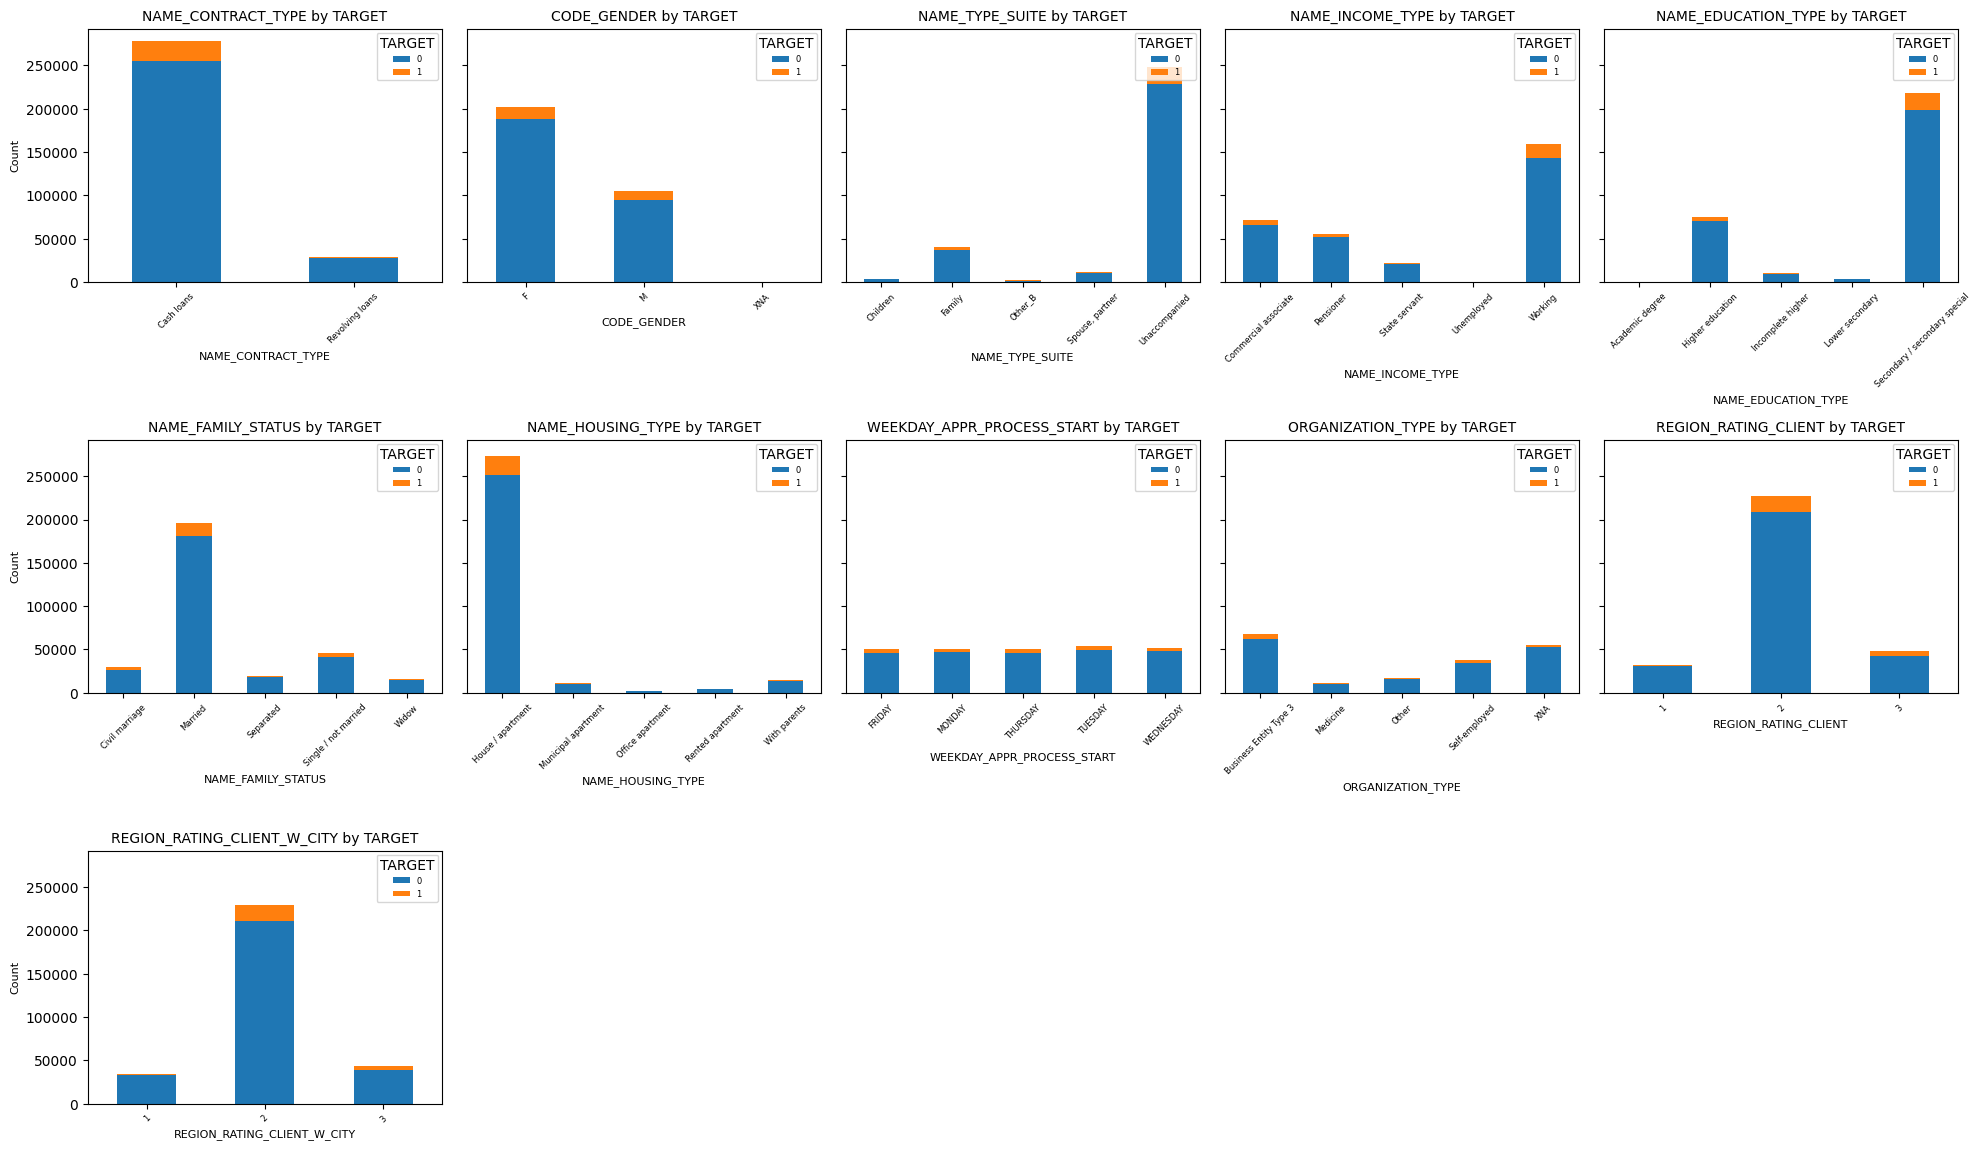

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define layout: 10 rows, 5 columns (adjust as needed)
n_rows = 10
n_cols = 5
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), sharey=True)

# Flatten axes for easier iteration (since it's a 2D array)
axes = axes.flatten()

# Plot each categorical column with stacked TARGET distribution
for i, col in enumerate(cols_to_plot[:n_rows * n_cols]):  # Limit to grid size (50 here)
    # Get top 5 categories to avoid clutter
    top_n = df_processed[col].value_counts().nlargest(5).index
    df_subset = df_processed[df_processed[col].isin(top_n)]

    # Create a crosstab of the column vs TARGET
    crosstab = pd.crosstab(df_subset[col], df_subset['TARGET'])

    # Plot stacked bar chart
    crosstab.plot(kind='bar', stacked=True, ax=axes[i], color=['#1f77b4', '#ff7f0e'])  # Colors for TARGET 0 and 1
    axes[i].set_title(f'{col} by TARGET', fontsize=10)
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Count', fontsize=8)
    axes[i].tick_params(axis='x', rotation=45, labelsize=6)
    axes[i].legend(title='TARGET', loc='upper right', fontsize=6)

# Hide any unused subplots (if < 46 columns or grid exceeds columns)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

# Adjust layout and save to file
plt.tight_layout()
plt.savefig('categorical_distributions.pdf', bbox_inches='tight', dpi=300)  # Save as PDF
plt.show()  # Optional: Display if your environment supports it

### **Try one-hot encoding**

In [ ]:
cols_to_one_hot_encode = cols_to_plot[:].copy()
df_one_hot_encoded = pd.get_dummies(df_processed, columns=cols_to_one_hot_encode)
print("Shape after one-hot encoding:", df_one_hot_encoded.shape)
print(df_one_hot_encoded.head())

Shape after one-hot encoding: (307511, 169)
   SK_ID_CURR  TARGET  FLAG_OWN_CAR  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  REGION_POPULATION_RELATIVE  ...  ORGANIZATION_TYPE_Transport: type 3  ORGANIZATION_TYPE_Transport: type 4  ORGANIZATION_TYPE_University  ORGANIZATION_TYPE_XNA  REGION_RATING_CLIENT_1  REGION_RATING_CLIENT_2  REGION_RATING_CLIENT_3  REGION_RATING_CLIENT_W_CITY_1  REGION_RATING_CLIENT_W_CITY_2  REGION_RATING_CLIENT_W_CITY_3
0      100002       1             0                1             0          202500.0    406597.5      24700.5         351000.0                    0.018801  ...                                False                                False                         False                  False                   False                    True                   False                          False                           True                          False
1      100003       0             0                0

In [ ]:
# Get all column names after encoding
categorical_one_hot_processed_cols = set(df_one_hot_encoded.columns.tolist()) - set(numerical_processed_cols) - set(['TARGET'])
categorical_one_hot_processed_cols = list(categorical_one_hot_processed_cols)

print(categorical_one_hot_processed_cols)

['NAME_INCOME_TYPE_Maternity leave', 'ORGANIZATION_TYPE_Industry: type 12', 'ORGANIZATION_TYPE_School', 'ORGANIZATION_TYPE_Business Entity Type 3', 'ORGANIZATION_TYPE_Industry: type 4', 'FLAG_DOCUMENT_6', 'REGION_RATING_CLIENT_1', 'NAME_TYPE_SUITE_Other_B', 'ORGANIZATION_TYPE_Trade: type 1', 'NAME_TYPE_SUITE_Children', 'NAME_TYPE_SUITE_Group of people', 'NAME_FAMILY_STATUS_Unknown', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_10', 'FLAG_EMAIL', 'NAME_EDUCATION_TYPE_Secondary / secondary special', 'ORGANIZATION_TYPE_Construction', 'FLAG_DOCUMENT_12', 'NAME_HOUSING_TYPE_Co-op apartment', 'ORGANIZATION_TYPE_Industry: type 7', 'ORGANIZATION_TYPE_Transport: type 3', 'WEEKDAY_APPR_PROCESS_START_MONDAY', 'ORGANIZATION_TYPE_Other', 'NAME_TYPE_SUITE_Family', 'NAME_HOUSING_TYPE_Rented apartment', 'ORGANIZATION_TYPE_Services', 'ORGANIZATION_TYPE_XNA', 'ORGANIZATION_TYPE_Transport: type 1', 'NAME_FAMILY_STATUS_Civil marriage', 'FLAG_PHONE', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_17', 'ORGANI

In [ ]:
X = df_one_hot_encoded[numerical_processed_cols + categorical_one_hot_processed_cols] # Features (excluding the target column)
y = df_one_hot_encoded['TARGET']  # Target variable


# Split the data into 80% training and 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
get_model_performance(X_train, y_train, X_val, y_val)

訓練集準確率: 0.9996469336653395
驗證集準確率: 0.8537515988466625
訓練集召回率: 0.9985037693502906
驗證集召回率: 0.170515574650913


### **Try Target Encoding**
all categorical columns target encode

In [ ]:
cols_to_target_encode = categorical_processed_cols[:].copy()

In [ ]:
X = df_processed[numerical_processed_cols + categorical_processed_cols] # Features (excluding the target column)
y = df_processed['TARGET']  # Target variable


# Split the data into 80% training and 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
from category_encoders import TargetEncoder

# Initialize TargetEncoder with smoothing
encoder = TargetEncoder(cols=cols_to_target_encode, smoothing=10.0)  # Smoothing for imbalance

# Fit and transform on training data
X_train_target = encoder.fit_transform(X_train, y_train)

# Transform test data
X_val_target = encoder.transform(X_val)

# Add non-categorical columns back (e.g., 'ID', 'Age')
non_categorical_cols = [col for col in X.columns if col not in categorical_processed_cols]
X_train_target[non_categorical_cols] = X_train[non_categorical_cols]
X_val_target[non_categorical_cols] = X_val[non_categorical_cols]

In [ ]:
get_model_performance(X_train_target, y_train, X_val_target, y_val)

訓練集準確率: 0.9995679583010076
驗證集準確率: 0.857567151559824
訓練集召回率: 0.9980433906888416
驗證集召回率: 0.15682062298603652


#### **Delete rows with few NaN values**

In [ ]:
df_processed = df_processed[df_processed['CODE_GENDER'] != 'N/A']

## **Feature Enginnering for Numerical**

#### **DAYS_EMPLOYED：365,243 轉為 0**

In [ ]:
df_processed.loc[df_processed['DAYS_EMPLOYED'] == 365243, 'DAYS_EMPLOYED'] = 0
df_processed[df_processed['DAYS_EMPLOYED'] == 365243]

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


#### **Drop 極端值**


In [ ]:
df_processed = df_processed[~(df_processed['AMT_INCOME_TOTAL'] > 100000000)]
df_processed[df_processed['AMT_INCOME_TOTAL'] > 100000000]

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


In [ ]:
df_processed = df_processed[~(df_processed['AMT_REQ_CREDIT_BUREAU_QRT'] > 200)]
df_processed[df_processed['AMT_REQ_CREDIT_BUREAU_QRT'] > 200]

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


#### **Missing Values**
1. **For AMT_REQ_CREDIT_BUREAU 相關欄位，新增 missing 欄位 + 補上 0** (一個缺就所有欄位都缺）

In [ ]:
high_missing_cols = [ #'EXT_SOURCE_3',
    'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_YEAR'
]

df_imputed = df_processed.copy()
# Add missing indicator
df_imputed['AMT_REQ_CREDIT_BUREAU_is_missing'] = df_imputed['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().astype(int)

for col in high_missing_cols:
  # Impute with 0
  df_imputed[col] = df_imputed[col].fillna(0)

In [ ]:
X = pd.concat([df_one_hot_encoded[categorical_one_hot_processed_cols], df_imputed[numerical_processed_cols]], axis=1)

y = df_one_hot_encoded['TARGET']  # Target variable

# Split the data into 80% training and 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
get_model_performance(X_train, y_train, X_val, y_val)

訓練集準確率: 0.9997212634200049
驗證集準確率: 0.8529277863290481
訓練集召回率: 0.9981009380215227
驗證集召回率: 0.17400644468313642


2. **EXT_SOURCE_3: 看與 source 1 評分的關係 決定如何補值**
- 與 source 1 若相關 0.1

In [ ]:
df_subset_notnull = df_processed[(df_processed['EXT_SOURCE_2'] != np.nan) & (df_processed['EXT_SOURCE_3'] != np.nan)]

In [ ]:
df_subset = df_subset_notnull[['EXT_SOURCE_2', 'EXT_SOURCE_3']]
import seaborn as sns
from sklearn.feature_selection import mutual_info_regression

# Pearson Correlation
print("Pearson Correlation:")
print(df_subset.corr())

# Spearman Correlation
print("\nSpearman Correlation:")
print(df_subset.corr(method='spearman'))

# Mutual Information
df_complete = df_subset.dropna()
mi = mutual_info_regression(df_complete[['EXT_SOURCE_2']], df_complete['EXT_SOURCE_3'])
print("\nMutual Information with EXT_SOURCE_3:")
print("EXT_SOURCE_2:", mi[0])

Pearson Correlation:
              EXT_SOURCE_2  EXT_SOURCE_3
EXT_SOURCE_2      1.000000      0.109153
EXT_SOURCE_3      0.109153      1.000000

Spearman Correlation:
              EXT_SOURCE_2  EXT_SOURCE_3
EXT_SOURCE_2      1.000000      0.106173
EXT_SOURCE_3      0.106173      1.000000

Mutual Information with EXT_SOURCE_3:
EXT_SOURCE_2: 0.005152417391291131


 **3. AMT_ANNUITY & AMT_GOODS_PRICE**

 AMT_ANNUITY 缺失 rows 可以刪除（因 target 皆為 0）

 AMT_GOOD_PRICE 可用 AMT_CREDIT 補，或刪除

In [ ]:
df_processed = df_processed[~(df_processed['AMT_ANNUITY'].isna())]
df_processed[df_processed['AMT_ANNUITY'].isna()]

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR


In [ ]:
numerical_processed_cols.remove('AMT_GOODS_PRICE')

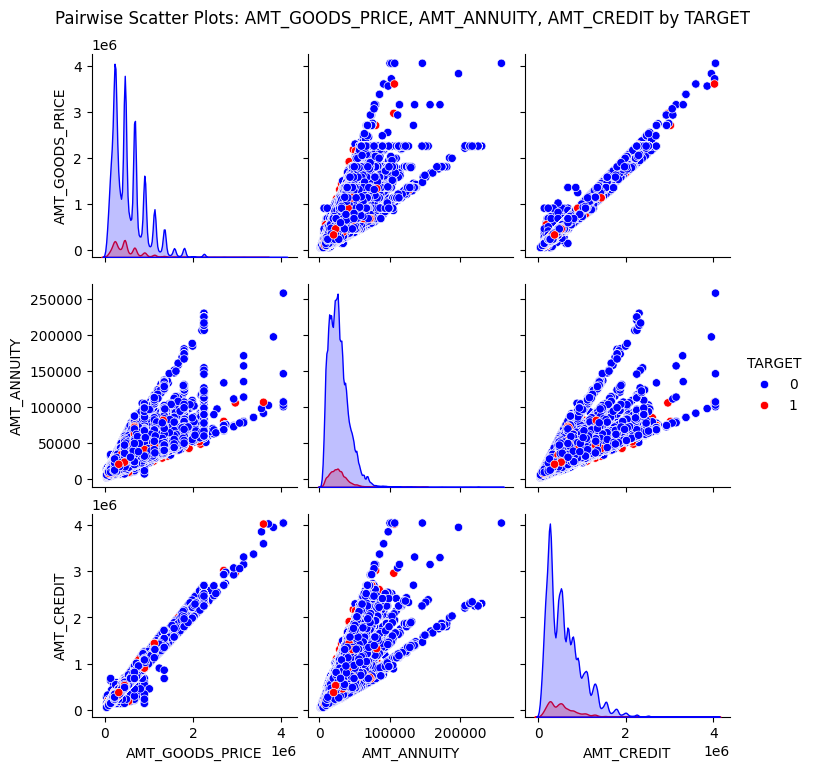

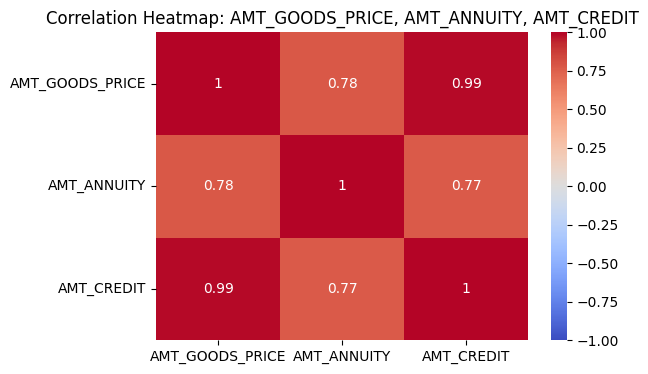

Pearson Correlation Matrix:
                 AMT_GOODS_PRICE  AMT_ANNUITY  AMT_CREDIT
AMT_GOODS_PRICE         1.000000     0.775111    0.986968
AMT_ANNUITY             0.775111     1.000000    0.769941
AMT_CREDIT              0.986968     0.769941    1.000000


In [ ]:
# Subset the three columns plus TARGET, drop rows with NaN in the three variables
df_subset = df_processed[['AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_CREDIT', 'TARGET']].dropna()

# 1. Scatter Plot with TARGET coloring
sns.pairplot(df_subset, hue='TARGET', palette={0: 'blue', 1: 'red'})
plt.suptitle("Pairwise Scatter Plots: AMT_GOODS_PRICE, AMT_ANNUITY, AMT_CREDIT by TARGET", y=1.02)
plt.show()

# 2. Correlation Matrix (excluding TARGET)
corr_matrix = df_subset[['AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_CREDIT']].corr()

# Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Heatmap: AMT_GOODS_PRICE, AMT_ANNUITY, AMT_CREDIT")
plt.show()

# Print correlation matrix
print("Pearson Correlation Matrix:")
print(corr_matrix)

4. **社交網絡逾期分析變數**

缺失的是同一群人

In [ ]:
df_processed.loc[df_processed['OBS_30_CNT_SOCIAL_CIRCLE'].isna(),
                          ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE']].head(10)

,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE
68,NaN,NaN,NaN,NaN
394,NaN,NaN,NaN,NaN
397,NaN,NaN,NaN,NaN
457,NaN,NaN,NaN,NaN
1042,NaN,NaN,NaN,NaN
1064,NaN,NaN,NaN,NaN
1156,NaN,NaN,NaN,NaN
1209,NaN,NaN,NaN,NaN
1486,NaN,NaN,NaN,NaN
1743,NaN,NaN,NaN,NaN


In [ ]:
df_processed.loc[df_processed['OBS_30_CNT_SOCIAL_CIRCLE'].isna(), 'TARGET'].value_counts()

,count
TARGET,
0,985
1,36


In [ ]:
df_processed.isna().sum().to_frame().sort_values(by=0, ascending=False)

,0
EXT_SOURCE_3,60964
AMT_REQ_CREDIT_BUREAU_MON,41519
AMT_REQ_CREDIT_BUREAU_DAY,41519
AMT_REQ_CREDIT_BUREAU_QRT,41519
AMT_REQ_CREDIT_BUREAU_HOUR,41519
AMT_REQ_CREDIT_BUREAU_WEEK,41519
AMT_REQ_CREDIT_BUREAU_YEAR,41519
NAME_TYPE_SUITE,1292
OBS_30_CNT_SOCIAL_CIRCLE,1021
DEF_30_CNT_SOCIAL_CIRCLE,1021


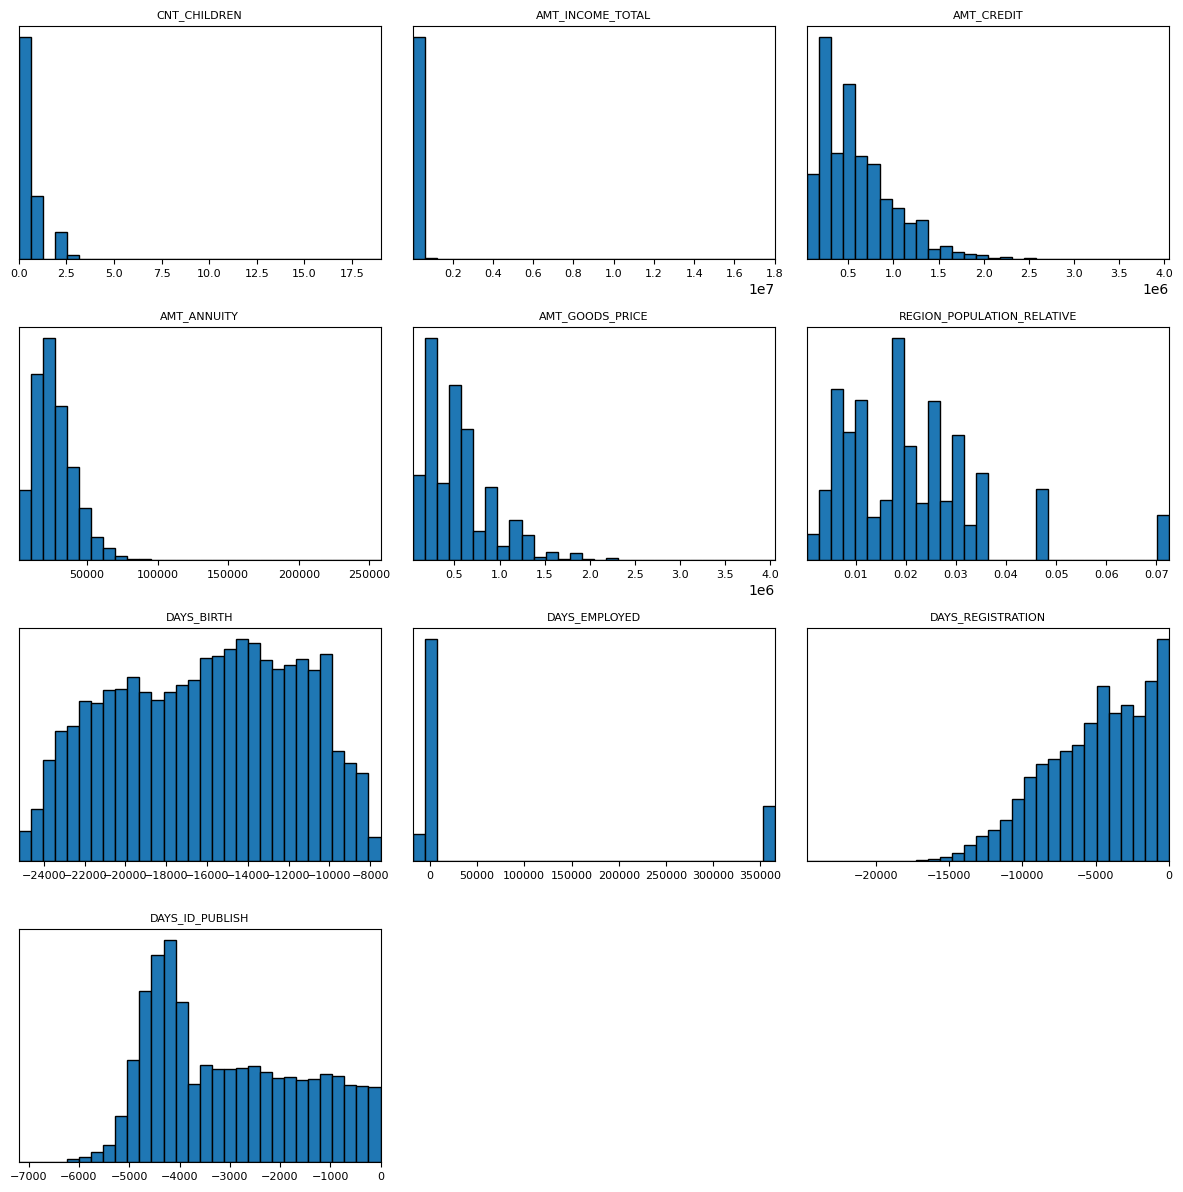

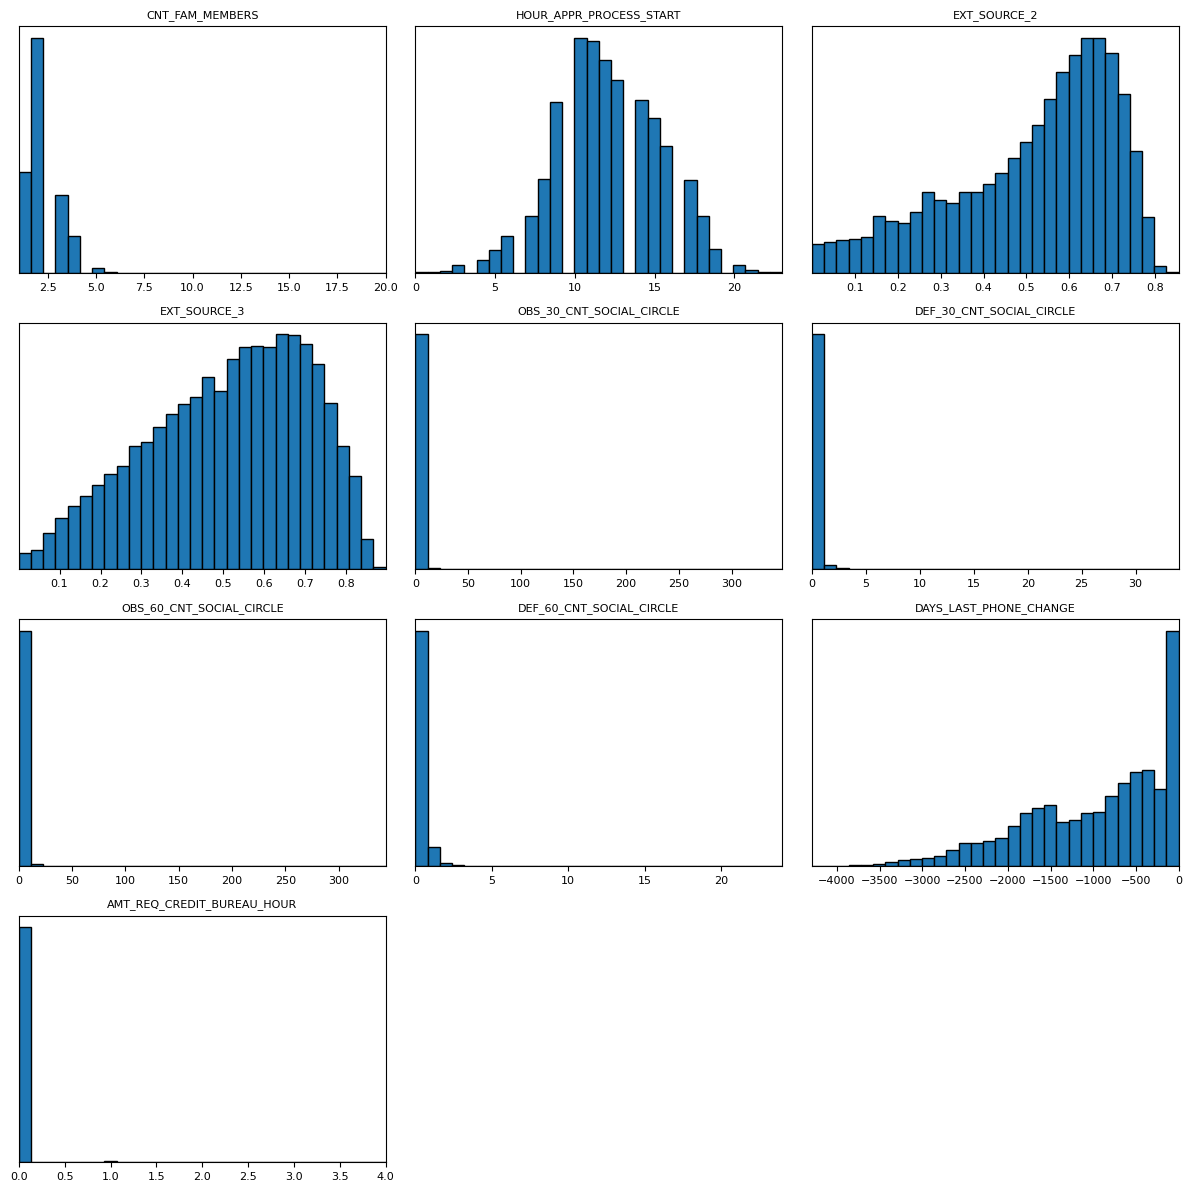

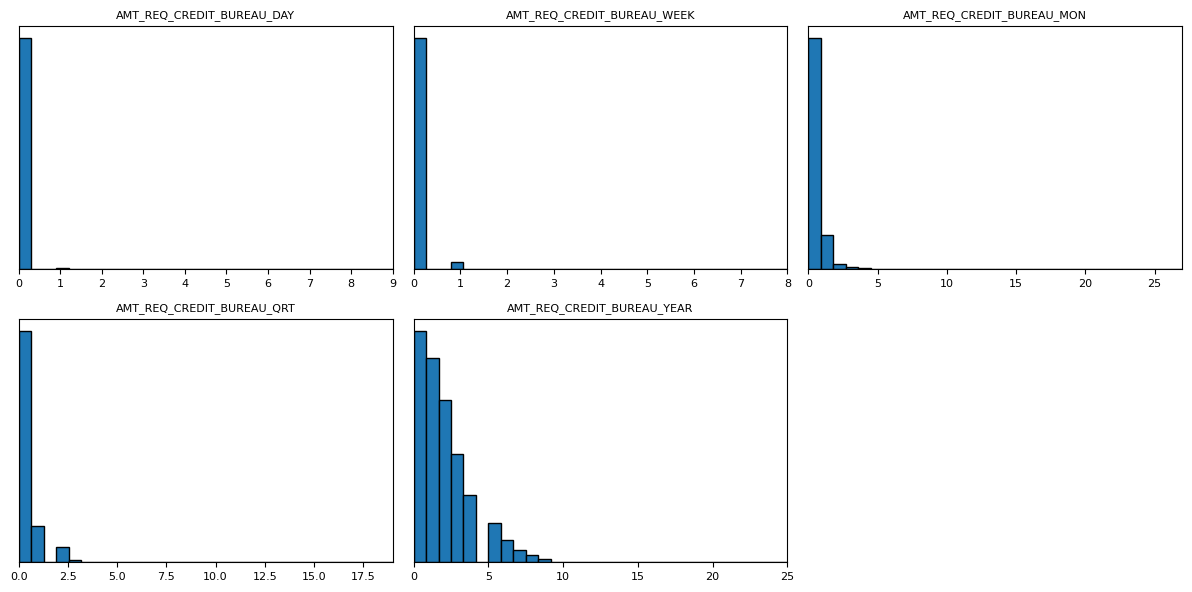

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cols_per_fig = 10  # Number of columns per figure
rows_per_fig = 3   # Number of rows per figure (adjust based on preference)

# Iterate over numerical features in batches
for i in range(0, len(numerical_processed_cols), cols_per_fig):
    subset = numerical_processed_cols[i:i+cols_per_fig]  # Take a subset of columns

    # Calculate the number of rows needed
    n_cols = len(subset)
    n_rows = (n_cols + rows_per_fig - 1) // rows_per_fig  # Calculate the necessary number of rows

    # Make the figure smaller by reducing the overall size
    fig, axes = plt.subplots(nrows=n_rows, ncols=rows_per_fig, figsize=(12, n_rows*3))

    # Flatten axes to make iteration easier
    axes = axes.flatten()

    # Plot each column in the subset
    for j, col in enumerate(subset):
        ax = axes[j]
        ax.hist(df_processed[col], bins=30, edgecolor='black')
        ax.set_title(col, fontsize=8)  # Smaller title font
        ax.set_xlim(df_processed[col].min(), df_processed[col].max())  # Set x-axis to min-max range
        ax.set_yticks([])  # Hide y-axis ticks for a cleaner look
        ax.tick_params(axis='both', labelsize=8)  # Smaller axis labels

    # Hide any unused subplots (if there are any extra axes)
    for j in range(n_cols, len(axes)):
        axes[j].axis('off')

    plt.tight_layout(pad=1.0)  # Adjust spacing between plots
    plt.show()

#### **Handling NaN**

In [ ]:
df_numerical.isna().sum().to_frame().sort_values(by=0, ascending=False)

,0
FLOORSMAX_AVG,153020
FLOORSMAX_MODE,153020
FLOORSMAX_MEDI,153020
YEARS_BEGINEXPLUATATION_AVG,150007
YEARS_BEGINEXPLUATATION_MEDI,150007
YEARS_BEGINEXPLUATATION_MODE,150007
TOTALAREA_MODE,148431
EXT_SOURCE_3,60965
AMT_REQ_CREDIT_BUREAU_DAY,41519
AMT_REQ_CREDIT_BUREAU_HOUR,41519



這三個欄位看不懂 + 缺失值快一半（不懂為什麼開發時間會有 avg, median, mode）
- YEARS_BEGINEXPLUATATION_AVG
- YEARS_BEGINEXPLUATATION_MEDI
- YEARS_BEGINEXPLUATATION_MODE

快 50% 的缺失值：
- FLOORSMAX_AVG
- FLOORSMAX_MODE
- FLOORSMAX_MEDI
- TOTALAREA_MODE

> 這些都可以 drop 試試

**Try dropping above columns**

In [ ]:
numerical_cols_to_drop = ['YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BEGINEXPLUATATION_MODE', 'FLOORSMAX_AVG', 'FLOORSMAX_MODE', 'FLOORSMAX_MEDI', 'TOTALAREA_MODE']
numerical_processed_cols_after_drop = list(set(numerical_processed_cols) - set(numerical_cols_to_drop))

In [ ]:
df_numerical = df_processed[numerical_processed_cols_after_drop]
# Assume X is your feature set and y is your target variable
X = df_numerical  # Features (excluding the target column)
y = df_processed['TARGET']  # Target variable


# Split the data into 80% training and 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

#### **After dropping above columns**
驗證集 recall 有上升 0.00x >> 沒差太多所以應該可以 drop, since already overfitting

In [ ]:
get_model_performance(X_train, y_train, X_val, y_val)

訓練集準確率: 0.9995215022043418
驗證集準確率: 0.8588028703362456
訓練集召回率: 0.9969561222145646
驗證集召回率: 0.14567035338548692


#### **Imputing Missing Values**
Since we have an imbalanced dataset
- have to make sure imputing in the right way, so it doesn't dilute the minority class (target = 1)
- **想要先畫出各個 numerical feature pairs 的 scatter plot, 並標上 target = 1 or 0 顏色來觀察 target 有沒有什麼特殊分佈**

In [ ]:
df_numerical.isna().sum().to_frame().sort_values(by=0, ascending=False)

,0
EXT_SOURCE_3,60965
AMT_REQ_CREDIT_BUREAU_HOUR,41519
AMT_REQ_CREDIT_BUREAU_QRT,41519
AMT_REQ_CREDIT_BUREAU_WEEK,41519
AMT_REQ_CREDIT_BUREAU_MON,41519
AMT_REQ_CREDIT_BUREAU_DAY,41519
AMT_REQ_CREDIT_BUREAU_YEAR,41519
DEF_30_CNT_SOCIAL_CIRCLE,1021
OBS_60_CNT_SOCIAL_CIRCLE,1021
DEF_60_CNT_SOCIAL_CIRCLE,1021


In [ ]:
df_numerical = df_processed[numerical_processed_cols_after_drop + ['TARGET']]

找出重要的 feature 畫圖 >> 好像滿沒用的


In [ ]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns

# Assuming df_numerical is your dataframe with numerical columns and 'TARGET' column
X = df_numerical.drop('TARGET', axis=1)
y = df_numerical['TARGET']

# Train a Random Forest model to compute feature importance
rf = RandomForestClassifier(class_weight='balanced')
rf.fit(X, y)

# Get feature importance and sort them
feature_importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Select top N important features (e.g., top 5)
top_n_cols = feature_importances.head(5).index

# You can now create pairs of features from the top N columns
feature_pairs = [(top_n_cols[i], top_n_cols[j]) for i in range(len(top_n_cols)) for j in range(i+1, len(top_n_cols))]

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


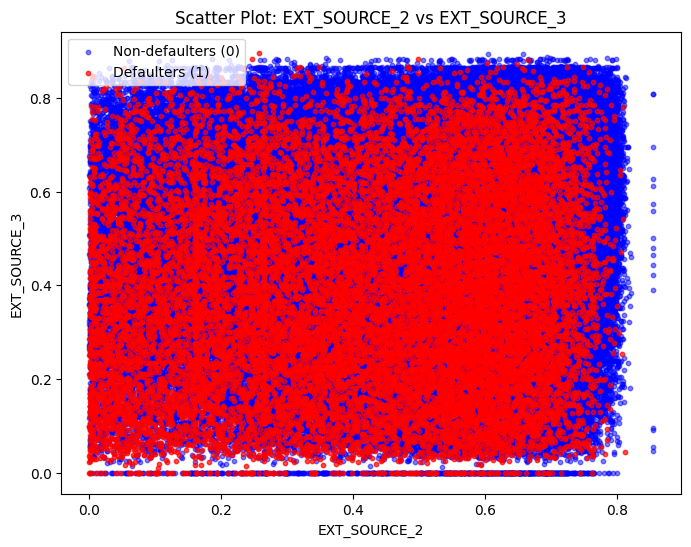

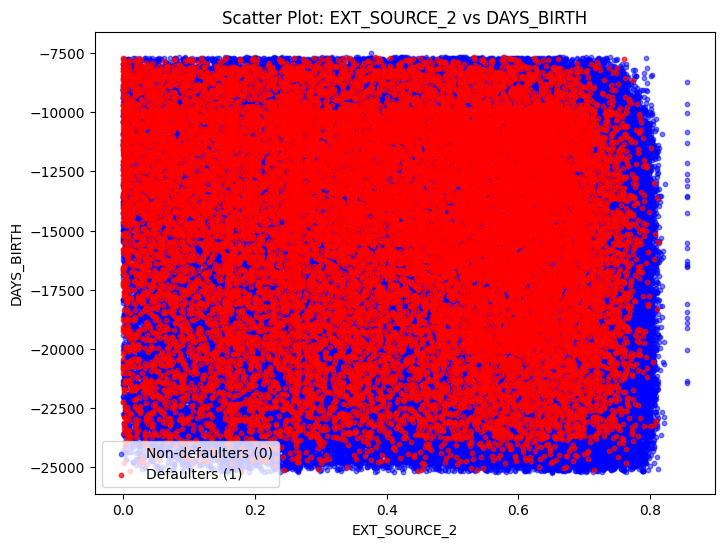

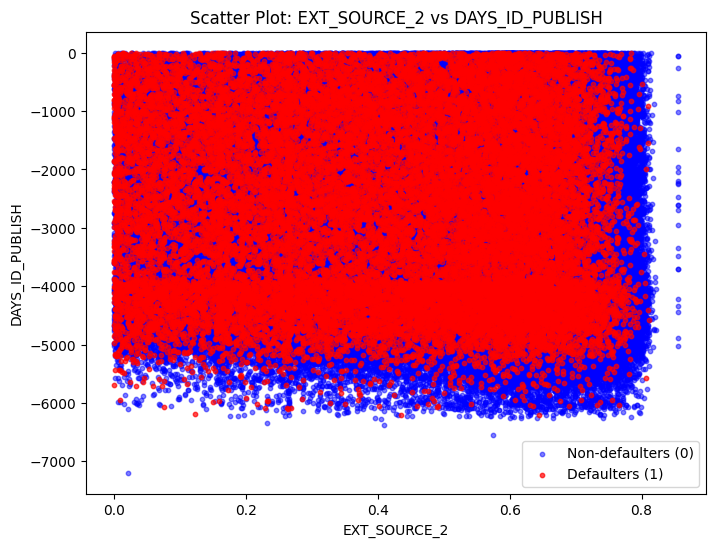

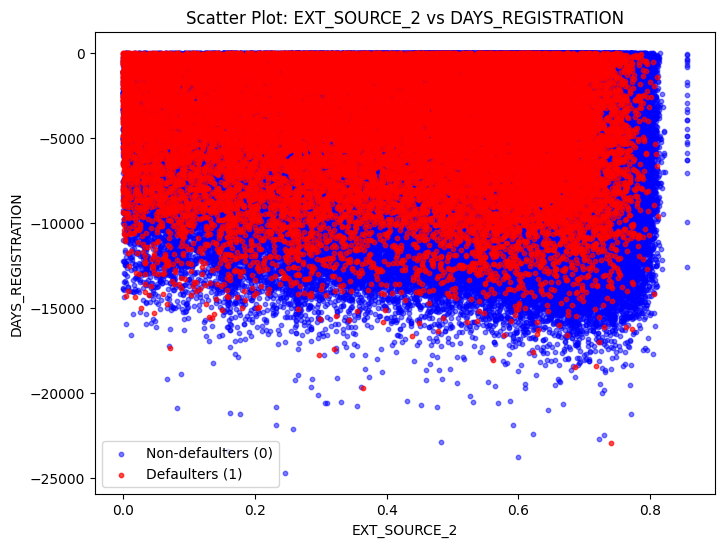

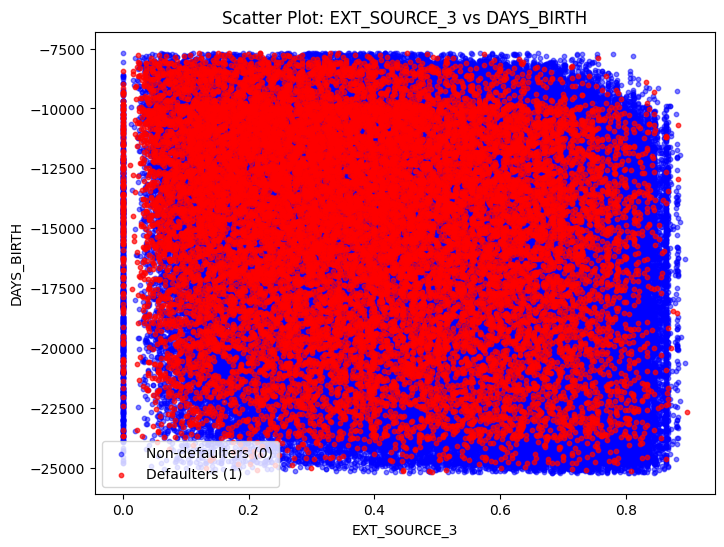

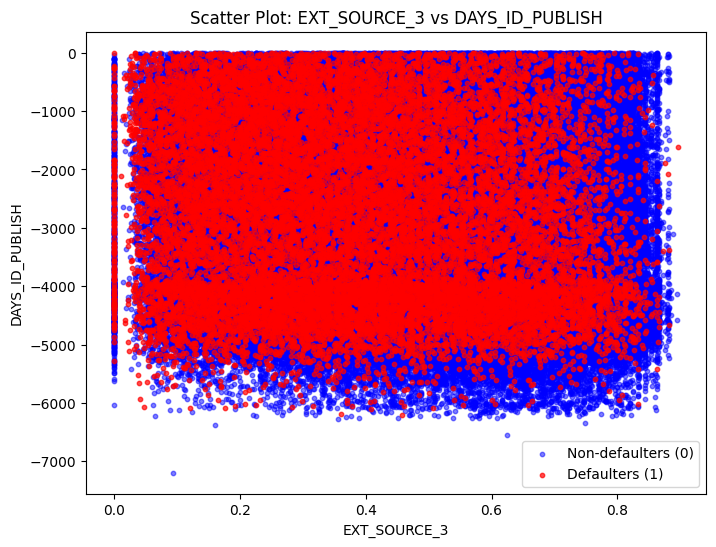

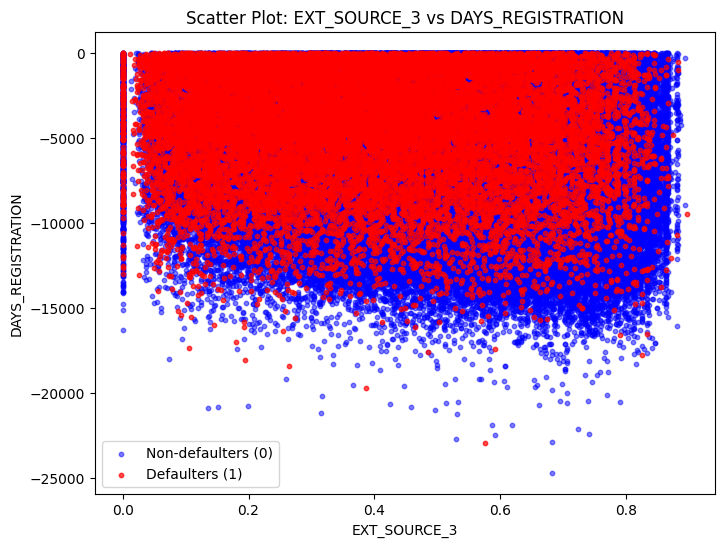

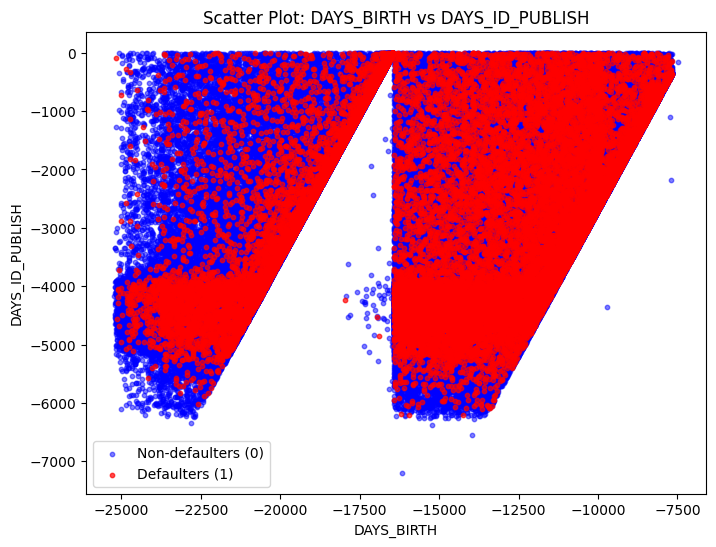

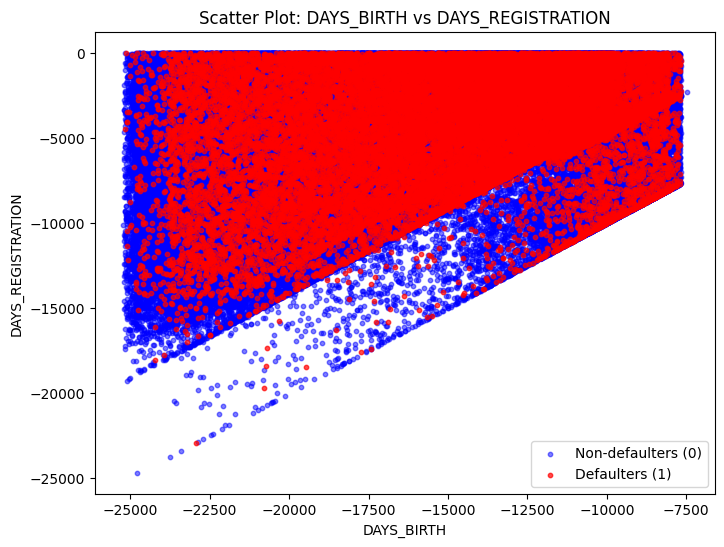

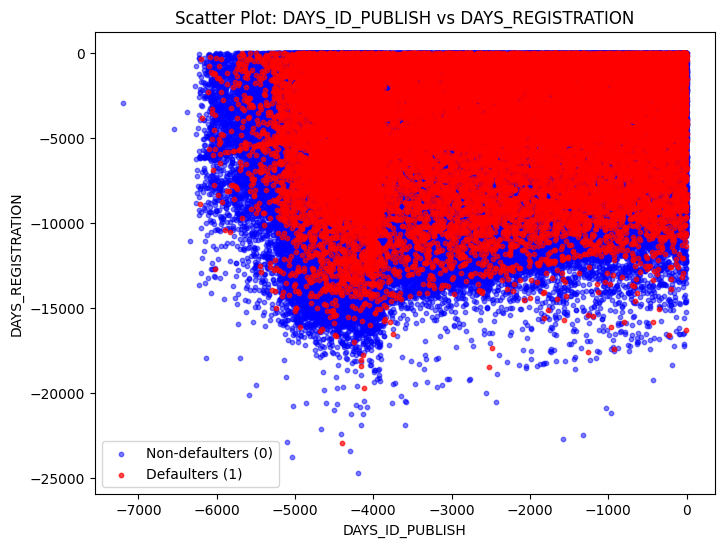

In [ ]:
# Plotting scatter plots for pairs of important features
for feature1, feature2 in feature_pairs:
    plt.figure(figsize=(8, 6))

    # Scatter plot for target = 0
    plt.scatter(df_numerical[df_numerical['TARGET'] == 0][feature1],
                df_numerical[df_numerical['TARGET'] == 0][feature2],
                label='Non-defaulters (0)', alpha=0.5, s=10, color='blue')

    # Scatter plot for target = 1
    plt.scatter(df_numerical[df_numerical['TARGET'] == 1][feature1],
                df_numerical[df_numerical['TARGET'] == 1][feature2],
                label='Defaulters (1)', alpha=0.7, s=10, color='red')

    # Set labels and title
    plt.xlabel(feature1)
    plt.ylabel(feature2)
    plt.title(f"Scatter Plot: {feature1} vs {feature2}")
    plt.legend()
    plt.show()


### **Feature Transformation & Scaling**
- Most variables are skewed
- Outliers detection are needed